In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
"""CGAP statistical significance testing (Kaggle script).
Participant is the inferential unit; seeds are averaged within participant.
Friedman omnibus + paired Wilcoxon (CGAP Full vs each variant) + Holm + bootstrap CI
+ rank-biserial effect + sign-flip permutation sensitivity.
"""
# 1. Setup
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from scipy.stats import friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests

# ---- Kaggle paths -------------------------------------------------------
# Leave RESULTS_FILE = None to auto-search /kaggle/input for the CSV.
# Or set it explicitly, e.g. Path('/kaggle/input/<your-dataset>/ablation_results_checkpoint.csv')
RESULTS_FILE = None
CSV_NAMES = ['results_by_seed.csv', 'ablation_results_checkpoint.csv']  # first match wins
OUTPUT_DIR = Path('/kaggle/working/statistical_significance')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if RESULTS_FILE is None:
    hits = []
    for name in CSV_NAMES:
        hits += sorted(Path('/kaggle/input').rglob(name)) + sorted(Path('.').rglob(name))
    # prefer the ablation folder (needs all 5 variants), e.g. cgap_fast_ablation_checkpoints/.../results_by_seed.csv
    hits.sort(key=lambda p: 'ablation' not in str(p).lower())
    assert hits, f'None of {CSV_NAMES} found under /kaggle/input. Set RESULTS_FILE manually.'
    print('Candidate files:', *map(str, hits), sep='\n  ')
    RESULTS_FILE = hits[0]
RESULTS_FILE = Path(RESULTS_FILE)
assert RESULTS_FILE.exists(), f'CSV not found: {RESULTS_FILE}'

N_BOOT = 20000
N_PERM = 50000
ALPHA = 0.05
REFERENCE_MODEL = 'CGAP Full'
MODEL_ORDER = ['CGAP Full', 'Global only', 'Online only',
               'CGAP no online updates', 'CGAP no class weights']
METRIC_ALIASES = {
    'accuracy': ['accuracy', 'acc'],
    'balanced_accuracy': ['balanced_accuracy', 'balanced_acc'],
    'macro_f1': ['macro_f1', 'f1_macro', 'macro-f1'],
    'macro_precision': ['macro_precision', 'precision_macro'],
    'macro_recall': ['macro_recall', 'recall_macro'],
}
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)
def display(x): print(x.to_string() if hasattr(x, 'to_string') else x)

raw = pd.read_csv(RESULTS_FILE)
print('Using:', RESULTS_FILE)
print('Input shape:', raw.shape)
print('Columns:', raw.columns.tolist())
display(raw.head())


# 2. Detect and standardise columns
def norm(s):
    return ''.join(c.lower() for c in str(s) if c.isalnum())

def find_col(columns, aliases, required=True):
    lookup = {norm(c): c for c in columns}
    for a in aliases:
        if norm(a) in lookup:
            return lookup[norm(a)]
    if required:
        raise ValueError(f'Cannot find column matching {aliases}. Available: {list(columns)}')
    return None

model_col = find_col(raw.columns, ['model', 'variant', 'model_name'])
seed_col = find_col(raw.columns, ['seed', 'random_seed'])
subject_col = find_col(raw.columns, ['held_out_subject', 'subject', 'heldout_subject',
                                     'test_subject', 'participant', 'held_out'], required=False)
fold_col = find_col(raw.columns, ['fold', 'outer_fold'], required=False)
metric_cols = {m: find_col(raw.columns, aliases, required=False)
               for m, aliases in METRIC_ALIASES.items()}
metric_cols = {m:c for m,c in metric_cols.items() if c is not None}
if not metric_cols:
    raise ValueError('No metric columns recognised. Update METRIC_ALIASES to match the CSV.')

rename = {model_col:'model', seed_col:'seed'}
if subject_col: rename[subject_col] = 'subject'
if fold_col: rename[fold_col] = 'fold'
rename.update({c:m for m,c in metric_cols.items()})
df = raw.rename(columns=rename).copy()

# If subject ID is absent, do not silently assume folds are subjects unless one-to-one mapping is verified.
if 'subject' not in df.columns:
    if 'fold' not in df.columns:
        raise ValueError('Need held-out participant column or a fold column mapping one-to-one to participants.')
    map_check = df.groupby('fold')['model'].nunique()
    print('No subject column. Fold mapping diagnostic:', map_check.to_dict())
    df['subject'] = df['fold'].astype(str)
    warnings.warn('Using fold as participant identifier. Verify each LOSO fold maps to exactly one unique participant.')

df['model'] = df['model'].astype(str).str.strip()
df['subject'] = df['subject'].astype(str).str.strip()
df['seed'] = pd.to_numeric(df['seed'], errors='raise').astype(int)
metrics = list(metric_cols.keys())
for m in metrics:
    df[m] = pd.to_numeric(df[m], errors='coerce')
df = df.dropna(subset=['model','subject','seed'] + metrics)

print('Detected metrics:', metrics)
print('Models:', sorted(df.model.unique()))
print('Seeds:', sorted(df.seed.unique()))
print('Subjects:', sorted(df.subject.unique()))
display(pd.DataFrame({'metric':list(metric_cols), 'source_column':list(metric_cols.values())}))

# 3. Validate uniqueness and coverage
key = ['seed','subject','model']
dups = df[df.duplicated(key, keep=False)]
if not dups.empty:
    display(dups.sort_values(key))
    raise ValueError('Duplicate seed × subject × model rows. Resolve before significance tests.')

coverage = df.groupby(['model','subject'])['seed'].nunique().unstack(fill_value=0)
print('Seed coverage (normally 3 for every model and subject):')
display(coverage)
if (coverage != 3).any().any():
    warnings.warn('Incomplete seed coverage detected. The paired analysis below will keep only complete participant blocks.')

models = [m for m in MODEL_ORDER if m in df.model.unique()]
models += [m for m in sorted(df.model.unique()) if m not in models]
print('Models included:', models)

# Average across seeds within each participant × model; participant is the inferential unit.
participant = df.groupby(['subject','model'], as_index=False)[metrics].mean()
participant.to_csv(OUTPUT_DIR / 'participant_means_across_seeds.csv', index=False)

def wide_metric(metric):
    w = participant.pivot(index='subject', columns='model', values=metric)
    use = [m for m in models if m in w.columns]
    return w[use].dropna(axis=0, how='any')

desc = []
for m in models:
    for metric in metrics:
        vals = participant.loc[participant.model.eq(m), metric].dropna()
        desc.append({'model':m,'metric':metric,'n_participants':len(vals),
                     'mean':vals.mean(),'sd':vals.std(ddof=1),'median':vals.median(),
                     'min':vals.min(),'max':vals.max()})
descriptive = pd.DataFrame(desc)
display(descriptive.round(4))
descriptive.to_csv(OUTPUT_DIR / 'descriptive_statistics.csv', index=False)

# 4. Helpers: paired bootstrap CI, rank-biserial effect size, robust Wilcoxon
def bootstrap_ci(d, n_boot=N_BOOT, seed=12345, conf=0.95):
    d = np.asarray(d, float)
    d = d[np.isfinite(d)]
    if not len(d): return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    # Resample participants' paired differences.
    means = np.empty(n_boot)
    for start in range(0, n_boot, 1000):
        n = min(1000, n_boot-start)
        means[start:start+n] = rng.choice(d, size=(n,len(d)), replace=True).mean(axis=1)
    q = (1-conf)/2
    return float(np.quantile(means,q)), float(np.quantile(means,1-q))

def rank_biserial(d):
    d = np.asarray(d,float)
    d = d[np.isfinite(d) & (np.asarray(d) != 0)]
    if not len(d): return 0.0
    ranks = pd.Series(np.abs(d)).rank(method='average').to_numpy()
    plus, minus = ranks[d>0].sum(), ranks[d<0].sum()
    return float((plus-minus)/(plus+minus)) if plus+minus else 0.0

def paired_wilcoxon(a,b):
    d = np.asarray(a,float)-np.asarray(b,float)
    if len(d)<2 or np.allclose(d,0): return 0.0,1.0,d
    try:
        r = wilcoxon(d, alternative='two-sided', zero_method='wilcox', method='auto')
    except TypeError:
        r = wilcoxon(d, alternative='two-sided', zero_method='wilcox', mode='auto')
    return float(r.statistic),float(r.pvalue),d

# 5. Friedman omnibus test across model variants
friedman_rows = []
for metric in metrics:
    w = wide_metric(metric)
    if w.shape[1] < 3 or w.shape[0] < 3:
        warnings.warn(f'Skipping Friedman for {metric}: insufficient complete models/participants.')
        continue
    stat,p = friedmanchisquare(*[w[m].to_numpy() for m in w.columns])
    n,k = w.shape
    # Kendall's W effect size for Friedman.
    friedman_rows.append({'metric':metric,'n_participants':n,'n_models':k,
                          'friedman_chi2':float(stat),'p_value':float(p),
                          'kendalls_W':float(stat/(n*(k-1)))})
friedman = pd.DataFrame(friedman_rows)
display(friedman.round(6))
friedman.to_csv(OUTPUT_DIR / 'friedman_omnibus.csv', index=False)

# 6. Planned post-hoc comparisons: CGAP Full vs each other model
# Holm correction is applied across the comparator family separately for each metric.
posthoc_rows = []
for metric in metrics:
    w = wide_metric(metric)
    if REFERENCE_MODEL not in w.columns:
        warnings.warn(f'{REFERENCE_MODEL} missing for {metric}; skipping.')
        continue
    ref = w[REFERENCE_MODEL].to_numpy()
    rows = []
    for comp_model in [m for m in w.columns if m != REFERENCE_MODEL]:
        comp = w[comp_model].to_numpy()
        stat,p,d = paired_wilcoxon(ref,comp)
        lo,hi = bootstrap_ci(d)
        rows.append({'metric':metric,'reference_model':REFERENCE_MODEL,
                     'comparison_model':comp_model,'n_participants':len(d),
                     'reference_mean':float(ref.mean()),'comparison_mean':float(comp.mean()),
                     'mean_difference_CGAP_minus_comparator':float(d.mean()),
                     'median_difference':float(np.median(d)),
                     'bootstrap_95ci_low':lo,'bootstrap_95ci_high':hi,
                     'wilcoxon_statistic':stat,'p_raw':p,
                     'rank_biserial_effect':rank_biserial(d)})
    if rows:
        reject,padj,_,_ = multipletests([r['p_raw'] for r in rows], alpha=ALPHA, method='holm')
        for r,pa,re in zip(rows,padj,reject):
            r['p_holm'] = float(pa)
            r['significant_holm_0_05'] = bool(re)
            posthoc_rows.append(r)
posthoc = pd.DataFrame(posthoc_rows)
display(posthoc.round(6))
posthoc.to_csv(OUTPUT_DIR / 'wilcoxon_posthoc_holm.csv', index=False)

# 7. Sign-flip permutation sensitivity test on paired participant differences
def sign_flip_p(d, n_perm=N_PERM, seed=2026):
    d = np.asarray(d,float)
    d = d[np.isfinite(d)]
    if not len(d): return np.nan
    observed = abs(d.mean())
    rng = np.random.default_rng(seed)
    exceed = 0
    done = 0
    while done < n_perm:
        b = min(5000,n_perm-done)
        signs = rng.choice([-1.0,1.0],size=(b,len(d)))
        exceed += int((np.abs((signs*d).mean(axis=1)) >= observed).sum())
        done += b
    return (exceed+1)/(n_perm+1)

perm_rows=[]
for metric in metrics:
    w=wide_metric(metric)
    if REFERENCE_MODEL not in w.columns: continue
    for comp_model in [m for m in w.columns if m != REFERENCE_MODEL]:
        d=w[REFERENCE_MODEL].to_numpy()-w[comp_model].to_numpy()
        perm_rows.append({'metric':metric,'reference_model':REFERENCE_MODEL,
                          'comparison_model':comp_model,'n_participants':len(d),
                          'mean_difference':float(d.mean()),
                          'sign_flip_p_raw':float(sign_flip_p(d))})
perm=pd.DataFrame(perm_rows)
display(perm.round(6))
perm.to_csv(OUTPUT_DIR/'sign_flip_permutation_supplementary.csv',index=False)

# 8. Save paired values and a concise audit report
for metric in metrics:
    wide_metric(metric).to_csv(OUTPUT_DIR / f'paired_values_{metric}.csv')

lines = [
    'CGAP Statistical Significance Analysis',
    f'Input CSV: {RESULTS_FILE}',
    f'Input rows: {len(raw)}',
    f'Participants represented: {df.subject.nunique()}',
    f'Seeds represented: {sorted(df.seed.unique().tolist())}',
    f'Models: {models}',
    '',
    'Analysis unit: participant. Seeds averaged within participant before testing.',
    'Friedman is the omnibus test; Wilcoxon tests compare CGAP Full with each comparator.',
    'Holm adjustment is applied separately for each metric across its post-hoc comparisons.',
    'Bootstrap confidence intervals are for paired participant-level mean differences.',
    'Positive CGAP-minus-comparator differences favor CGAP when higher metric values are better.',
    'Do not interpret missing/incomplete participant coverage as a completed 15-subject experiment.',
    '',
    'Output files:'
] + [f'- {p.name}' for p in sorted(OUTPUT_DIR.glob('*.csv'))]
(OUTPUT_DIR/'README_analysis.txt').write_text('\n'.join(lines),encoding='utf-8')
print('\n'.join(lines))
print('All outputs saved to:', OUTPUT_DIR)

Candidate files:
  /kaggle/input/datasets/kabil08/checkpoints/cgap_fast_ablation_checkpoints-20261027T050652Z-1-001/cgap_fast_ablation_checkpoints/results_by_seed.csv
Using: /kaggle/input/datasets/kabil08/checkpoints/cgap_fast_ablation_checkpoints-20261027T050652Z-1-001/cgap_fast_ablation_checkpoints/results_by_seed.csv
Input shape: (15, 10)
Columns: ['seed', 'held_out_subject', 'model', 'best_inner_macro_f1', 'best_params', 'accuracy', 'balanced_accuracy', 'macro_f1', 'macro_precision', 'macro_recall']
   seed held_out_subject                   model  best_inner_macro_f1                                                                                               best_params  accuracy  balanced_accuracy  macro_f1  macro_precision  macro_recall
0    17               S9               CGAP Full             0.944529  {"tree_max_features": 0.8, "tree_min_samples_leaf": 2, "sgd_alpha": 0.0001, "online_blend_weight": 0.75}  0.926267           0.909074  0.915323         0.925900      0.909074

/tmp/ipykernel_49/3903057303.py:184: UserWarning: Skipping Friedman for accuracy: insufficient complete models/participants.
  warnings.warn(f'Skipping Friedman for {metric}: insufficient complete models/participants.')
/tmp/ipykernel_49/3903057303.py:184: UserWarning: Skipping Friedman for balanced_accuracy: insufficient complete models/participants.
  warnings.warn(f'Skipping Friedman for {metric}: insufficient complete models/participants.')
/tmp/ipykernel_49/3903057303.py:184: UserWarning: Skipping Friedman for macro_f1: insufficient complete models/participants.
  warnings.warn(f'Skipping Friedman for {metric}: insufficient complete models/participants.')
/tmp/ipykernel_49/3903057303.py:184: UserWarning: Skipping Friedman for macro_precision: insufficient complete models/participants.
  warnings.warn(f'Skipping Friedman for {metric}: insufficient complete models/participants.')
/tmp/ipykernel_49/3903057303.py:184: UserWarning: Skipping Friedman for macro_recall: insufficient compl

               metric reference_model        comparison_model  n_participants  reference_mean  comparison_mean  mean_difference_CGAP_minus_comparator  median_difference  bootstrap_95ci_low  bootstrap_95ci_high  wilcoxon_statistic  p_raw  rank_biserial_effect  p_holm  significant_holm_0_05
0            accuracy       CGAP Full             Global only               1        0.924731         0.615975                               0.308756           0.308756            0.308756             0.308756                 0.0    1.0                   1.0     1.0                  False
1            accuracy       CGAP Full             Online only               1        0.924731         0.920123                               0.004608           0.004608            0.004608             0.004608                 0.0    1.0                   1.0     1.0                  False
2            accuracy       CGAP Full  CGAP no online updates               1        0.924731         0.582181                    

In [1]:
"""CGAP on WESAD: calibration (Brier, log-loss, ECE, reliability), cluster bootstrap, optional temperature scaling, and data audit.
Kaggle script version. Needs per-window probabilities: run script 1 first (or add test_predictions.csv / validation_predictions.csv).
"""
import os, re, sys, shutil, warnings
from pathlib import Path
import matplotlib
matplotlib.use("Agg")                       # headless backend for Kaggle scripts
import matplotlib.pyplot as plt
import pandas as pd

# ---------------------------------------------------------------- Kaggle paths
INPUT_ROOT = Path(os.environ.get("CGAP_INPUT", "/kaggle/input"))
_work = Path(os.environ.get("CGAP_WORK", "/kaggle/working"))
WORK_DIR = _work if _work.exists() else Path("./outputs")
WORK_DIR.mkdir(parents=True, exist_ok=True)
print("Input root :", INPUT_ROOT)
print("Work/output:", WORK_DIR)

def display(x):
    """Notebook display() replacement for a plain script."""
    print(x.to_string() if hasattr(x, "to_string") else x)

def find_subject_files(root=INPUT_ROOT):
    """All S<number>_windows.csv files under /kaggle/input (de-duplicated by file name)."""
    found = {}
    for p in sorted(Path(root).rglob("S*_windows.csv")):
        if re.fullmatch(r"S\d+_windows", p.stem) and p.name not in found:
            found[p.name] = p
    return sorted(found.values(), key=lambda p: int(re.findall(r"\d+", p.stem)[0]))

def find_first(*names):
    """First file with any of these names under /kaggle/input, then /kaggle/working."""
    for name in names:
        for root in (INPUT_ROOT, WORK_DIR):
            hits = sorted(Path(root).rglob(name)) if Path(root).exists() else []
            if hits:
                return hits[0]
    return None

_fig_n = [0]
_fig_label = ""
def _slug(t):
    return re.sub(r"[^A-Za-z0-9]+", "_", t).strip("_")[:80]
def _show_and_save(*args, **kwargs):
    """plt.show() replacement: save the current figure (named from its title), then close it."""
    fig = plt.gcf()
    if SAVE_UNSAVED_FIGS and fig.get_axes():
        _fig_n[0] += 1
        title = (fig._suptitle.get_text() if getattr(fig, "_suptitle", None) else fig.get_axes()[0].get_title()) or globals().get("_fig_label", "")
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"fig_{_fig_n[0]:03d}_{_slug(title)}.png", dpi=200, bbox_inches="tight")
    plt.close("all")
plt.show = _show_and_save

SAVE_UNSAVED_FIGS = False
FIG_DIR = WORK_DIR / "calibration_audit_outputs" / "figures"

# ======================================================================
# Cell 0
# ======================================================================

from pathlib import Path
import json, re, warnings, hashlib, platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import softmax
from sklearn.metrics import log_loss
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GroupShuffleSplit

OUTPUT_DIR = WORK_DIR / 'calibration_audit_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUTPUT_DIR / 'figures'

# Per-window probability files. Searched under /kaggle/input and /kaggle/working.
#  * VALIDATION file: optional; needed ONLY for temperature scaling.
#  * TEST file: falls back to the output of script 1 (heldout_window_predictions_with_probabilities.csv).
VALIDATION_PRED_FILE = find_first('validation_predictions.csv')
TEST_PRED_FILE = find_first('test_predictions.csv', 'heldout_window_predictions_with_probabilities.csv')
CALIBRATION_MODEL = 'CGAP'      # used when the prediction file holds several models
CALIBRATION_SEED = None         # None = first seed in the file; metrics for every seed are also exported
print('Validation predictions:', VALIDATION_PRED_FILE)
print('Test predictions      :', TEST_PRED_FILE)

SUBJECT_COL_CANDIDATES = ['subject', 'participant', 'participant_id', 'user_id']
LABEL_COL_CANDIDATES = ['label', 'state', 'target', 'class', 'y']
WINDOW_COL_CANDIDATES = ['window_idx', 'window_index', 'window', 'timestamp', 'start_time']
CLASS_LABELS = ['baseline', 'stress', 'amusement']
PROB_COLS = ['p_baseline', 'p_stress', 'p_amusement']
N_BOOT = 10000
RANDOM_STATE = 42
ECE_BINS = 15

print('Python:', sys.version)
print('Platform:', platform.platform())
print('NumPy:', np.__version__, '| pandas:', pd.__version__)
print('Data root:', INPUT_ROOT)
print('Output directory:', OUTPUT_DIR)


# ======================================================================
# Cell 1
# ======================================================================
def first_col(candidates, columns):
    return next((c for c in candidates if c in columns), None)

source_files = find_subject_files()
DATA_DIR = source_files[0].parent if source_files else INPUT_ROOT
audit_items = []

def add_audit(check, status, details):
    audit_items.append({'check': check, 'status': status, 'details': str(details)})

if not source_files:
    add_audit('source_files_found', 'WARNING', f'No S*_windows.csv files found under {INPUT_ROOT}')
    source_df = None
else:
    parts = []
    for path in source_files:
        tmp = pd.read_csv(path)
        if 'subject' not in tmp.columns:
            tmp['subject'] = path.stem.split('_')[0]
        tmp['_source_file'] = path.name
        parts.append(tmp)
    source_df = pd.concat(parts, ignore_index=True)

    subj_col = first_col(SUBJECT_COL_CANDIDATES, source_df.columns)
    label_col = first_col(LABEL_COL_CANDIDATES, source_df.columns)
    window_col = first_col(WINDOW_COL_CANDIDATES, source_df.columns)

    add_audit('source_file_count', 'PASS' if len(source_files) == 15 else 'WARNING',
              f'{len(source_files)} files found; expected 15 participants')
    add_audit('row_count', 'INFO', len(source_df))
    add_audit('column_count', 'INFO', len(source_df.columns))
    add_audit('subject_column_found', 'PASS' if subj_col else 'FAIL', subj_col)
    add_audit('label_column_found', 'PASS' if label_col else 'FAIL', label_col)

    if subj_col:
        subjects = sorted(source_df[subj_col].astype(str).unique())
        add_audit('unique_subject_count', 'PASS' if len(subjects) == 15 else 'WARNING',
                  f'{len(subjects)} unique subjects: {subjects}')
        subject_counts = source_df.groupby(source_df[subj_col].astype(str)).size().rename('rows').reset_index()
        subject_counts.to_csv(OUTPUT_DIR / 'source_rows_per_subject.csv', index=False)
    if label_col:
        label_counts = source_df[label_col].value_counts(dropna=False).rename_axis('label').reset_index(name='count')
        label_counts.to_csv(OUTPUT_DIR / 'source_label_counts.csv', index=False)
        add_audit('observed_labels', 'INFO', source_df[label_col].value_counts(dropna=False).to_dict())
        add_audit('label_missing', 'PASS' if source_df[label_col].isna().sum() == 0 else 'FAIL',
                  int(source_df[label_col].isna().sum()))

    numeric_cols = source_df.select_dtypes(include=[np.number]).columns.tolist()
    feature_like = [c for c in numeric_cols if c not in [window_col]]
    missing_counts = source_df[feature_like].isna().sum().sort_values(ascending=False)
    nonfinite_counts = pd.Series({
        c: int((~np.isfinite(pd.to_numeric(source_df[c], errors='coerce').to_numpy(dtype=float, na_value=np.nan))).sum())
        for c in feature_like
    }).sort_values(ascending=False)
    missing_counts.rename('missing_count').to_csv(OUTPUT_DIR / 'source_missing_counts.csv')
    nonfinite_counts.rename('nonfinite_count').to_csv(OUTPUT_DIR / 'source_nonfinite_counts.csv')

    add_audit('rows_with_any_missing_numeric', 'INFO',
              int(source_df[feature_like].isna().any(axis=1).sum()) if feature_like else 'no numeric columns')
    add_audit('numeric_columns_with_missing', 'INFO',
              missing_counts[missing_counts > 0].to_dict())
    add_audit('numeric_columns_with_nonfinite', 'INFO',
              nonfinite_counts[nonfinite_counts > 0].to_dict())

    # Exact row duplicates are a warning; identical features across different windows need manual review.
    exact_dup_count = int(source_df.drop(columns=['_source_file'], errors='ignore').duplicated().sum())
    add_audit('exact_duplicate_rows', 'PASS' if exact_dup_count == 0 else 'WARNING', exact_dup_count)

    # Detect likely target/metadata leakage by name; manual review remains necessary.
    suspicious = [c for c in source_df.columns if re.search(
        r'(^|_)(label|target|class|state|subject|participant|user|id|outcome|future|next|stress_label)(_|$)',
        str(c), flags=re.I
    )]
    add_audit('metadata_or_target_like_columns_for_review', 'INFO', suspicious)

    print('Source shape:', source_df.shape)
    print('Source files:', len(source_files))
    display(source_df.head())

display(pd.DataFrame(audit_items))


# ======================================================================
# Cell 2
# ======================================================================
if TEST_PRED_FILE is None:
    raise FileNotFoundError(
        'No per-window probability file found. Run script 1 first (it writes '
        'heldout_window_predictions_with_probabilities.csv) or add test_predictions.csv to the dataset. '
        'Summary-only accuracy/F1 CSVs are insufficient for calibration analysis.'
    )

def prepare(frame, name):
    frame = frame.copy()
    if 'model' in frame.columns and CALIBRATION_MODEL is not None:
        available = sorted(frame['model'].astype(str).unique())
        if CALIBRATION_MODEL in available:
            frame = frame[frame['model'].astype(str) == CALIBRATION_MODEL]
        elif len(available) > 1:
            raise ValueError(f'{name}: CALIBRATION_MODEL={CALIBRATION_MODEL!r} not in {available}')
    if 'seed' in frame.columns:
        seeds = sorted(frame['seed'].unique())
        chosen = CALIBRATION_SEED if CALIBRATION_SEED is not None else seeds[0]
        print(f'{name}: seeds available {seeds}; main calibration uses seed {chosen}')
        frame = frame[frame['seed'] == chosen]
    return frame.reset_index(drop=True)

test_all = pd.read_csv(TEST_PRED_FILE)
test = prepare(test_all, 'test')
val = prepare(pd.read_csv(VALIDATION_PRED_FILE), 'validation') if VALIDATION_PRED_FILE is not None else None
HAS_VAL = val is not None
if not HAS_VAL:
    print('NOTE: no validation_predictions.csv -> temperature scaling will be SKIPPED '
          '(it must be fitted on validation data, never on the test set).')
SPLITS = [(n, f) for n, f in [('validation', val), ('test', test)] if f is not None]

required = {'y_true', *PROB_COLS}
for name, frame in SPLITS:
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f'{name} predictions missing columns: {sorted(missing)}')
    if frame[list(required)].isna().any().any():
        raise ValueError(f'{name} predictions contain missing labels/probabilities.')
    if not np.isfinite(frame[PROB_COLS].to_numpy(dtype=float)).all():
        raise ValueError(f'{name} probability matrix contains NaN/Inf.')

def normalize_label(x):
    s = str(x).strip().lower()
    aliases = {'neutral':'baseline', 'rest':'baseline', 'fun':'amusement'}
    return aliases.get(s, s)

if any(pd.api.types.is_numeric_dtype(f['y_true']) for _, f in SPLITS):
    raise ValueError(
        'y_true contains numeric class IDs. Map them to the exact trained class names '
        'using the saved LabelEncoder.classes_ order before running calibration.'
    )
for _, frame in SPLITS:
    frame['y_true'] = frame['y_true'].map(normalize_label)

unknown_labels = set().union(*[set(f['y_true']) for _, f in SPLITS]) - set(CLASS_LABELS)
if unknown_labels:
    raise ValueError(f'Unexpected labels: {unknown_labels}. Update CLASS_LABELS/label mapping.')

for name, frame in SPLITS:
    P = frame[PROB_COLS].to_numpy(dtype=float)
    in_range = bool(((P >= 0) & (P <= 1)).all())
    row_sums = P.sum(axis=1)
    add_audit(f'{name}_probabilities_in_[0,1]', 'PASS' if in_range else 'FAIL', in_range)
    add_audit(f'{name}_probability_sum_max_abs_error', 'INFO', float(np.max(np.abs(row_sums - 1))))
    if not in_range or not np.allclose(row_sums, 1, atol=1e-4):
        raise ValueError(f'{name} probabilities are invalid or do not sum to 1. Do not silently normalize them.')

print('Test rows:', len(test), '| Validation rows:', len(val) if HAS_VAL else 'none')
print('Test columns:', test.columns.tolist())
display(test.head())


# ======================================================================
# Cell 3
# ======================================================================
def audit_predictions(frame, split_name):
    subject_col = first_col(SUBJECT_COL_CANDIDATES, frame.columns)
    window_col = first_col(WINDOW_COL_CANDIDATES, frame.columns)
    add_audit(f'{split_name}_prediction_row_count', 'INFO', len(frame))
    add_audit(f'{split_name}_subjects_available', 'INFO',
              sorted(frame[subject_col].astype(str).unique().tolist()) if subject_col else 'no subject column')
    add_audit(f'{split_name}_exact_duplicate_prediction_rows', 
              'PASS' if frame.duplicated().sum() == 0 else 'WARNING', int(frame.duplicated().sum()))
    if subject_col and window_col:
        dup_keys = int(frame.duplicated([subject_col, window_col]).sum())
        add_audit(f'{split_name}_duplicate_subject_window_keys',
                  'PASS' if dup_keys == 0 else 'FAIL', dup_keys)
    # Class coverage
    counts = frame['y_true'].value_counts().reindex(CLASS_LABELS, fill_value=0)
    add_audit(f'{split_name}_class_counts', 'INFO', counts.to_dict())
    return subject_col

val_subject_col = audit_predictions(val, 'validation') if HAS_VAL else None
test_subject_col = audit_predictions(test, 'test')

if val_subject_col and test_subject_col:
    val_subjects = set(val[val_subject_col].astype(str))
    test_subjects = set(test[test_subject_col].astype(str))
    overlap = sorted(val_subjects & test_subjects)
    add_audit('validation_test_subject_overlap',
              'PASS' if not overlap else 'WARNING',
              f'overlap={overlap}; expected disjoint participants for strict participant-held-out calibration.')
    if overlap:
        warnings.warn('Validation and test contain the same participant(s). Ensure calibration and evaluation are grouped correctly.')
else:
    add_audit('validation_test_subject_overlap', 'NOT CHECKED',
              'Subject column absent; participant-level split audit cannot be verified.')

display(pd.DataFrame(audit_items))


# ======================================================================
# Cell 4
# ======================================================================
def labels_to_onehot(y, labels=CLASS_LABELS):
    lookup = {label: i for i, label in enumerate(labels)}
    y_idx = np.array([lookup[v] for v in y], dtype=int)
    Y = np.zeros((len(y_idx), len(labels)), dtype=float)
    Y[np.arange(len(y_idx)), y_idx] = 1.0
    return y_idx, Y

def multiclass_brier(y, P, labels=CLASS_LABELS):
    _, Y = labels_to_onehot(y, labels)
    return float(np.mean(np.sum((P - Y) ** 2, axis=1)))

def top_label_ece(y, P, labels=CLASS_LABELS, n_bins=15):
    y_idx, _ = labels_to_onehot(y, labels)
    conf = P.max(axis=1)
    pred = P.argmax(axis=1)
    correct = (pred == y_idx).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    rows = []
    for i in range(n_bins):
        # Last bin includes confidence == 1.
        mask = (conf >= edges[i]) & ((conf < edges[i+1]) if i < n_bins-1 else (conf <= edges[i+1]))
        n = int(mask.sum())
        if n:
            acc_bin = float(correct[mask].mean())
            conf_bin = float(conf[mask].mean())
            ece += (n / len(conf)) * abs(acc_bin - conf_bin)
        else:
            acc_bin, conf_bin = np.nan, np.nan
        rows.append({'bin': i, 'lower': edges[i], 'upper': edges[i+1], 'count': n,
                     'mean_confidence': conf_bin, 'accuracy': acc_bin})
    return float(ece), pd.DataFrame(rows)

def classwise_ece(y, P, labels=CLASS_LABELS, n_bins=15):
    _, Y = labels_to_onehot(y, labels)
    rows = []
    edges = np.linspace(0, 1, n_bins + 1)
    for k, cls in enumerate(labels):
        prob = P[:, k]
        outcome = Y[:, k]
        ece = 0.0
        for i in range(n_bins):
            mask = (prob >= edges[i]) & ((prob < edges[i+1]) if i < n_bins-1 else (prob <= edges[i+1]))
            if mask.any():
                ece += (mask.sum()/len(prob)) * abs(float(outcome[mask].mean()) - float(prob[mask].mean()))
        rows.append({'class': cls, 'one_vs_rest_ECE': float(ece)})
    return pd.DataFrame(rows)

def calibration_metrics(frame, P, model_name):
    y = frame['y_true'].tolist()
    y_idx, _ = labels_to_onehot(y)
    pred = P.argmax(axis=1)
    ece, bins = top_label_ece(y, P, n_bins=ECE_BINS)
    return {
        'model': model_name,
        'n_windows': len(frame),
        'accuracy': float(np.mean(pred == y_idx)),
        'multiclass_brier': multiclass_brier(y, P),
        'log_loss': float(log_loss(y_idx, P, labels=np.arange(len(CLASS_LABELS)))),
        'top_label_ECE': ece,
        'mean_confidence': float(P.max(axis=1).mean()),
        'empirical_accuracy': float(np.mean(pred == y_idx))
    }, bins

P_test = test[PROB_COLS].to_numpy(float)
test_metrics, test_bins = calibration_metrics(test, P_test, 'CGAP_raw_test')
rows_m = [test_metrics]
if HAS_VAL:
    P_val = val[PROB_COLS].to_numpy(float)
    val_metrics, val_bins = calibration_metrics(val, P_val, 'CGAP_raw_validation')
    rows_m.insert(0, val_metrics)
metrics_df = pd.DataFrame(rows_m)

# Calibration metrics for EVERY seed in the test file (same model), to show seed variability.
if 'seed' in test_all.columns:
    _t = test_all.copy()
    if 'model' in _t.columns and CALIBRATION_MODEL in set(_t['model'].astype(str)):
        _t = _t[_t['model'].astype(str) == CALIBRATION_MODEL]
    _t['y_true'] = _t['y_true'].map(normalize_label)
    _rows = []
    for _s, _g in _t.groupby('seed'):
        _g = _g.reset_index(drop=True)
        _m, _ = calibration_metrics(_g, _g[PROB_COLS].to_numpy(float), f'CGAP_raw_test_seed{_s}')
        _rows.append({'seed': _s, **_m})
    by_seed = pd.DataFrame(_rows)
    display(by_seed)
    by_seed.to_csv(OUTPUT_DIR / 'calibration_metrics_raw_test_by_seed.csv', index=False)
display(metrics_df)
metrics_df.to_csv(OUTPUT_DIR / 'calibration_metrics_raw.csv', index=False)
classwise_ece(test['y_true'].tolist(), P_test).to_csv(
    OUTPUT_DIR / 'calibration_classwise_ece_raw_test.csv', index=False
)


# ======================================================================
# Cell 5
# ======================================================================
def plot_reliability(frame, P, tag):
    y_idx, _ = labels_to_onehot(frame['y_true'].tolist())
    pred = P.argmax(axis=1)
    conf = P.max(axis=1)
    correct = (pred == y_idx).astype(float)
    ece, bins = top_label_ece(frame['y_true'].tolist(), P, n_bins=ECE_BINS)
    bins.to_csv(OUTPUT_DIR / f'reliability_bins_{tag}.csv', index=False)

    valid = bins['count'] > 0
    plt.figure(figsize=(6.5, 6))
    plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect calibration')
    plt.plot(bins.loc[valid, 'mean_confidence'], bins.loc[valid, 'accuracy'],
             marker='o', label=f'Observed (ECE={ece:.3f})')
    plt.xlabel('Mean predicted confidence')
    plt.ylabel('Empirical accuracy')
    plt.title(f'Top-label reliability diagram — {tag}')
    plt.xlim(0, 1); plt.ylim(0, 1)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'reliability_{tag}.png', dpi=300, bbox_inches='tight')
    plt.show()

    plt.figure(figsize=(7, 4))
    sns.histplot(conf, bins=20, stat='probability')
    plt.xlabel('Maximum predicted class probability')
    plt.ylabel('Proportion of windows')
    plt.title(f'Prediction confidence distribution — {tag}')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'confidence_{tag}.png', dpi=300, bbox_inches='tight')
    plt.show()

if HAS_VAL:
    plot_reliability(val, P_val, 'validation_raw')
plot_reliability(test, P_test, 'test_raw')


# ======================================================================
# Cell 6
# ======================================================================
def metric_vector(frame, P):
    y_idx, _ = labels_to_onehot(frame['y_true'].tolist())
    pred = P.argmax(axis=1)
    ece, _ = top_label_ece(frame['y_true'].tolist(), P, n_bins=ECE_BINS)
    return {
        'accuracy': float((pred == y_idx).mean()),
        'multiclass_brier': multiclass_brier(frame['y_true'].tolist(), P),
        'log_loss': float(log_loss(y_idx, P, labels=np.arange(len(CLASS_LABELS)))),
        'top_label_ECE': float(ece)
    }

def cluster_bootstrap_ci(frame, P, subject_col, n_boot=10000, seed=42):
    rng = np.random.default_rng(seed)
    if not subject_col or subject_col not in frame.columns:
        warnings.warn('No participant column; falling back to row bootstrap. This is weaker and should be disclosed.')
        groups = [np.array([i]) for i in range(len(frame))]
    else:
        groups = [np.flatnonzero(frame[subject_col].astype(str).to_numpy() == s)
                  for s in frame[subject_col].astype(str).unique()]
    if len(groups) < 2:
        raise ValueError('Need at least two independent participants/clusters for cluster bootstrap.')
    results = {m: [] for m in ['accuracy','multiclass_brier','log_loss','top_label_ECE']}
    for b in range(n_boot):
        chosen = rng.integers(0, len(groups), size=len(groups))
        idx = np.concatenate([groups[i] for i in chosen])
        boot_frame = frame.iloc[idx].reset_index(drop=True)
        boot_P = P[idx]
        vals = metric_vector(boot_frame, boot_P)
        for m, v in vals.items():
            results[m].append(v)
    point = metric_vector(frame, P)
    out = []
    for metric, arr in results.items():
        out.append({'metric': metric, 'estimate': point[metric],
                    'ci95_lower': float(np.quantile(arr, .025)),
                    'ci95_upper': float(np.quantile(arr, .975)),
                    'bootstrap_replicates': n_boot,
                    'independent_clusters': len(groups)})
    return pd.DataFrame(out)

test_subject_col = first_col(SUBJECT_COL_CANDIDATES, test.columns)
try:
    boot_ci = cluster_bootstrap_ci(test, P_test, test_subject_col, n_boot=N_BOOT, seed=RANDOM_STATE)
    display(boot_ci)
    boot_ci.to_csv(OUTPUT_DIR / 'calibration_test_cluster_bootstrap_ci.csv', index=False)
except ValueError as e:
    print('Participant-cluster bootstrap SKIPPED:', e)
    print('(A single held-out participant gives one cluster; run the 15-fold LOSO to get participant-level CIs.)')
    add_audit('cluster_bootstrap', 'NOT RUN', str(e))


# ======================================================================
# Cell 7
# ======================================================================
if not HAS_VAL:
    print('Temperature scaling skipped: no validation_predictions.csv (fit must use validation data only).')
    P_test_temp = None
    add_audit('temperature_scaling', 'NOT RUN', 'no validation predictions')
else:
    def temperature_scale(P, T):
        P = np.clip(np.asarray(P, dtype=float), 1e-12, 1.0)
        logits = np.log(P)
        return softmax(logits / T, axis=1)

    y_val_idx, _ = labels_to_onehot(val['y_true'].tolist())
    temperatures = np.exp(np.linspace(np.log(0.25), np.log(4.0), 401))
    val_nlls = []
    for T in temperatures:
        Pt = temperature_scale(P_val, T)
        val_nlls.append(log_loss(y_val_idx, Pt, labels=np.arange(len(CLASS_LABELS))))
    best_T = float(temperatures[int(np.argmin(val_nlls))])
    print('Selected temperature using validation only:', best_T)
    print('Validation NLL before:', log_loss(y_val_idx, P_val, labels=np.arange(len(CLASS_LABELS))))
    print('Validation NLL after:', min(val_nlls))

    P_test_temp = temperature_scale(P_test, best_T)
    raw_test_m, _ = calibration_metrics(test, P_test, 'CGAP_raw_test')
    temp_test_m, temp_bins = calibration_metrics(test, P_test_temp, 'CGAP_temperature_scaled_test')
    calibrated_metrics = pd.DataFrame([raw_test_m, temp_test_m])
    display(calibrated_metrics)
    calibrated_metrics.to_csv(OUTPUT_DIR / 'calibration_metrics_test_raw_vs_temperature.csv', index=False)

    plot_reliability(test, P_test_temp, 'test_temperature_scaled')
    with open(OUTPUT_DIR / 'temperature_scaling.json', 'w') as f:
        json.dump({'temperature_selected_on_validation': best_T,
                   'validation_nll_raw': float(log_loss(y_val_idx, P_val, labels=np.arange(len(CLASS_LABELS)))),
                   'validation_nll_temperature_scaled': float(min(val_nlls)),
                   'test_used_for_temperature_fitting': False}, f, indent=2)


# ======================================================================
# Cell 8
# ======================================================================
# If prediction files include model/seed/fold metadata, summarize their coverage.
for name, frame in SPLITS:
    for col in ['model', 'seed', 'fold']:
        if col in frame.columns:
            add_audit(f'{name}_{col}_values', 'INFO', sorted(frame[col].astype(str).unique().tolist()))
    if 'model' in frame.columns and frame['model'].nunique() > 1:
        add_audit(f'{name}_model_mixed_in_single_file', 'WARNING',
                  'File contains multiple model names; analyze each model separately.')

# Check whether validation/test rows appear to be exact duplicates across splits.
key_candidates = [c for c in ['subject', 'participant', 'participant_id', 'window_idx', 'window_index', 'timestamp'] 
                  if HAS_VAL and c in val.columns and c in test.columns]
if key_candidates:
    val_keys = set(map(tuple, val[key_candidates].astype(str).to_numpy()))
    test_keys = set(map(tuple, test[key_candidates].astype(str).to_numpy()))
    common_keys = len(val_keys & test_keys)
    add_audit('validation_test_shared_row_keys',
              'PASS' if common_keys == 0 else 'WARNING',
              f'{common_keys} shared key tuples using columns {key_candidates}')
else:
    add_audit('validation_test_shared_row_keys', 'NOT CHECKED',
              'No common subject/window key columns available.')

audit_df = pd.DataFrame(audit_items)
audit_df.to_csv(OUTPUT_DIR / 'calibration_data_audit_report.csv', index=False)
display(audit_df)


# ======================================================================
# Cell 9
# ======================================================================
# Compact table intended as an analysis output, not a prefilled manuscript claim.
raw_test = metric_vector(test, P_test)
_rows = [{'condition': 'CGAP raw probabilities', **raw_test}]
if P_test_temp is not None:
    _rows.append({'condition': 'CGAP temperature-scaled (T fit on validation)', **metric_vector(test, P_test_temp)})
report_table = pd.DataFrame(_rows)
report_table.to_csv(OUTPUT_DIR / 'q1_calibration_summary_table.csv', index=False)

manifest = {
    'project': 'CGAP-WESAD calibration and audit',
    'validation_file': str(VALIDATION_PRED_FILE) if HAS_VAL else None,
    'test_file': str(TEST_PRED_FILE),
    'validation_rows': int(len(val)) if HAS_VAL else 0,
    'test_rows': int(len(test)),
    'class_labels_order': CLASS_LABELS,
    'probability_columns_order': PROB_COLS,
    'ece_bins': ECE_BINS,
    'bootstrap_replicates': N_BOOT,
    'random_state': RANDOM_STATE,
    'temperature_fit_split': 'validation only' if HAS_VAL else 'not run',
    'test_used_for_calibration_fit': False,
    'calibration_model': CALIBRATION_MODEL,
    'calibration_seed_rule': 'first seed' if CALIBRATION_SEED is None else CALIBRATION_SEED,
    'warning': 'This report audits supplied files; it does not prove upstream leakage-free feature construction.'
}
with open(OUTPUT_DIR / 'run_manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2)

print('Saved outputs in:', OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name)

Input root : /kaggle/input
Work/output: /kaggle/working
Validation predictions: None
Test predictions      : None
Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.18.55+-x86_64-with-glibc2.39
NumPy: 2.1.3 | pandas: 2.3.3
Data root: /kaggle/input
Output directory: /kaggle/working/calibration_audit_outputs
Source shape: (3281, 29)
Source files: 15
  subject  window     label  label_id  acc_1_mean  acc_1_std  acc_1_min  acc_1_max  acc_2_mean  acc_2_std  acc_2_min  acc_2_max  acc_3_mean  acc_3_std  acc_3_min  acc_3_max  bvp_mean     bvp_std  bvp_min  bvp_max  eda_mean   eda_std   eda_min   eda_max  temp_mean  temp_std  temp_min  temp_max    _source_file
0      S2      31  baseline         1   42.693750   2.167939       41.0       56.0  -21.925000   2.117044      -27.0        0.0   40.675000   1.835586       32.0       55.0  3.204641   35.774082   -90.70   126.47  1.489630  0.031801  1.439370  1.547002     35.825  0.010247     35.81     35.84  S2_windows.csv
1   

FileNotFoundError: No per-window probability file found. Run script 1 first (it writes heldout_window_predictions_with_probabilities.csv) or add test_predictions.csv to the dataset. Summary-only accuracy/F1 CSVs are insufficient for calibration analysis.

In [2]:
"""CGAP on WESAD: SHAP explainability (global ExtraTrees + online SGD + fused), one held-out participant.
Kaggle script version. All figures are auto-saved to /kaggle/working/cgap_shap_outputs/figures.
Edit HELD_OUT_SUBJECT / LAMBDA_ONLINE below.
"""
import os, re, sys, shutil, warnings
from pathlib import Path
import matplotlib
matplotlib.use("Agg")                       # headless backend for Kaggle scripts
import matplotlib.pyplot as plt
import pandas as pd

# ---------------------------------------------------------------- Kaggle paths
INPUT_ROOT = Path(os.environ.get("CGAP_INPUT", "/kaggle/input"))
_work = Path(os.environ.get("CGAP_WORK", "/kaggle/working"))
WORK_DIR = _work if _work.exists() else Path("./outputs")
WORK_DIR.mkdir(parents=True, exist_ok=True)
print("Input root :", INPUT_ROOT)
print("Work/output:", WORK_DIR)

def display(x):
    """Notebook display() replacement for a plain script."""
    print(x.to_string() if hasattr(x, "to_string") else x)

def find_subject_files(root=INPUT_ROOT):
    """All S<number>_windows.csv files under /kaggle/input (de-duplicated by file name)."""
    found = {}
    for p in sorted(Path(root).rglob("S*_windows.csv")):
        if re.fullmatch(r"S\d+_windows", p.stem) and p.name not in found:
            found[p.name] = p
    return sorted(found.values(), key=lambda p: int(re.findall(r"\d+", p.stem)[0]))

def find_first(*names):
    """First file with any of these names under /kaggle/input, then /kaggle/working."""
    for name in names:
        for root in (INPUT_ROOT, WORK_DIR):
            hits = sorted(Path(root).rglob(name)) if Path(root).exists() else []
            if hits:
                return hits[0]
    return None

_fig_n = [0]
_fig_label = ""
def _slug(t):
    return re.sub(r"[^A-Za-z0-9]+", "_", t).strip("_")[:80]
def _show_and_save(*args, **kwargs):
    """plt.show() replacement: save the current figure (named from its title), then close it."""
    fig = plt.gcf()
    if SAVE_UNSAVED_FIGS and fig.get_axes():
        _fig_n[0] += 1
        title = (fig._suptitle.get_text() if getattr(fig, "_suptitle", None) else fig.get_axes()[0].get_title()) or globals().get("_fig_label", "")
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"fig_{_fig_n[0]:03d}_{_slug(title)}.png", dpi=200, bbox_inches="tight")
    plt.close("all")
plt.show = _show_and_save

SAVE_UNSAVED_FIGS = True
FIG_DIR = WORK_DIR / "cgap_shap_outputs" / "figures"

# ======================================================================
# Cell 0
# ======================================================================


from pathlib import Path
import re, warnings, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    import shap
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, accuracy_score, f1_score

SEED = 42
HELD_OUT_SUBJECT = "S9"   # Change to any subject present in the CSVs, e.g. "S1"
LAMBDA_ONLINE = 0.50      # Replace with the selected fusion weight for this fold if known
MAX_BACKGROUND = 100      # SHAP background rows; increase if runtime allows
MAX_EXPLAIN = 300         # Rows explained in summary plots
OUTPUT_DIR = WORK_DIR / "cgap_shap_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FIG_DIR = OUTPUT_DIR / "figures"
DATA_DIR = INPUT_ROOT
print("SHAP version:", shap.__version__)
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)


# ======================================================================
# Cell 1
# ======================================================================
subject_files = find_subject_files()
if len(subject_files) != 15:
    raise FileNotFoundError(
        f"Expected 15 files named S<n>_windows.csv under {INPUT_ROOT}; "
        f"found {len(subject_files)}. Update DATA_DIR or check filenames."
    )

frames = []
for path in subject_files:
    part = pd.read_csv(path)
    if "subject" not in part.columns:
        # Use filename only if the file has no subject metadata.
        part["subject"] = path.stem.split("_")[0]
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Subjects:", sorted(df["subject"].astype(str).unique().tolist()))
display(df.head())


# ======================================================================
# Cell 2
# ======================================================================
# Adjust these names only if your CSV schema uses different metadata names.
LABEL_CANDIDATES = ["label", "state", "target", "class", "y"]
SUBJECT_CANDIDATES = ["subject", "participant", "participant_id", "user_id"]
ORDER_CANDIDATES = ["window_idx", "window_index", "window", "timestamp", "start_time"]

def first_existing(candidates, columns):
    return next((c for c in candidates if c in columns), None)

label_col = first_existing(LABEL_CANDIDATES, df.columns)
subject_col = first_existing(SUBJECT_CANDIDATES, df.columns)
order_col = first_existing(ORDER_CANDIDATES, df.columns)

if label_col is None:
    raise ValueError(f"Could not identify label column. Tried {LABEL_CANDIDATES}.")
if subject_col is None:
    raise ValueError(f"Could not identify participant column. Tried {SUBJECT_CANDIDATES}.")

metadata_cols = {label_col, subject_col}
if order_col:
    metadata_cols.add(order_col)
# Common metadata that must not enter the feature matrix
metadata_cols.update(c for c in ["subject", "participant", "participant_id", "user_id",
                                  "label", "state", "target", "class", "y",
                                  "window_idx", "window_index", "window", "timestamp",
                                  "start_time", "end_time", "source_file"] if c in df.columns)

feature_cols = [
    c for c in df.columns
    if c not in metadata_cols and pd.api.types.is_numeric_dtype(df[c])
]
if not feature_cols:
    raise ValueError("No numeric feature columns found after excluding metadata.")

df[subject_col] = df[subject_col].astype(str)
df = df.sort_values([subject_col, order_col] if order_col else [subject_col]).reset_index(drop=True)

# This workflow expects clean precomputed features, consistent with the CGAP LOSO notebook.
X_all = df[feature_cols].replace([np.inf, -np.inf], np.nan)
y_text = df[label_col].astype(str)
if X_all.isna().any().any():
    missing = X_all.isna().sum().sort_values(ascending=False)
    print("Missing values detected; branch imputers will handle them. Top columns:")
    display(missing[missing > 0].head(20).to_frame("missing_count"))

print("Label column:", label_col)
print("Subject column:", subject_col)
print("Order column:", order_col)
print("Number of features:", len(feature_cols))
print("Features:", feature_cols)
print("Class counts:")
display(y_text.value_counts().to_frame("windows"))


# ======================================================================
# Cell 3
# ======================================================================
subjects = sorted(df[subject_col].unique().tolist())
if HELD_OUT_SUBJECT not in subjects:
    raise ValueError(f"{HELD_OUT_SUBJECT} not found. Available subjects: {subjects}")

train_mask = df[subject_col] != HELD_OUT_SUBJECT
test_mask = df[subject_col] == HELD_OUT_SUBJECT

X_train_raw = X_all.loc[train_mask, feature_cols].copy()
X_test_raw = X_all.loc[test_mask, feature_cols].copy()
y_train_text = y_text.loc[train_mask].copy()
y_test_text = y_text.loc[test_mask].copy()

# Encode labels once using training labels; fail if held-out contains an unseen class.
label_encoder = LabelEncoder().fit(y_train_text)
y_train = label_encoder.transform(y_train_text)
unknown_test = sorted(set(y_test_text) - set(label_encoder.classes_))
if unknown_test:
    raise ValueError(f"Unseen test labels: {unknown_test}")
y_test = label_encoder.transform(y_test_text)
classes = label_encoder.classes_
n_classes = len(classes)

if n_classes < 2:
    raise ValueError("Training data has fewer than two classes.")

# Global branch: median imputer + ExtraTrees.
global_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", ExtraTreesClassifier(
        n_estimators=400,
        max_features="sqrt",
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ))
])
global_model.fit(X_train_raw, y_train)

# Online branch: median imputer + scaler + logistic-loss SGD.
online_imputer = SimpleImputer(strategy="median")
online_scaler = StandardScaler()
X_train_imp = online_imputer.fit_transform(X_train_raw)
X_train_scaled = online_scaler.fit_transform(X_train_imp)
X_test_imp = online_imputer.transform(X_test_raw)
X_test_scaled = online_scaler.transform(X_test_imp)

online_model = SGDClassifier(
    loss="log_loss",
    alpha=0.001,
    max_iter=1500,
    tol=1e-3,
    random_state=SEED,
    class_weight=None
)
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)
online_model.fit(X_train_scaled, y_train, sample_weight=sample_weights)

# Align model probability columns to the encoded class order.
def aligned_predict_proba(model, X, all_classes):
    raw = model.predict_proba(X)
    model_classes = model.classes_
    aligned = np.zeros((len(X), len(all_classes)), dtype=float)
    for j, cls in enumerate(model_classes):
        aligned[:, int(cls)] = raw[:, j]
    return aligned

X_test_global = global_model.named_steps["imputer"].transform(X_test_raw)
global_probs = aligned_predict_proba(global_model.named_steps["model"], X_test_global, np.arange(n_classes))
online_probs = aligned_predict_proba(online_model, X_test_scaled, np.arange(n_classes))
cgap_probs = (1.0 - LAMBDA_ONLINE) * global_probs + LAMBDA_ONLINE * online_probs

for name, probs in [("Global only", global_probs), ("Online only", online_probs), ("CGAP fused", cgap_probs)]:
    pred = probs.argmax(axis=1)
    print(f"\n{name}: accuracy={accuracy_score(y_test, pred):.4f}, "
          f"macro-F1={f1_score(y_test, pred, average='macro', zero_division=0):.4f}")
print("\nCGAP fused classification report:")
print(classification_report(y_test, cgap_probs.argmax(axis=1),
                            labels=np.arange(n_classes), target_names=classes,
                            zero_division=0))
print("Training rows:", len(X_train_raw), "| held-out rows:", len(X_test_raw))
print("Fusion weight lambda:", LAMBDA_ONLINE)


# ======================================================================
# Cell 4
# ======================================================================
rng = np.random.default_rng(SEED)
n_bg = min(MAX_BACKGROUND, len(X_train_raw))
n_explain = min(MAX_EXPLAIN, len(X_test_raw))

bg_idx = rng.choice(len(X_train_raw), size=n_bg, replace=False)
explain_idx = np.sort(rng.choice(len(X_test_raw), size=n_explain, replace=False))

X_bg_raw = X_train_raw.iloc[bg_idx].copy()
X_explain_raw = X_test_raw.iloc[explain_idx].copy()
X_explain_global = global_model.named_steps["imputer"].transform(X_explain_raw)
X_bg_global = global_model.named_steps["imputer"].transform(X_bg_raw)

X_bg_online = online_scaler.transform(online_imputer.transform(X_bg_raw))
X_explain_online = online_scaler.transform(online_imputer.transform(X_explain_raw))

print("Background rows:", len(X_bg_raw))
print("Rows to explain:", len(X_explain_raw))


# ======================================================================
# Cell 5
# ======================================================================
tree_explainer = shap.TreeExplainer(
    global_model.named_steps["model"],
    data=X_bg_global,
    feature_perturbation="interventional",
    model_output="probability"
)
tree_shap_raw = tree_explainer.shap_values(X_explain_global)

def shap_for_class(shap_values, class_idx, n_features):
    # SHAP API differs by version: list[class] or ndarray (samples, features, classes).
    if isinstance(shap_values, list):
        return np.asarray(shap_values[class_idx])
    arr = np.asarray(shap_values)
    if arr.ndim == 3:
        # Common layout: samples x features x classes
        if arr.shape[1] == n_features:
            return arr[:, :, class_idx]
        # Alternate layout: classes x samples x features
        if arr.shape[0] > class_idx and arr.shape[2] == n_features:
            return arr[class_idx]
    if arr.ndim == 2:
        return arr
    raise ValueError(f"Unrecognized SHAP output shape: {arr.shape}")

print("Tree SHAP output type:", type(tree_shap_raw))
if isinstance(tree_shap_raw, list):
    print("Per-class shapes:", [np.asarray(v).shape for v in tree_shap_raw])
else:
    print("SHAP shape:", np.asarray(tree_shap_raw).shape)


# ======================================================================
# Cell 6
# ======================================================================
# Global importance: mean absolute SHAP value, averaged over classes.
tree_class_shaps = [
    shap_for_class(tree_shap_raw, k, len(feature_cols))
    for k in range(n_classes)
]
tree_abs_mean = np.mean(
    np.stack([np.abs(s).mean(axis=0) for s in tree_class_shaps], axis=0),
    axis=0
)
tree_importance = pd.DataFrame({
    "feature": feature_cols,
    "mean_abs_shap_global_branch": tree_abs_mean
}).sort_values("mean_abs_shap_global_branch", ascending=False)

display(tree_importance.head(20))
tree_importance.to_csv(OUTPUT_DIR / f"shap_global_importance_{HELD_OUT_SUBJECT}.csv", index=False)

plt.figure(figsize=(9, 7))
sns.barplot(data=tree_importance.head(20), x="mean_abs_shap_global_branch", y="feature")
plt.title(f"Global branch: mean |SHAP| across classes ({HELD_OUT_SUBJECT} held out)")
plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"shap_global_bar_{HELD_OUT_SUBJECT}.png", dpi=300, bbox_inches="tight")
plt.show()

for k, class_name in enumerate(classes):
    print(f"Global branch SHAP summary — class: {class_name}")
    _fig_label = f"global_branch_beeswarm_{class_name}"
    shap.summary_plot(
        tree_class_shaps[k],
        X_explain_global,
        feature_names=feature_cols,
        max_display=20,
        show=True
    )


# ======================================================================
# Cell 7
# ======================================================================
# SGDClassifier(loss='log_loss') is a linear probabilistic classifier.
# LinearExplainer is applied in the transformed feature space used by SGD.
linear_explainer = shap.LinearExplainer(
    online_model,
    X_bg_online,
    feature_perturbation="interventional"
)
linear_shap_raw = linear_explainer.shap_values(X_explain_online)

linear_class_shaps = [
    shap_for_class(linear_shap_raw, k, len(feature_cols))
    for k in range(n_classes)
]
linear_abs_mean = np.mean(
    np.stack([np.abs(s).mean(axis=0) for s in linear_class_shaps], axis=0),
    axis=0
)
linear_importance = pd.DataFrame({
    "feature": feature_cols,
    "mean_abs_shap_online_branch": linear_abs_mean
}).sort_values("mean_abs_shap_online_branch", ascending=False)

display(linear_importance.head(20))
linear_importance.to_csv(OUTPUT_DIR / f"shap_online_importance_{HELD_OUT_SUBJECT}.csv", index=False)

plt.figure(figsize=(9, 7))
sns.barplot(data=linear_importance.head(20), x="mean_abs_shap_online_branch", y="feature")
plt.title(f"Online SGD branch: mean |SHAP| across classes ({HELD_OUT_SUBJECT} held out)")
plt.xlabel("Mean absolute SHAP value in SGD's transformed feature space")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"shap_online_bar_{HELD_OUT_SUBJECT}.png", dpi=300, bbox_inches="tight")
plt.show()

for k, class_name in enumerate(classes):
    print(f"Online branch SHAP summary — class: {class_name}")
    _fig_label = f"online_branch_beeswarm_{class_name}"
    shap.summary_plot(
        linear_class_shaps[k],
        X_explain_online,
        feature_names=feature_cols,
        max_display=20,
        show=True
    )


# ======================================================================
# Cell 8
# ======================================================================
# Confirm the TreeExplainer's probability output and linear explainer output shapes before fusion.
tree_base_raw = tree_explainer.expected_value
linear_base_raw = linear_explainer.expected_value
print("Tree expected_value:", np.asarray(tree_base_raw).shape, tree_base_raw)
print("Linear expected_value:", np.asarray(linear_base_raw).shape, linear_base_raw)

def base_for_class(base_values, class_idx, n_classes):
    arr = np.asarray(base_values)
    if arr.ndim == 0:
        return float(arr)
    arr = arr.reshape(-1)
    if len(arr) == n_classes:
        return float(arr[class_idx])
    if len(arr) == 1:
        return float(arr[0])
    raise ValueError(f"Cannot map expected_value shape {arr.shape} to {n_classes} classes.")

combined_rows = []
for k, class_name in enumerate(classes):
    tree_s = tree_class_shaps[k]
    linear_s = linear_class_shaps[k]
    combined_s = (1.0 - LAMBDA_ONLINE) * tree_s + LAMBDA_ONLINE * linear_s
    tree_base_k = base_for_class(tree_base_raw, k, n_classes)
    linear_base_k = base_for_class(linear_base_raw, k, n_classes)
    combined_base_k = (1.0 - LAMBDA_ONLINE) * tree_base_k + LAMBDA_ONLINE * linear_base_k

    # Fused probability values for this class.
    target_probs = cgap_probs[explain_idx, k]
    reconstructed = combined_base_k + combined_s.sum(axis=1)
    mae = float(np.mean(np.abs(target_probs - reconstructed)))
    max_abs_err = float(np.max(np.abs(target_probs - reconstructed)))
    print(f"{class_name}: additivity MAE={mae:.6f}, max abs error={max_abs_err:.6f}")

    combined_rows.append({
        "class": class_name,
        "additivity_mae": mae,
        "additivity_max_abs_error": max_abs_err
    })

pd.DataFrame(combined_rows).to_csv(
    OUTPUT_DIR / f"shap_fusion_additivity_check_{HELD_OUT_SUBJECT}.csv", index=False
)


# ======================================================================
# Cell 9
# ======================================================================
# Plot combined explanations only if the numerical additivity check is sufficiently close.
ADDIVITY_TOLERANCE = 0.05
check_df = pd.DataFrame(combined_rows)
if check_df["additivity_mae"].max() <= ADDIVITY_TOLERANCE:
    combined_importance = np.mean(
        np.stack([
            np.abs((1.0 - LAMBDA_ONLINE) * tree_class_shaps[k]
                   + LAMBDA_ONLINE * linear_class_shaps[k]).mean(axis=0)
            for k in range(n_classes)
        ], axis=0),
        axis=0
    )
    combined_importance_df = pd.DataFrame({
        "feature": feature_cols,
        "mean_abs_shap_cgap_fused": combined_importance
    }).sort_values("mean_abs_shap_cgap_fused", ascending=False)
    display(combined_importance_df.head(20))
    combined_importance_df.to_csv(
        OUTPUT_DIR / f"shap_cgap_fused_importance_{HELD_OUT_SUBJECT}.csv", index=False
    )

    plt.figure(figsize=(9, 7))
    sns.barplot(data=combined_importance_df.head(20),
                x="mean_abs_shap_cgap_fused", y="feature")
    plt.title(f"CGAP fused probability: mean |SHAP| across classes ({HELD_OUT_SUBJECT})")
    plt.xlabel("Mean absolute fused SHAP value")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"shap_cgap_fused_bar_{HELD_OUT_SUBJECT}.png",
                dpi=300, bbox_inches="tight")
    plt.show()

    # Class-specific combined beeswarm plots.
    for k, class_name in enumerate(classes):
        combined_s = (1.0 - LAMBDA_ONLINE) * tree_class_shaps[k] + LAMBDA_ONLINE * linear_class_shaps[k]
        print(f"CGAP fused SHAP summary — class: {class_name}")
        _fig_label = f"cgap_fused_beeswarm_{class_name}"
        shap.summary_plot(
            combined_s,
            X_explain_raw.to_numpy(),
            feature_names=feature_cols,
            max_display=20,
            show=True
        )
else:
    print(
        "Combined SHAP plot skipped: additivity error is above tolerance. "
        "Use global and online branch explanations separately; inspect SHAP output shapes/API."
    )


# ======================================================================
# Cell 10
# ======================================================================
# Choose the class with the highest fused probability for the first explained window.
local_row = 0
local_class = int(cgap_probs[explain_idx[local_row]].argmax())
local_class_name = classes[local_class]
print("Original held-out row index:", int(explain_idx[local_row]))
print("True label:", y_test_text.iloc[explain_idx[local_row]])
print("Predicted class:", local_class_name)
print("Fused probabilities:", dict(zip(classes, cgap_probs[explain_idx[local_row]].round(4))))

# Waterfall plot for the global branch.
tree_exp = shap.Explanation(
    values=tree_class_shaps[local_class][local_row],
    base_values=base_for_class(tree_base_raw, local_class, n_classes),
    data=X_explain_global[local_row],
    feature_names=feature_cols
)
_fig_label = "local_waterfall_global_branch"; shap.plots.waterfall(tree_exp, max_display=15, show=True)

# Waterfall plot for online branch (values are in scaled-feature model space).
linear_exp = shap.Explanation(
    values=linear_class_shaps[local_class][local_row],
    base_values=base_for_class(linear_base_raw, local_class, n_classes),
    data=X_explain_online[local_row],
    feature_names=feature_cols
)
_fig_label = "local_waterfall_online_branch"; shap.plots.waterfall(linear_exp, max_display=15, show=True)

# If additivity check passed, local fused explanation is also available.
if "check_df" in globals() and check_df["additivity_mae"].max() <= ADDIVITY_TOLERANCE:
    local_combined_values = (
        (1.0 - LAMBDA_ONLINE) * tree_class_shaps[local_class][local_row]
        + LAMBDA_ONLINE * linear_class_shaps[local_class][local_row]
    )
    local_combined_base = (
        (1.0 - LAMBDA_ONLINE) * base_for_class(tree_base_raw, local_class, n_classes)
        + LAMBDA_ONLINE * base_for_class(linear_base_raw, local_class, n_classes)
    )
    combined_exp = shap.Explanation(
        values=local_combined_values,
        base_values=local_combined_base,
        data=X_explain_raw.iloc[local_row].to_numpy(),
        feature_names=feature_cols
    )
    _fig_label = "local_waterfall_cgap_fused"; shap.plots.waterfall(combined_exp, max_display=15, show=True)


# ======================================================================
# Cell 11
# ======================================================================
metadata = {
    "held_out_subject": HELD_OUT_SUBJECT,
    "seed": SEED,
    "lambda_online": LAMBDA_ONLINE,
    "label_column": label_col,
    "subject_column": subject_col,
    "order_column": order_col,
    "n_train_rows": int(len(X_train_raw)),
    "n_test_rows": int(len(X_test_raw)),
    "n_explained_rows": int(len(X_explain_raw)),
    "features": feature_cols,
    "classes": classes.tolist(),
    "global_branch": "SimpleImputer(median) + ExtraTreesClassifier",
    "online_branch": "SimpleImputer(median) + StandardScaler + SGDClassifier(loss=log_loss)",
    "interpretation_scope": "initial fitted models; not per-time-step post-update explanations",
    "shap_version": shap.__version__
}
with open(OUTPUT_DIR / f"shap_run_metadata_{HELD_OUT_SUBJECT}.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved SHAP outputs to:", OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.glob(f"*{HELD_OUT_SUBJECT}*")):
    print(p.name)

Input root : /kaggle/input
Work/output: /kaggle/working
SHAP version: 0.52.0
Data directory: /kaggle/input
Output directory: /kaggle/working/cgap_shap_outputs
Shape: (3281, 28)
Columns: ['subject', 'window', 'label', 'label_id', 'acc_1_mean', 'acc_1_std', 'acc_1_min', 'acc_1_max', 'acc_2_mean', 'acc_2_std', 'acc_2_min', 'acc_2_max', 'acc_3_mean', 'acc_3_std', 'acc_3_min', 'acc_3_max', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'temp_mean', 'temp_std', 'temp_min', 'temp_max']
Subjects: ['S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']
  subject  window     label  label_id  acc_1_mean  acc_1_std  acc_1_min  acc_1_max  acc_2_mean  acc_2_std  acc_2_min  acc_2_max  acc_3_mean  acc_3_std  acc_3_min  acc_3_max  bvp_mean     bvp_std  bvp_min  bvp_max  eda_mean   eda_std   eda_min   eda_max  temp_mean  temp_std  temp_min  temp_max
0      S2      31  baseline         1   42.693750   2.167939       41.0

 98%|===================| 637/651 [00:26<00:00]        

Tree SHAP output type: <class 'numpy.ndarray'>
SHAP shape: (217, 25, 3)
       feature  mean_abs_shap_global_branch
0     label_id                     0.290355
19     eda_min                     0.008710
17    eda_mean                     0.008401
20     eda_max                     0.007608
21   temp_mean                     0.007160
23    temp_min                     0.006869
24    temp_max                     0.006547
9   acc_3_mean                     0.005217
11   acc_3_min                     0.004801
18     eda_std                     0.003369
5   acc_2_mean                     0.002573
10   acc_3_std                     0.002459
4    acc_1_max                     0.002402
1   acc_1_mean                     0.002287
7    acc_2_min                     0.002165
12   acc_3_max                     0.001782
8    acc_2_max                     0.001404
3    acc_1_min                     0.001395
2    acc_1_std                     0.001102
6    acc_2_std                     0.001056
Glob

/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


       feature  mean_abs_shap_online_branch
0     label_id                     6.025142
11   acc_3_min                     0.608466
3    acc_1_min                     0.415090
10   acc_3_std                     0.268409
4    acc_1_max                     0.251181
12   acc_3_max                     0.212050
7    acc_2_min                     0.200519
2    acc_1_std                     0.192388
8    acc_2_max                     0.179365
9   acc_3_mean                     0.176526
20     eda_max                     0.159209
1   acc_1_mean                     0.135709
19     eda_min                     0.135225
14     bvp_std                     0.121968
21   temp_mean                     0.120008
23    temp_min                     0.119814
18     eda_std                     0.118433
24    temp_max                     0.117376
17    eda_mean                     0.109426
22    temp_std                     0.103323
Online branch SHAP summary — class: amusement
Online branch SHAP summary — c

In [3]:
"""CGAP on WESAD: fixed held-out participant, 3 seeds, baselines, metrics and diagnostic diagrams.
Kaggle script version. Reads S*_windows.csv from /kaggle/input; writes to /kaggle/working.
Three seeds on ONE held-out participant: not a 15-subject LOSO result.
"""
import os, re, sys, shutil, warnings
from pathlib import Path
import matplotlib
matplotlib.use("Agg")                       # headless backend for Kaggle scripts
import matplotlib.pyplot as plt
import pandas as pd

# ---------------------------------------------------------------- Kaggle paths
INPUT_ROOT = Path(os.environ.get("CGAP_INPUT", "/kaggle/input"))
_work = Path(os.environ.get("CGAP_WORK", "/kaggle/working"))
WORK_DIR = _work if _work.exists() else Path("./outputs")
WORK_DIR.mkdir(parents=True, exist_ok=True)
print("Input root :", INPUT_ROOT)
print("Work/output:", WORK_DIR)

def display(x):
    """Notebook display() replacement for a plain script."""
    print(x.to_string() if hasattr(x, "to_string") else x)

def find_subject_files(root=INPUT_ROOT):
    """All S<number>_windows.csv files under /kaggle/input (de-duplicated by file name)."""
    found = {}
    for p in sorted(Path(root).rglob("S*_windows.csv")):
        if re.fullmatch(r"S\d+_windows", p.stem) and p.name not in found:
            found[p.name] = p
    return sorted(found.values(), key=lambda p: int(re.findall(r"\d+", p.stem)[0]))

def find_first(*names):
    """First file with any of these names under /kaggle/input, then /kaggle/working."""
    for name in names:
        for root in (INPUT_ROOT, WORK_DIR):
            hits = sorted(Path(root).rglob(name)) if Path(root).exists() else []
            if hits:
                return hits[0]
    return None

_fig_n = [0]
_fig_label = ""
def _slug(t):
    return re.sub(r"[^A-Za-z0-9]+", "_", t).strip("_")[:80]
def _show_and_save(*args, **kwargs):
    """plt.show() replacement: save the current figure (named from its title), then close it."""
    fig = plt.gcf()
    if SAVE_UNSAVED_FIGS and fig.get_axes():
        _fig_n[0] += 1
        title = (fig._suptitle.get_text() if getattr(fig, "_suptitle", None) else fig.get_axes()[0].get_title()) or globals().get("_fig_label", "")
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"fig_{_fig_n[0]:03d}_{_slug(title)}.png", dpi=200, bbox_inches="tight")
    plt.close("all")
plt.show = _show_and_save

SAVE_UNSAVED_FIGS = False
FIG_DIR = WORK_DIR / "figures"

# ======================================================================
# Cell 0
# ======================================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd

subject_files = find_subject_files()
DATA_DIR = subject_files[0].parent if subject_files else INPUT_ROOT
if len(subject_files) != 15:
    raise FileNotFoundError(f'Expected 15 participant files S*_windows.csv under {INPUT_ROOT}; found {len(subject_files)}')
_parts = []
for path in subject_files:
    _p = pd.read_csv(path)
    if 'subject' not in _p.columns:
        _p['subject'] = path.stem.split('_')[0]
    _parts.append(_p)
df = pd.concat(_parts, ignore_index=True)
print('Files:', len(subject_files), '| rows:', len(df), '| participants:', df.subject.nunique())
display(df.head())

# ======================================================================
# Cell 1
# ======================================================================
required = {'subject', 'window', 'label', 'label_id'}
assert required.issubset(df.columns), f'Missing columns: {required - set(df.columns)}'
FEATURES = [column for column in df.columns if column not in required]
assert FEATURES, 'No sensor feature columns found'
df[FEATURES] = df[FEATURES].apply(pd.to_numeric, errors='coerce')
assert df[FEATURES].notna().all().all(), 'Missing feature values: check that only corrected participant CSVs were loaded'
assert np.isfinite(df[FEATURES].to_numpy(dtype=float)).all(), 'Infinite feature values found'
assert df.duplicated().sum() == 0, 'Duplicate rows found'
assert df.groupby('subject').window.apply(lambda values: values.is_monotonic_increasing).all(), 'Sort participant rows by window before proceeding'
CLASSES = ['baseline', 'stress', 'amusement']
assert set(df.label.astype(str).unique()) == set(CLASSES), f'Unexpected labels: {sorted(df.label.astype(str).unique())}'
assert df.subject.nunique() == 15, f'Expected 15 participants; got {df.subject.nunique()}'
df = df.reset_index(drop=True)
X = df[FEATURES].astype(float)
y = df.label.astype(str)
groups = df.subject.astype(str)
print('Rows:', len(df), '| features:', len(FEATURES), '| classes:', y.value_counts().to_dict())

# ======================================================================
# Cell 2
# ======================================================================
from itertools import product
import copy
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score
import json
import time

SEEDS = [17, 42, 2026]

# Compact grids for a quicker run.
LR_GRID = list(product([0.1, 1.0, 10.0], ['balanced']))
SVM_GRID = list(product([1.0, 10.0], ['scale', 0.1], ['balanced']))
TREE_GRID = [(0.8, 2), (1.0, 5)]
SGD_ALPHA_GRID = [0.0001, 0.001]
BLEND_GRID = [0.25, 0.75]
INNER_SPLITS = 2
CHUNK_SIZE = 10

metric_columns = ['accuracy', 'balanced_accuracy', 'macro_f1', 'macro_precision', 'macro_recall']

def score(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, labels=CLASSES, average='macro', zero_division=0),
        'macro_precision': precision_score(y_true, y_pred, labels=CLASSES, average='macro', zero_division=0),
        'macro_recall': recall_score(y_true, y_pred, labels=CLASSES, average='macro', zero_division=0),
    }

def make_batch_model(name, params, seed, probability=False):
    if name == 'Logistic Regression':
        c_value, class_weight = params
        classifier = LogisticRegression(C=c_value, class_weight=class_weight, max_iter=1500, random_state=seed)
    elif name == 'RBF SVM':
        c_value, gamma, class_weight = params
        classifier = SVC(C=c_value, gamma=gamma, kernel='rbf', class_weight=class_weight, probability=probability, random_state=seed)
    else:
        raise ValueError(name)
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), classifier)

def make_cgap_global(params, seed):
    max_features, min_leaf = params
    return make_pipeline(
        SimpleImputer(strategy='median'),
        ExtraTreesClassifier(
            n_estimators=80, max_features=max_features,
            min_samples_leaf=min_leaf, class_weight='balanced',
            n_jobs=-1, random_state=seed
        )
    )

def new_online_model(alpha, seed):
    return SGDClassifier(loss='log_loss', alpha=alpha, class_weight=None,
                         max_iter=1000, tol=1e-3, random_state=seed)

def ordered_positions(frame):
    return frame.sort_values(['subject', 'window']).index.to_numpy()

def tune_batch(name, train_positions, seed):
    grid = LR_GRID if name == 'Logistic Regression' else SVM_GRID
    inner = GroupShuffleSplit(n_splits=INNER_SPLITS, test_size=0.25, random_state=seed)
    x_train = X.loc[train_positions]
    y_train = y.loc[train_positions]
    g_train = groups.loc[train_positions]
    evaluated = []
    for params in grid:
        fold_scores = []
        for fit_local, val_local in inner.split(x_train, y_train, groups=g_train):
            model = make_batch_model(name, params, seed)
            model.fit(x_train.iloc[fit_local], y_train.iloc[fit_local])
            pred = model.predict(x_train.iloc[val_local])
            fold_scores.append(f1_score(y_train.iloc[val_local], pred, labels=CLASSES, average='macro', zero_division=0))
        evaluated.append((float(np.mean(fold_scores)), params))
    return max(evaluated, key=lambda item: item[0])

def fit_cgap(train_positions, tree_params, sgd_alpha, seed):
    train_x, train_y = X.loc[train_positions], y.loc[train_positions]
    global_model = make_cgap_global(tree_params, seed)
    global_model.fit(train_x, train_y)

    scaler = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
    train_scaled = scaler.fit_transform(train_x)
    online_model = new_online_model(sgd_alpha, seed)

    class_counts = train_y.value_counts()
    missing = set(CLASSES) - set(class_counts.index)
    if missing:
        raise ValueError(f'Training split is missing classes: {missing}')
    class_weight_by_label = {
        label: len(train_y) / (len(CLASSES) * class_counts[label])
        for label in CLASSES
    }
    fit_weights = np.asarray([class_weight_by_label[label] for label in train_y])
    online_model.fit(train_scaled, train_y, sample_weight=fit_weights)
    return global_model, scaler, online_model, class_weight_by_label

def evaluate_cgap(global_model, scaler, online_model, class_weight_by_label, blend, frame, chunk_size=10):
    positions = ordered_positions(frame)
    actual, predicted, curve = [], [], []
    for count, position in enumerate(positions, start=1):
        raw_x = X.loc[[position]]
        online_x = scaler.transform(raw_x)
        true_label = y.loc[position]

        p_online_local = online_model.predict_proba(online_x)[0]
        p_online = np.array([p_online_local[list(online_model.classes_).index(label)] for label in CLASSES])
        p_global_local = global_model.predict_proba(raw_x)[0]
        p_global = np.array([p_global_local[list(global_model.classes_).index(label)] for label in CLASSES])

        probabilities = (1.0 - blend) * p_global + blend * p_online
        pred = CLASSES[int(np.argmax(probabilities))]
        actual.append(true_label)
        predicted.append(pred)

        # Predict first, then update using the true label (labeled-feedback protocol).
        online_model.partial_fit(
            online_x, [true_label], classes=np.asarray(CLASSES),
            sample_weight=np.asarray([class_weight_by_label[true_label]])
        )
        if count % chunk_size == 0 or count == len(positions):
            curve.append({'windows_seen': count, **score(actual, predicted)})
    return actual, predicted, curve

def tune_cgap(train_positions, seed):
    train_frame = df.loc[train_positions]
    inner = GroupShuffleSplit(n_splits=INNER_SPLITS, test_size=0.25, random_state=seed)
    scored = []
    for tree_params in TREE_GRID:
        for sgd_alpha in SGD_ALPHA_GRID:
            for blend in BLEND_GRID:
                fold_scores = []
                for fit_local, val_local in inner.split(train_frame, groups=train_frame.subject.astype(str)):
                    fit_positions = train_frame.iloc[fit_local].index.to_numpy()
                    val_positions = train_frame.iloc[val_local].index.to_numpy()
                    global_model, scaler, online_model, class_weights = fit_cgap(
                        fit_positions, tree_params, sgd_alpha, seed
                    )
                    # Score each validation participant independently. Start each
                    # participant from the same trained online state so adaptation
                    # does not carry across validation participants.
                    val_frame = df.loc[val_positions]
                    subject_scores = []
                    for val_subject in sorted(val_frame.subject.astype(str).unique()):
                        subject_frame = val_frame[val_frame.subject.astype(str) == val_subject]
                        online_copy = copy.deepcopy(online_model)
                        actual, predicted, _ = evaluate_cgap(
                            global_model, scaler, online_copy, class_weights,
                            blend, subject_frame, chunk_size=10**9
                        )
                        subject_scores.append(
                            f1_score(actual, predicted, labels=CLASSES,
                                     average='macro', zero_division=0)
                        )
                    fold_scores.append(float(np.mean(subject_scores)))
                scored.append((float(np.mean(fold_scores)), tree_params, sgd_alpha, blend))
    return max(scored, key=lambda item: item[0])


# ======================================================================
# Cell 3
# ======================================================================
from pathlib import Path
import json
import pandas as pd

# Change this value if you want a different fixed test participant.
HOLDOUT_SUBJECT = sorted(groups.unique())[-1]
test_mask = groups.astype(str).eq(str(HOLDOUT_SUBJECT)).to_numpy()
test_pos = np.flatnonzero(test_mask)
train_pos = np.flatnonzero(~test_mask)

train_subjects = set(groups.iloc[train_pos])
test_subjects = set(groups.iloc[test_pos])
assert len(test_subjects) == 1 and train_subjects.isdisjoint(test_subjects)

test_frame = df.iloc[test_pos].copy()
print('Held-out subject:', HOLDOUT_SUBJECT)
print('Training subjects:', len(train_subjects), '| train windows:', len(train_pos), '| test windows:', len(test_pos))

CHECKPOINT_DIR = WORK_DIR / 'cgap_fast_checkpoints'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Resume from an uploaded checkpoint (e.g. your Drive 'cgap_fast_checkpoints' folder) if it is for the SAME held-out subject.
for _name in ['results_checkpoint.csv', 'selected_checkpoint.csv', 'curve_checkpoint.csv']:
    _dst = CHECKPOINT_DIR / _name
    if _dst.exists():
        continue
    for _src in sorted(INPUT_ROOT.rglob(_name)):
        if _src.parent.name != 'cgap_fast_checkpoints':
            continue
        try:
            _tmp = pd.read_csv(_src)
            _ok = ('held_out_subject' not in _tmp.columns) or set(_tmp['held_out_subject'].astype(str)) <= {str(HOLDOUT_SUBJECT)}
        except Exception:
            _ok = False
        if _ok:
            shutil.copy(_src, _dst)
            print('Resuming from uploaded checkpoint:', _src)
            break
RESULTS_FILE = CHECKPOINT_DIR / 'results_checkpoint.csv'
SELECTED_FILE = CHECKPOINT_DIR / 'selected_checkpoint.csv'
CURVE_FILE = CHECKPOINT_DIR / 'curve_checkpoint.csv'

results = pd.read_csv(RESULTS_FILE) if RESULTS_FILE.exists() else pd.DataFrame()
selected_parameters = pd.read_csv(SELECTED_FILE) if SELECTED_FILE.exists() else pd.DataFrame()
learning_curve = pd.read_csv(CURVE_FILE) if CURVE_FILE.exists() else pd.DataFrame()

# This checkpoint folder is dedicated to the seed-only protocol.
completed = set()
if not results.empty and {'seed', 'model'}.issubset(results.columns):
    completed = set(results.loc[results.model.eq('CGAP'), 'seed'].astype(int))
print('Completed seeds:', sorted(completed))

def save_checkpoint():
    results.to_csv(RESULTS_FILE, index=False)
    selected_parameters.to_csv(SELECTED_FILE, index=False)
    learning_curve.to_csv(CURVE_FILE, index=False)
    print('Checkpoint saved:', CHECKPOINT_DIR, flush=True)

for seed in SEEDS:
    seed = int(seed)
    if seed in completed:
        print(f'Skipping completed seed={seed}', flush=True)
        continue

    started = time.time()
    print(f'\nSeed {seed}', flush=True)
    seed_records, seed_selected, seed_curve = [], [], []

    # Majority baseline
    dummy = make_pipeline(SimpleImputer(strategy='median'), DummyClassifier(strategy='prior'))
    dummy.fit(X.iloc[train_pos], y.iloc[train_pos])
    dummy_pred = dummy.predict(X.iloc[test_pos])
    seed_records.append({
        'seed': seed, 'held_out_subject': HOLDOUT_SUBJECT, 'model': 'Majority Dummy',
        'best_inner_macro_f1': np.nan, 'best_params': '{}',
        **score(y.iloc[test_pos], dummy_pred)
    })

    # Tuned batch baselines
    for model_name in ['Logistic Regression', 'RBF SVM']:
        inner_score, params = tune_batch(model_name, train_pos, seed)
        model = make_batch_model(model_name, params, seed)
        model.fit(X.iloc[train_pos], y.iloc[train_pos])
        prediction = model.predict(X.iloc[test_pos])
        seed_records.append({
            'seed': seed, 'held_out_subject': HOLDOUT_SUBJECT, 'model': model_name,
            'best_inner_macro_f1': inner_score, 'best_params': json.dumps(params),
            **score(y.iloc[test_pos], prediction)
        })
        seed_selected.append({
            'seed': seed, 'held_out_subject': HOLDOUT_SUBJECT, 'model': model_name,
            'inner_macro_f1': inner_score, 'best_params': json.dumps(params)
        })

    # CGAP
    inner_score, tree_params, sgd_alpha, blend = tune_cgap(train_pos, seed)
    global_model, scaler, online_model, class_weights = fit_cgap(
        train_pos, tree_params, sgd_alpha, seed
    )
    actual, prediction, curve = evaluate_cgap(
        global_model, scaler, online_model, class_weights,
        blend, test_frame, chunk_size=CHUNK_SIZE
    )
    params = {
        'tree_max_features': tree_params[0],
        'tree_min_samples_leaf': tree_params[1],
        'sgd_alpha': sgd_alpha,
        'online_blend_weight': blend
    }
    seed_records.append({
        'seed': seed, 'held_out_subject': HOLDOUT_SUBJECT, 'model': 'CGAP',
        'best_inner_macro_f1': inner_score, 'best_params': json.dumps(params),
        **score(actual, prediction)
    })
    seed_selected.append({
        'seed': seed, 'held_out_subject': HOLDOUT_SUBJECT, 'model': 'CGAP',
        'inner_macro_f1': inner_score, 'best_params': json.dumps(params)
    })
    for point in curve:
        seed_curve.append({
            'seed': seed, 'held_out_subject': HOLDOUT_SUBJECT, **point
        })

    results = pd.concat([results, pd.DataFrame(seed_records)], ignore_index=True)
    selected_parameters = pd.concat([selected_parameters, pd.DataFrame(seed_selected)], ignore_index=True)
    learning_curve = pd.concat([learning_curve, pd.DataFrame(seed_curve)], ignore_index=True)
    save_checkpoint()
    completed.add(seed)

    cgap_row = next(row for row in seed_records if row['model'] == 'CGAP')
    print(
        f"Finished seed={seed}; CGAP macro-F1={cgap_row['macro_f1']:.3f}; "
        f"elapsed={time.time()-started:.1f}s",
        flush=True
    )

print('Result records:', len(results), '| expected when all seeds complete:', 4 * len(SEEDS))
display(results.tail(12))


# ======================================================================
# Cell 4
# ======================================================================
# Mean metrics across seeds for each model on the fixed held-out participant
per_subject = results.groupby(['model', 'held_out_subject'], as_index=False)[metric_columns].mean()

previous_macro_f1 = {
    'Hoeffding Adaptive Tree (ADWIN), previous run': 0.560,
    'Logistic Regression, previous run': 0.457,
    'Majority Dummy, previous run': 0.232,
    'RBF SVM, previous run': 0.491,
}
comparison_rows = [
    {'model': model, 'macro_f1_mean': value, 'source': 'previous run; not directly comparable'}
    for model, value in previous_macro_f1.items()
]
for model in results.model.unique():
    value = float(per_subject.loc[per_subject.model == model, 'macro_f1'].mean())
    comparison_rows.append({
        'model': model, 'macro_f1_mean': value,
        'source': 'this notebook; fixed held-out participant'
    })
comparison = pd.DataFrame(comparison_rows)
display(comparison.sort_values('macro_f1_mean', ascending=False).reset_index(drop=True))


# ======================================================================
# Cell 5
# ======================================================================
# Metric summary across seeds
metric_columns = ['accuracy', 'balanced_accuracy', 'macro_f1', 'macro_precision', 'macro_recall']
per_subject = results.groupby(['model', 'held_out_subject'], as_index=False)[metric_columns].mean()
summary = results.groupby('model')[metric_columns].agg(['mean', 'std', 'min', 'max']).round(3)
display(summary)

print('Selected parameters by model and frequency:')
display(
    selected_parameters.groupby(['model', 'best_params'])
    .size().rename('seed_count').reset_index()
    .sort_values(['model', 'seed_count'], ascending=[True, False])
)

print('CGAP cumulative metrics by windows seen:')
if not learning_curve.empty:
    display(learning_curve.groupby('windows_seen')[['accuracy', 'balanced_accuracy', 'macro_f1']].mean().round(3))


# ======================================================================
# Cell 6
# ======================================================================
OUTPUT_DIR = WORK_DIR / 'cgap_fast_results'
OUTPUT_DIR.mkdir(exist_ok=True)

results.to_csv(OUTPUT_DIR / 'cgap_fixed_holdout_3seeds_raw.csv', index=False)
per_subject.to_csv(OUTPUT_DIR / 'cgap_fixed_holdout_per_subject.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'cgap_fixed_holdout_summary.csv')
selected_parameters.to_csv(OUTPUT_DIR / 'cgap_selected_hyperparameters.csv', index=False)
learning_curve.to_csv(OUTPUT_DIR / 'cgap_online_learning_curve.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'cgap_comparison_reference.csv', index=False)

print('Saved results to:', OUTPUT_DIR)


# ======================================================================
# Cell 7
# ======================================================================
# Publication-style diagnostic figures and prediction exports
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, auc, precision_recall_curve, average_precision_score,
    log_loss, accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score
)
from sklearn.calibration import calibration_curve

DIAG_DIR = WORK_DIR / "cgap_fast_diagnostics"
DIAG_DIR.mkdir(parents=True, exist_ok=True)
CLASS_ORDER = list(CLASSES)

# Recover the chosen hyperparameters saved by the main experiment.
# The checkpoint may contain rows from previous runs, so retain this notebook's seeds.
chosen = selected_parameters[selected_parameters["seed"].astype(int).isin(SEEDS)].copy()
chosen = chosen.drop_duplicates(subset=["seed", "model"], keep="last")

prediction_rows = []
metric_rows = []
per_class_rows = []
cgap_curves_for_plot = []

def get_selected(seed, model_name):
    row = chosen[(chosen.seed.astype(int) == int(seed)) & (chosen.model == model_name)]
    if row.empty:
        raise ValueError(f"Missing selected parameters for seed={seed}, model={model_name}. Run the main experiment first.")
    return json.loads(row.iloc[-1]["best_params"])

def ordered_proba(model, x, class_order=CLASS_ORDER):
    raw = model.predict_proba(x)
    model_classes = list(model.classes_) if hasattr(model, "classes_") else list(model[-1].classes_)
    return np.column_stack([raw[:, model_classes.index(c)] for c in class_order])

for seed in SEEDS:
    seed = int(seed)
    # Batch baselines: refit on the same training participants with selected parameters.
    for model_name in ["Logistic Regression", "RBF SVM"]:
        params = tuple(get_selected(seed, model_name))
        model = make_batch_model(model_name, params, seed, probability=True)  # probabilities only for the diagnostic plots
        model.fit(X.iloc[train_pos], y.iloc[train_pos])
        p = ordered_proba(model, X.iloc[test_pos])
        pred = model.predict(X.iloc[test_pos])  # same decision rule as the main results table
        for j, pos in enumerate(test_pos):
            row = {
                "seed": seed, "subject": str(groups.iloc[pos]), "window": df.iloc[pos]["window"],
                "model": model_name, "y_true": str(y.iloc[pos]), "y_pred": str(pred[j]),
                "p_baseline": p[j, 0], "p_stress": p[j, 1], "p_amusement": p[j, 2]
            }
            prediction_rows.append(row)

    # Majority dummy baseline has no useful class probabilities for all classes in some folds,
    # but its predictions can still be included in the metric summary.
    dummy = make_pipeline(SimpleImputer(strategy="median"), DummyClassifier(strategy="prior"))
    dummy.fit(X.iloc[train_pos], y.iloc[train_pos])
    p_dummy_raw = dummy.predict_proba(X.iloc[test_pos])
    dummy_classes = list(dummy[-1].classes_)
    p_dummy = np.column_stack([
        p_dummy_raw[:, dummy_classes.index(c)] if c in dummy_classes else np.zeros(len(test_pos))
        for c in CLASS_ORDER
    ])
    p_dummy = np.clip(p_dummy, 1e-12, None)
    p_dummy = p_dummy / p_dummy.sum(axis=1, keepdims=True)
    pred_dummy = np.asarray(CLASS_ORDER)[np.argmax(p_dummy, axis=1)]
    for j, pos in enumerate(test_pos):
        prediction_rows.append({
            "seed": seed, "subject": str(groups.iloc[pos]), "window": df.iloc[pos]["window"],
            "model": "Majority Dummy", "y_true": str(y.iloc[pos]), "y_pred": str(pred_dummy[j]),
            "p_baseline": p_dummy[j, 0], "p_stress": p_dummy[j, 1], "p_amusement": p_dummy[j, 2]
        })

    # CGAP: predict first, then update from the true label, matching the notebook's labelled-feedback replay.
    params = get_selected(seed, "CGAP")
    tree_params = (params["tree_max_features"], int(params["tree_min_samples_leaf"]))
    sgd_alpha = float(params["sgd_alpha"])
    blend = float(params["online_blend_weight"])
    global_model, scaler, online_model, class_weights = fit_cgap(
        train_pos, tree_params, sgd_alpha, seed
    )
    positions = ordered_positions(test_frame)
    cgap_actual, cgap_pred, cgap_prob = [], [], []
    for count, pos in enumerate(positions, start=1):
        raw_x = X.loc[[pos]]
        online_x = scaler.transform(raw_x)
        p_online_local = online_model.predict_proba(online_x)[0]
        p_online = np.array([p_online_local[list(online_model.classes_).index(c)] for c in CLASS_ORDER])
        p_global_local = global_model.predict_proba(raw_x)[0]
        p_global = np.array([p_global_local[list(global_model.classes_).index(c)] for c in CLASS_ORDER])
        prob = (1.0 - blend) * p_global + blend * p_online
        pred = CLASS_ORDER[int(np.argmax(prob))]
        cgap_actual.append(str(y.loc[pos]))
        cgap_pred.append(pred)
        cgap_prob.append(prob)
        prediction_rows.append({
            "seed": seed, "subject": str(groups.loc[pos]), "window": df.loc[pos, "window"],
            "model": "CGAP", "y_true": str(y.loc[pos]), "y_pred": pred,
            "p_baseline": prob[0], "p_stress": prob[1], "p_amusement": prob[2]
        })
        online_model.partial_fit(
            online_x, [y.loc[pos]], classes=np.asarray(CLASS_ORDER),
            sample_weight=np.asarray([class_weights[y.loc[pos]]])
        )
        if count % CHUNK_SIZE == 0 or count == len(positions):
            cgap_curves_for_plot.append({
                "seed": seed, "windows_seen": count,
                "accuracy": accuracy_score(cgap_actual, cgap_pred),
                "balanced_accuracy": balanced_accuracy_score(cgap_actual, cgap_pred),
                "macro_f1": f1_score(cgap_actual, cgap_pred, labels=CLASS_ORDER, average="macro", zero_division=0)
            })

pred_df = pd.DataFrame(prediction_rows)
pred_path = DIAG_DIR / "heldout_window_predictions_with_probabilities.csv"
pred_df.to_csv(pred_path, index=False)

# Seed-wise metrics and per-class metrics.
for (seed, model_name), g in pred_df.groupby(["seed", "model"]):
    yt, yp = g.y_true.astype(str), g.y_pred.astype(str)
    metric_rows.append({
        "seed": int(seed), "model": model_name,
        "accuracy": accuracy_score(yt, yp),
        "balanced_accuracy": balanced_accuracy_score(yt, yp),
        "macro_precision": precision_score(yt, yp, labels=CLASS_ORDER, average="macro", zero_division=0),
        "macro_recall": recall_score(yt, yp, labels=CLASS_ORDER, average="macro", zero_division=0),
        "macro_f1": f1_score(yt, yp, labels=CLASS_ORDER, average="macro", zero_division=0)
    })
    report = classification_report(yt, yp, labels=CLASS_ORDER, output_dict=True, zero_division=0)
    for cls in CLASS_ORDER:
        per_class_rows.append({
            "seed": int(seed), "model": model_name, "class": cls,
            "precision": report[cls]["precision"], "recall": report[cls]["recall"],
            "f1": report[cls]["f1-score"], "support": report[cls]["support"]
        })

metric_df = pd.DataFrame(metric_rows)
class_df = pd.DataFrame(per_class_rows)
metric_df.to_csv(DIAG_DIR / "seedwise_validation_style_metrics.csv", index=False)
class_df.to_csv(DIAG_DIR / "per_class_metrics.csv", index=False)

# 1) Mean ± seed SD metric comparison.
metric_names = ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1"]
agg = metric_df.groupby("model")[metric_names].agg(["mean", "std"])
agg.to_csv(DIAG_DIR / "metric_summary_mean_std.csv")
for metric in metric_names:
    means = metric_df.groupby("model")[metric].mean().sort_values(ascending=False)
    stds = metric_df.groupby("model")[metric].std().reindex(means.index).fillna(0)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(means.index, means.values, yerr=stds.values, capsize=4)
    ax.set_title(f"{metric.replace('_',' ').title()} by Model (mean ± seed SD)")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(DIAG_DIR / f"bar_{metric}.png", dpi=300, bbox_inches="tight")
    plt.show()

# 2) Confusion matrices: pooled windows across seeds (seeds are repeated runs, not independent participants).
for model_name in sorted(pred_df.model.unique()):
    g = pred_df[pred_df.model == model_name]
    cm = confusion_matrix(g.y_true, g.y_pred, labels=CLASS_ORDER, normalize=None)
    disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_ORDER)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Confusion Matrix — {model_name}\npooled across seeds")
    fig.tight_layout()
    fig.savefig(DIAG_DIR / f"confusion_matrix_{model_name.lower().replace(' ','_')}.png", dpi=300, bbox_inches="tight")
    plt.show()

    cm_norm = confusion_matrix(g.y_true, g.y_pred, labels=CLASS_ORDER, normalize="true")
    disp = ConfusionMatrixDisplay(cm_norm, display_labels=CLASS_ORDER)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    disp.plot(ax=ax, cmap="Blues", colorbar=True, values_format=".2f")
    ax.set_title(f"Row-normalized Confusion Matrix — {model_name}")
    fig.tight_layout()
    fig.savefig(DIAG_DIR / f"confusion_matrix_normalized_{model_name.lower().replace(' ','_')}.png", dpi=300, bbox_inches="tight")
    plt.show()

# 3) Per-class precision, recall, F1 (averaged across seeds).
class_mean = class_df.groupby(["model", "class"])[["precision", "recall", "f1"]].mean().reset_index()
class_mean.to_csv(DIAG_DIR / "per_class_metrics_mean.csv", index=False)
for metric in ["precision", "recall", "f1"]:
    pivot = class_mean.pivot(index="class", columns="model", values=metric).reindex(CLASS_ORDER)
    ax = pivot.plot(kind="bar", figsize=(10, 5))
    ax.set_title(f"Per-class {metric.title()} (mean across seeds)")
    ax.set_ylabel(metric.title())
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Class")
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(DIAG_DIR / f"per_class_{metric}.png", dpi=300, bbox_inches="tight")
    plt.show()

# 4) One-vs-rest ROC and precision-recall curves, pooled over seed predictions.
# Use these as descriptive plots only; repeated seed predictions are correlated.
prob_cols = ["p_baseline", "p_stress", "p_amusement"]
for model_name in sorted(pred_df.model.unique()):
    g = pred_df[pred_df.model == model_name]
    y_bin = np.column_stack([(g.y_true.values == cls).astype(int) for cls in CLASS_ORDER])
    probs = g[prob_cols].to_numpy()
    fig, ax = plt.subplots(figsize=(7, 6))
    for k, cls in enumerate(CLASS_ORDER):
        if len(np.unique(y_bin[:, k])) < 2:
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, k], probs[:, k])
        ax.plot(fpr, tpr, label=f"{cls} (AUC={auc(fpr,tpr):.3f})")
    ax.plot([0, 1], [0, 1], "--", label="Chance")
    ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title=f"One-vs-Rest ROC — {model_name}")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(DIAG_DIR / f"roc_{model_name.lower().replace(' ','_')}.png", dpi=300, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 6))
    for k, cls in enumerate(CLASS_ORDER):
        if len(np.unique(y_bin[:, k])) < 2:
            continue
        precision, recall, _ = precision_recall_curve(y_bin[:, k], probs[:, k])
        ap = average_precision_score(y_bin[:, k], probs[:, k])
        ax.plot(recall, precision, label=f"{cls} (AP={ap:.3f})")
    ax.set(xlabel="Recall", ylabel="Precision", title=f"One-vs-Rest Precision–Recall — {model_name}")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(DIAG_DIR / f"pr_{model_name.lower().replace(' ','_')}.png", dpi=300, bbox_inches="tight")
    plt.show()

# 5) Multiclass calibration/reliability and confidence distribution.
def multiclass_brier(y_true, probs, classes=CLASS_ORDER):
    y_onehot = np.column_stack([(np.asarray(y_true) == c).astype(float) for c in classes])
    return float(np.mean(np.sum((probs - y_onehot) ** 2, axis=1)))

calibration_rows = []
for model_name in sorted(pred_df.model.unique()):
    g = pred_df[pred_df.model == model_name]
    probs = g[prob_cols].to_numpy()
    true = g.y_true.to_numpy()
    conf = probs.max(axis=1)
    correct = (np.asarray(CLASS_ORDER)[probs.argmax(axis=1)] == true).astype(int)
    # Top-label reliability: confidence vs empirical accuracy in equal-width bins.
    bins = np.linspace(0, 1, 11)
    bin_conf, bin_acc, bin_n = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf >= lo) & ((conf < hi) if hi < 1 else (conf <= hi))
        if mask.any():
            bin_conf.append(float(conf[mask].mean()))
            bin_acc.append(float(correct[mask].mean()))
            bin_n.append(int(mask.sum()))
    brier = multiclass_brier(true, probs)
    try:
        ll = log_loss(true, probs, labels=CLASS_ORDER)
    except Exception:
        ll = np.nan
    calibration_rows.append({"model": model_name, "multiclass_brier": brier, "log_loss": ll})
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.plot([0, 1], [0, 1], "--", label="Perfect calibration")
    ax.plot(bin_conf, bin_acc, marker="o", label="Top-label reliability")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean confidence", ylabel="Accuracy",
           title=f"Reliability Diagram — {model_name}")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(DIAG_DIR / f"reliability_{model_name.lower().replace(' ','_')}.png", dpi=300, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.hist(conf, bins=np.linspace(0, 1, 21), edgecolor="black")
    ax.set(xlabel="Maximum predicted class probability", ylabel="Number of windows",
           title=f"Prediction Confidence — {model_name}")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(DIAG_DIR / f"confidence_histogram_{model_name.lower().replace(' ','_')}.png", dpi=300, bbox_inches="tight")
    plt.show()

calibration_df = pd.DataFrame(calibration_rows)
calibration_df.to_csv(DIAG_DIR / "calibration_metrics.csv", index=False)

# 6) CGAP learning curve: mean ± seed SD over cumulative windows.
curve_df = pd.DataFrame(cgap_curves_for_plot)
curve_df.to_csv(DIAG_DIR / "cgap_learning_curve_diagnostic.csv", index=False)
if not curve_df.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    for metric in ["accuracy", "balanced_accuracy", "macro_f1"]:
        grouped = curve_df.groupby("windows_seen")[metric]
        means, stds = grouped.mean(), grouped.std().fillna(0)
        ax.plot(means.index, means.values, marker="o", label=metric.replace("_", " ").title())
        ax.fill_between(means.index, np.maximum(0, means.values-stds.values),
                        np.minimum(1, means.values+stds.values), alpha=0.12)
    ax.set(xlabel="Held-out windows processed", ylabel="Metric",
           title="CGAP Online Replay Learning Curve (mean ± seed SD)")
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(DIAG_DIR / "cgap_online_learning_curve.png", dpi=300, bbox_inches="tight")
    plt.show()

print("Saved all diagnostic CSVs and PNG diagrams to:", DIAG_DIR)
print("Window-level probability predictions:", pred_path)
display(metric_df.groupby("model")[metric_names].agg(["mean", "std"]).round(4))
display(class_mean.round(4))
display(calibration_df.round(4))


# ======================================================================
# Cell 8
# ======================================================================
# Plot the validation score actually stored by the original tuning loop.
if "best_inner_macro_f1" in results.columns:
    val_scores = results.dropna(subset=["best_inner_macro_f1"]).copy()
    val_scores = val_scores[val_scores["seed"].astype(int).isin(SEEDS)]
    if not val_scores.empty:
        val_scores.to_csv(DIAG_DIR / "inner_validation_tuning_scores.csv", index=False)
        fig, ax = plt.subplots(figsize=(8, 5))
        for model_name, group in val_scores.groupby("model"):
            group = group.sort_values("seed")
            ax.plot(group["seed"].astype(str), group["best_inner_macro_f1"],
                    marker="o", linewidth=1.8, label=model_name)
        ax.set(title="Best Inner-Validation Macro-F1 by Seed",
               xlabel="Random seed", ylabel="Best inner-validation macro-F1")
        ax.set_ylim(0, 1.05)
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        fig.savefig(DIAG_DIR / "inner_validation_macro_f1_by_seed.png", dpi=300, bbox_inches="tight")
        plt.show()

        summary_val = val_scores.groupby("model")["best_inner_macro_f1"].agg(["mean", "std", "min", "max"]).round(4)
        display(summary_val)
        summary_val.to_csv(DIAG_DIR / "inner_validation_macro_f1_summary.csv")
    else:
        print("No inner-validation scores found. Run the main experiment cell first.")
else:
    print("The results table has no best_inner_macro_f1 column; run the main experiment first.")

Input root : /kaggle/input
Work/output: /kaggle/working
Files: 15 | rows: 3281 | participants: 15
  subject  window     label  label_id  acc_1_mean  acc_1_std  acc_1_min  acc_1_max  acc_2_mean  acc_2_std  acc_2_min  acc_2_max  acc_3_mean  acc_3_std  acc_3_min  acc_3_max  bvp_mean     bvp_std  bvp_min  bvp_max  eda_mean   eda_std   eda_min   eda_max  temp_mean  temp_std  temp_min  temp_max
0      S2      31  baseline         1   42.693750   2.167939       41.0       56.0  -21.925000   2.117044      -27.0        0.0   40.675000   1.835586       32.0       55.0  3.204641   35.774082   -90.70   126.47  1.489630  0.031801  1.439370  1.547002     35.825  0.010247     35.81     35.84
1      S2      32  baseline         1   41.456250  17.569984       -9.0       76.0   11.381250   8.187545      -12.0       30.0   24.750000  34.847884      -60.0       72.0  0.441734  118.240979  -298.23   429.27  1.308130  0.076549  1.133132  1.435526     35.812  0.010770     35.79     35.83
2      S2      33  b

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

Saved all diagnostic CSVs and PNG diagrams to: /kaggle/working/cgap_fast_diagnostics
Window-level probability predictions: /kaggle/working/cgap_fast_diagnostics/heldout_window_predictions_with_probabilities.csv
                    accuracy         balanced_accuracy         macro_precision         macro_recall         macro_f1        
                        mean     std              mean     std            mean     std         mean     std     mean     std
model                                                                                                                       
CGAP                  0.9416  0.0096            0.9251  0.0106          0.9500  0.0125       0.9251  0.0106   0.9361  0.0103
Logistic Regression   0.5253  0.0000            0.5698  0.0000          0.7018  0.0000       0.5698  0.0000   0.4496  0.0000
Majority Dummy        0.5392  0.0000            0.3333  0.0000          0.1797  0.0000       0.3333  0.0000   0.2335  0.0000
RBF SVM               0.5822  0.0851   

In [4]:
from pathlib import Path
import shutil
import zipfile

WORKING = Path("/kaggle/working")
PACKAGE_DIR = WORKING / "cgap_complete_outputs"

# Recreate package directory
if PACKAGE_DIR.exists():
    shutil.rmtree(PACKAGE_DIR)

PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

# Folders to include
SOURCE_FOLDERS = [
    WORKING / "cgap_shap_outputs",
    WORKING / "cgap_fast_diagnostics",
    WORKING / "calibration_audit_outputs",
]

# Copy folders
for source in SOURCE_FOLDERS:
    if source.exists():
        destination = PACKAGE_DIR / source.name
        shutil.copytree(source, destination)
        print("Included:", source)
    else:
        print("Not found:", source)

# Optional individual files in /kaggle/working
SOURCE_FILES = [
    WORKING / "cgap_learning_curve_diagnostic.csv",
    WORKING / "heldout_window_predictions_with_probabilities.csv",
]

for source in SOURCE_FILES:
    if source.exists():
        shutil.copy2(source, PACKAGE_DIR / source.name)
        print("Included:", source)

# Create ZIP
zip_path = WORKING / "cgap_complete_outputs.zip"

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file_path in PACKAGE_DIR.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                arcname=file_path.relative_to(PACKAGE_DIR)
            )

print("\nZIP created:")
print(zip_path)
print("Size:", round(zip_path.stat().st_size / 1024 / 1024, 2), "MB")

Included: /kaggle/working/cgap_shap_outputs
Included: /kaggle/working/cgap_fast_diagnostics
Included: /kaggle/working/calibration_audit_outputs

ZIP created:
/kaggle/working/cgap_complete_outputs.zip
Size: 4.88 MB


In [5]:
with zipfile.ZipFile("/kaggle/working/cgap_complete_outputs.zip") as archive:
    files = archive.namelist()

print("Files in ZIP:", len(files))

for file_name in files:
    print(file_name)

Files in ZIP: 63
cgap_fast_diagnostics/per_class_f1.png
cgap_fast_diagnostics/inner_validation_macro_f1_by_seed.png
cgap_fast_diagnostics/cgap_online_learning_curve.png
cgap_fast_diagnostics/reliability_logistic_regression.png
cgap_fast_diagnostics/roc_logistic_regression.png
cgap_fast_diagnostics/seedwise_validation_style_metrics.csv
cgap_fast_diagnostics/cgap_learning_curve_diagnostic.csv
cgap_fast_diagnostics/per_class_metrics_mean.csv
cgap_fast_diagnostics/confusion_matrix_majority_dummy.png
cgap_fast_diagnostics/bar_macro_recall.png
cgap_fast_diagnostics/pr_majority_dummy.png
cgap_fast_diagnostics/reliability_rbf_svm.png
cgap_fast_diagnostics/confidence_histogram_cgap.png
cgap_fast_diagnostics/confusion_matrix_normalized_majority_dummy.png
cgap_fast_diagnostics/reliability_cgap.png
cgap_fast_diagnostics/inner_validation_tuning_scores.csv
cgap_fast_diagnostics/confidence_histogram_majority_dummy.png
cgap_fast_diagnostics/reliability_majority_dummy.png
cgap_fast_diagnostics/confusio

In [1]:
"""
CGAP on WESAD - SHAP figures (Kaggle script, corrected).

What this script fixes compared with the original SHAP notebook
  1. LABEL LEAKAGE: `label_id` (numeric copy of the label) was being used as a model feature.
     Here every label/ID/metadata column is excluded and the script ASSERTS none is left.
  2. The models use the hyper-parameters CGAP actually selected (blend weight, SGD alpha, tree
     settings) when `selected_checkpoint.csv` is available, instead of a guessed lambda = 0.5.
  3. The FUSED CGAP explanation is computed directly on the fused probability function
     f(x) = (1 - lambda) * P_global(x) + lambda * P_online(x) with a permutation explainer, so it is
     on the probability scale and additive by construction (checked and reported).
  4. Optional: explain the online branch again AFTER labelled-feedback replay (adapted state).
  5. Optional: run several / all held-out participants and aggregate by participant.

Usage on Kaggle: attach the dataset with S*_windows.csv (and, optionally, cgap_fast_checkpoints),
then run this file. Figures + tables go to /kaggle/working/cgap_shap_outputs/.
Edit the CONFIG block, or set env var CGAP_SUBJECTS="S9,S3" or "ALL".
SHAP explains model behaviour, not causal physiology. Static explanations describe the model fitted on
the training participants (and, for the 'adapted' variant, after replaying the held-out participant's labels).
"""
import os, re, sys, json, copy, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

try:
    import shap
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================================ CONFIG
HELD_OUT_SUBJECTS = os.environ.get("CGAP_SUBJECTS", "S9").split(",")   # e.g. ["S9"], ["S2","S9"], or ["ALL"]
SEED = 42
N_TREES = 80                  # matches the CGAP evaluation notebook (original SHAP notebook used 400)
DEFAULT_LAMBDA = 0.50         # used only if no selected CGAP parameters are found
DEFAULT_SGD_ALPHA = 0.001
DEFAULT_TREE = ("sqrt", 1)    # (max_features, min_samples_leaf)
MAX_BACKGROUND = 100          # background rows for Tree/Linear SHAP
MAX_EXPLAIN = 300             # held-out rows explained by the branch explainers
FUSED_BACKGROUND = 40         # background rows for the fused permutation explainer
FUSED_MAX_EXPLAIN = 150       # held-out rows explained by the fused explainer
FUSED_PERMUTATIONS = 4        # more = more precise, slower
ADAPT_REPLAY = True           # also explain the online branch after labelled-feedback replay
TOP_N = 20
ADDITIVITY_TOL = 0.02         # mean abs error allowed for the fused additivity check

INPUT_ROOT = Path(os.environ.get("CGAP_INPUT", "/kaggle/input"))
_work = Path(os.environ.get("CGAP_WORK", "/kaggle/working"))
WORK_DIR = _work if _work.exists() else Path("./outputs")
OUT = WORK_DIR / "cgap_shap_outputs"
FIG = OUT / "figures"
TAB = OUT / "tables"
for d in (OUT, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)
print("Input root:", INPUT_ROOT, "| Output:", OUT, "| SHAP", shap.__version__)

# ============================================================================ DATA
def find_subject_files(root=INPUT_ROOT):
    found = {}
    for p in sorted(Path(root).rglob("S*_windows.csv")):
        if re.fullmatch(r"S\d+_windows", p.stem) and p.name not in found:
            found[p.name] = p
    return sorted(found.values(), key=lambda p: int(re.findall(r"\d+", p.stem)[0]))

files = find_subject_files()
if not files:
    raise FileNotFoundError(f"No S<n>_windows.csv files under {INPUT_ROOT}. Add the dataset as an input.")
parts = []
for p in files:
    t = pd.read_csv(p)
    if "subject" not in t.columns:
        t["subject"] = p.stem.split("_")[0]
    parts.append(t)
df = pd.concat(parts, ignore_index=True)
print(f"Loaded {len(files)} files | rows={len(df)} | participants={df['subject'].nunique()}")

LABEL_COL = next(c for c in ["label", "state", "target", "class", "y"] if c in df.columns)
SUBJECT_COL = "subject"
ORDER_COL = next((c for c in ["window", "window_idx", "window_index", "timestamp", "start_time"] if c in df.columns), None)

# --- Leakage-safe feature selection --------------------------------------------------------
META_EXACT = {"subject", "participant", "participant_id", "user_id", "label", "label_id", "state", "target",
              "class", "y", "window", "window_idx", "window_index", "timestamp", "start_time", "end_time",
              "source_file", "fold", "seed", "index", "unnamed: 0"}
META_PATTERN = re.compile(r"(^|_)(label|labels|target|class|state|subject|participant|fold|seed)(_|$)|(^|_)id$", re.I)

def is_meta(col):
    return col.lower() in META_EXACT or bool(META_PATTERN.search(col))

numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
excluded = [c for c in df.columns if is_meta(c) or c == LABEL_COL]
FEATURES = [c for c in numeric_cols if not is_meta(c)]
assert FEATURES, "No feature columns left after excluding metadata."
assert not any(f.lower() in {"label_id", "label", "target"} for f in FEATURES), "Label leakage guard failed."
print("EXCLUDED (metadata / label-derived):", excluded)
print(f"FEATURES used ({len(FEATURES)}):", FEATURES)
pd.DataFrame({"excluded_column": excluded}).to_csv(TAB / "excluded_columns.csv", index=False)
pd.DataFrame({"feature": FEATURES}).to_csv(TAB / "features_used.csv", index=False)

df[SUBJECT_COL] = df[SUBJECT_COL].astype(str)
df = df.sort_values([SUBJECT_COL] + ([ORDER_COL] if ORDER_COL else [])).reset_index(drop=True)
X_all = df[FEATURES].replace([np.inf, -np.inf], np.nan)
y_text = df[LABEL_COL].astype(str)
ALL_SUBJECTS = sorted(df[SUBJECT_COL].unique(), key=lambda s: int(re.findall(r"\d+", s)[0]) if re.findall(r"\d+", s) else 0)
if len(HELD_OUT_SUBJECTS) == 1 and HELD_OUT_SUBJECTS[0].upper() == "ALL":
    HELD_OUT_SUBJECTS = ALL_SUBJECTS
missing_subj = [s for s in HELD_OUT_SUBJECTS if s not in ALL_SUBJECTS]
if missing_subj:
    raise ValueError(f"Subjects not found: {missing_subj}. Available: {ALL_SUBJECTS}")
PRIMARY = HELD_OUT_SUBJECTS[0]

def group_of(feature):
    return feature.split("_")[0]      # acc_1_mean -> acc, eda_std -> eda, bvp_max -> bvp, temp_mean -> temp

# ============================================================================ CGAP PARAMETERS
def selected_cgap_params(subject):
    """Read CGAP's selected hyper-parameters (selected_checkpoint.csv) if available for this subject."""
    path = None
    for root in (INPUT_ROOT, WORK_DIR):
        hits = sorted(Path(root).rglob("selected_checkpoint.csv")) if Path(root).exists() else []
        if hits:
            path = hits[0]; break
    if path is None:
        return None
    try:
        t = pd.read_csv(path)
        t = t[t["model"] == "CGAP"]
        if "held_out_subject" in t.columns:
            t = t[t["held_out_subject"].astype(str) == str(subject)]
        if t.empty:
            return None
        row = t[t["seed"].astype(int) == SEED] if "seed" in t.columns else t
        row = (row if not row.empty else t).iloc[0]
        p = json.loads(row["best_params"])
        return {"lambda": float(p["online_blend_weight"]), "sgd_alpha": float(p["sgd_alpha"]),
                "tree": (p["tree_max_features"], int(p["tree_min_samples_leaf"])), "source": str(path)}
    except Exception as e:
        print("Could not parse selected parameters:", e)
        return None

# ============================================================================ HELPERS
def savefig(name, title=None):
    if title:
        plt.title(title, fontsize=11)
    plt.tight_layout()
    path = FIG / f"{name}.png"
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.close("all")
    print("  saved", path.name)

def cls_values(sv, k, n_features):
    """Return the (samples x features) SHAP matrix for class k across SHAP output layouts."""
    if isinstance(sv, list):
        return np.asarray(sv[k])
    a = np.asarray(sv)
    if a.ndim == 3:
        if a.shape[1] == n_features:
            return a[:, :, k]
        if a.shape[2] == n_features:
            return a[k]
    if a.ndim == 2:
        return a
    raise ValueError(f"Unrecognised SHAP output shape {a.shape}")

def mean_abs_by_class(class_values):
    """list over classes of (n x f) -> DataFrame features x classes with mean |SHAP|, plus overall."""
    m = np.stack([np.abs(v).mean(axis=0) for v in class_values], axis=1)
    return m

def importance_table(m, classes, value_name):
    out = pd.DataFrame(m, index=FEATURES, columns=[f"{value_name}_{c}" for c in classes])
    out[value_name] = m.mean(axis=1)
    out["sensor_group"] = [group_of(f) for f in FEATURES]
    return out.sort_values(value_name, ascending=False).rename_axis("feature").reset_index()

def bar_plot(table, value_col, title, name, color="#2b6cb0"):
    top = table.head(TOP_N).iloc[::-1]
    plt.figure(figsize=(8.5, 7))
    plt.barh(top["feature"], top[value_col], color=color)
    plt.xlabel("Mean |SHAP| (averaged over classes)")
    plt.ylabel("Feature")
    plt.grid(axis="x", alpha=0.25)
    savefig(name, title)

def beeswarm(values, data, base, name, title):
    expl = shap.Explanation(values=values, base_values=np.full(len(values), base), data=data, feature_names=FEATURES)
    try:
        shap.plots.beeswarm(expl, max_display=TOP_N, show=False)
    except Exception:
        shap.summary_plot(values, data, feature_names=FEATURES, max_display=TOP_N, show=False)
    savefig(name, title)

def group_plot(table, value_col, title, name):
    g = table.groupby("sensor_group")[value_col].sum().sort_values()
    plt.figure(figsize=(6.5, 4))
    plt.barh(g.index, g.values, color="#2f855a")
    plt.xlabel("Summed mean |SHAP| of the group's features")
    plt.grid(axis="x", alpha=0.25)
    savefig(name, title)

def heatmap(class_matrix, classes, order_features, title, name):
    idx = [FEATURES.index(f) for f in order_features]
    sub = class_matrix[idx, :]
    plt.figure(figsize=(1.3 * len(classes) + 4, 0.38 * len(idx) + 2))
    plt.imshow(sub, aspect="auto", cmap="Blues")
    plt.colorbar(label="Mean |SHAP|")
    plt.xticks(range(len(classes)), classes)
    plt.yticks(range(len(idx)), order_features)
    for i in range(sub.shape[0]):
        for j in range(sub.shape[1]):
            plt.text(j, i, f"{sub[i, j]:.3f}", ha="center", va="center", fontsize=7)
    savefig(name, title)

# ============================================================================ ONE HELD-OUT PARTICIPANT
def run_subject(subject, full_figures):
    print(f"\n{'=' * 78}\nHeld-out participant: {subject}  (full figure set: {full_figures})\n{'=' * 78}")
    tag = subject
    cfg = selected_cgap_params(subject)
    if cfg:
        print("Using CGAP selected parameters from:", cfg["source"])
    else:
        cfg = {"lambda": DEFAULT_LAMBDA, "sgd_alpha": DEFAULT_SGD_ALPHA, "tree": DEFAULT_TREE, "source": "defaults"}
        print(f"No selected parameters for {subject}; using defaults (lambda={DEFAULT_LAMBDA}). "
              "Provide selected_checkpoint.csv for this participant to use its tuned values.")
    lam = cfg["lambda"]

    tr = (df[SUBJECT_COL] != subject).to_numpy()
    te = ~tr
    Xtr, Xte = X_all.loc[tr], X_all.loc[te]
    enc = LabelEncoder().fit(y_text[tr])
    classes = list(enc.classes_)
    K = len(classes)
    ytr = enc.transform(y_text[tr])
    assert set(y_text[te]) <= set(classes), "Unseen class in held-out participant."
    yte = enc.transform(y_text[te])

    # --- global branch (shared ExtraTrees)
    global_model = make_pipeline(
        SimpleImputer(strategy="median"),
        ExtraTreesClassifier(n_estimators=N_TREES, max_features=cfg["tree"][0], min_samples_leaf=cfg["tree"][1],
                             class_weight="balanced", n_jobs=-1, random_state=SEED))
    global_model.fit(Xtr, ytr)

    # --- online branch (imputer + scaler + SGD log-loss), class-balanced sample weights as in CGAP
    prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    Ztr = prep.fit_transform(Xtr)
    counts = np.bincount(ytr, minlength=K)
    cw = {k: len(ytr) / (K * counts[k]) for k in range(K)}
    online_model = SGDClassifier(loss="log_loss", alpha=cfg["sgd_alpha"], max_iter=1000, tol=1e-3, random_state=SEED)
    online_model.fit(Ztr, ytr, sample_weight=np.array([cw[k] for k in ytr]))

    def p_global(Xraw):
        return global_model.predict_proba(pd.DataFrame(Xraw, columns=FEATURES))

    def p_online(Xraw, model=online_model):
        return model.predict_proba(prep.transform(pd.DataFrame(Xraw, columns=FEATURES)))

    def p_fused(Xraw):
        return (1.0 - lam) * p_global(Xraw) + lam * p_online(Xraw)

    Xte_np = Xte.to_numpy(float)
    probs = p_fused(Xte_np)
    pred = probs.argmax(axis=1)
    acc = accuracy_score(yte, pred)
    f1 = f1_score(yte, pred, average="macro", zero_division=0)
    print(f"Fused CGAP (static, no online updates) on {subject}: accuracy={acc:.3f}, macro-F1={f1:.3f} "
          f"| lambda={lam}, sgd_alpha={cfg['sgd_alpha']}, tree={cfg['tree']}")

    rng = np.random.default_rng(SEED)
    bg_idx = rng.choice(len(Xtr), size=min(MAX_BACKGROUND, len(Xtr)), replace=False)
    ex_idx = np.sort(rng.choice(len(Xte), size=min(MAX_EXPLAIN, len(Xte)), replace=False))
    X_bg = Xtr.iloc[bg_idx].to_numpy(float)
    X_ex = Xte_np[ex_idx]
    X_bg_imp = global_model[0].transform(pd.DataFrame(X_bg, columns=FEATURES))
    X_ex_imp = global_model[0].transform(pd.DataFrame(X_ex, columns=FEATURES))
    Z_bg = prep.transform(pd.DataFrame(X_bg, columns=FEATURES))
    Z_ex = prep.transform(pd.DataFrame(X_ex, columns=FEATURES))

    summary = {"subject": subject, "accuracy_static": acc, "macro_f1_static": f1, "lambda": lam,
               "sgd_alpha": cfg["sgd_alpha"], "param_source": cfg["source"], "n_train": int(tr.sum()), "n_test": int(te.sum())}

    # ------------------------------------------------------------ GLOBAL branch: TreeExplainer (probability scale)
    print("Global branch SHAP (TreeExplainer, probability output) ...")
    te_expl = shap.TreeExplainer(global_model[-1], data=X_bg_imp, feature_perturbation="interventional",
                                 model_output="probability")
    g_raw = te_expl.shap_values(X_ex_imp)
    g_cls = [cls_values(g_raw, k, len(FEATURES)) for k in range(K)]
    g_base = np.asarray(te_expl.expected_value).reshape(-1)
    g_tab = importance_table(mean_abs_by_class(g_cls), classes, "mean_abs_shap_global")
    g_tab.to_csv(TAB / f"importance_global_branch_{tag}.csv", index=False)

    # ------------------------------------------------------------ ONLINE branch: LinearExplainer (log-odds scale)
    print("Online branch SHAP (LinearExplainer, margin/log-odds scale) ...")
    lin = shap.LinearExplainer(online_model, Z_bg, feature_perturbation="interventional")
    o_raw = lin.shap_values(Z_ex)
    o_cls = [cls_values(o_raw, k, len(FEATURES)) for k in range(K)]
    o_base = np.asarray(lin.expected_value).reshape(-1)
    o_tab = importance_table(mean_abs_by_class(o_cls), classes, "mean_abs_shap_online")
    o_tab.to_csv(TAB / f"importance_online_branch_{tag}.csv", index=False)

    # ------------------------------------------------------------ FUSED CGAP: permutation explainer on f(x)
    print(f"Fused CGAP SHAP (permutation explainer, {FUSED_PERMUTATIONS} permutations) ...")
    fb_idx = rng.choice(len(Xtr), size=min(FUSED_BACKGROUND, len(Xtr)), replace=False)
    f_ex_idx = np.sort(rng.choice(len(Xte), size=min(FUSED_MAX_EXPLAIN, len(Xte)), replace=False))
    masker = shap.maskers.Independent(Xtr.iloc[fb_idx].to_numpy(float), max_samples=len(fb_idx))
    explainer = shap.Explainer(p_fused, masker, algorithm="permutation", seed=SEED)
    f_ex = Xte_np[f_ex_idx]
    f_sv = explainer(f_ex, max_evals=FUSED_PERMUTATIONS * (2 * len(FEATURES) + 1))
    f_vals = np.asarray(f_sv.values)                    # (n, features, classes)
    f_base = np.asarray(f_sv.base_values)               # (n, classes)
    f_target = p_fused(f_ex)
    recon = f_base + f_vals.sum(axis=1)
    add_mae = float(np.mean(np.abs(f_target - recon)))
    add_max = float(np.max(np.abs(f_target - recon)))
    print(f"Fused additivity check: MAE={add_mae:.6f}, max abs error={add_max:.6f} (tolerance {ADDITIVITY_TOL})")
    summary.update({"fused_additivity_mae": add_mae, "fused_additivity_max_abs": add_max})
    f_cls = [f_vals[:, :, k] for k in range(K)]
    f_tab = importance_table(mean_abs_by_class(f_cls), classes, "mean_abs_shap_fused")
    f_tab.to_csv(TAB / f"importance_fused_cgap_{tag}.csv", index=False)
    pd.DataFrame([{"class": c, "additivity_mae": float(np.mean(np.abs(f_target[:, k] - recon[:, k]))),
                   "additivity_max_abs_error": float(np.max(np.abs(f_target[:, k] - recon[:, k])))}
                  for k, c in enumerate(classes)]).to_csv(TAB / f"fused_additivity_check_{tag}.csv", index=False)
    if add_mae > ADDITIVITY_TOL:
        print("WARNING: fused additivity above tolerance; increase FUSED_PERMUTATIONS before reporting fused SHAP.")

    # ------------------------------------------------------------ ONLINE branch after labelled-feedback replay
    adapted_tab = None
    if ADAPT_REPLAY:
        print("Replaying labelled feedback on the online branch (predict, then update) ...")
        adapted = copy.deepcopy(online_model)
        Zte = prep.transform(Xte)
        for i in range(len(Zte)):
            adapted.partial_fit(Zte[i:i + 1], [yte[i]], classes=np.arange(K), sample_weight=[cw[int(yte[i])]])
        lin2 = shap.LinearExplainer(adapted, Z_bg, feature_perturbation="interventional")
        a_raw = lin2.shap_values(Z_ex)
        a_cls = [cls_values(a_raw, k, len(FEATURES)) for k in range(K)]
        adapted_tab = importance_table(mean_abs_by_class(a_cls), classes, "mean_abs_shap_online_adapted")
        adapted_tab.to_csv(TAB / f"importance_online_branch_adapted_{tag}.csv", index=False)
        cmp_ = o_tab[["feature", "mean_abs_shap_online"]].merge(
            adapted_tab[["feature", "mean_abs_shap_online_adapted"]], on="feature")
        cmp_.to_csv(TAB / f"online_initial_vs_adapted_{tag}.csv", index=False)

    # ------------------------------------------------------------ FIGURES
    # (importance bars are always produced; the heavy per-class figures only for the primary participant)
    bar_plot(g_tab, "mean_abs_shap_global", f"Global branch (ExtraTrees): mean |SHAP|, {tag} held out", f"{tag}_bar_global", "#2b6cb0")
    bar_plot(o_tab, "mean_abs_shap_online", f"Online branch (SGD, log-odds scale): mean |SHAP|, {tag} held out", f"{tag}_bar_online", "#c05621")
    bar_plot(f_tab, "mean_abs_shap_fused", f"Fused CGAP (probability scale): mean |SHAP|, {tag} held out", f"{tag}_bar_fused_cgap", "#2f855a")
    group_plot(f_tab, "mean_abs_shap_fused", f"Fused CGAP: importance by sensor group, {tag} held out", f"{tag}_sensor_group_fused")

    if full_figures:
        for k, c in enumerate(classes):
            beeswarm(g_cls[k], X_ex_imp, g_base[min(k, len(g_base) - 1)], f"{tag}_beeswarm_global_{c}", f"Global branch SHAP - class {c} ({tag} held out)")
            beeswarm(o_cls[k], X_ex, o_base[min(k, len(o_base) - 1)], f"{tag}_beeswarm_online_{c}", f"Online branch SHAP (log-odds) - class {c} ({tag} held out)")
            beeswarm(f_cls[k], f_ex, float(f_base[:, k].mean()), f"{tag}_beeswarm_fused_cgap_{c}", f"Fused CGAP SHAP (probability) - class {c} ({tag} held out)")

        # class x feature heatmap for the fused model
        order = f_tab["feature"].head(15).tolist()
        heatmap(mean_abs_by_class(f_cls), classes, order, f"Fused CGAP: class-wise mean |SHAP| ({tag} held out)", f"{tag}_heatmap_fused_cgap")

        # local explanations: first correctly classified explained window of each class
        f_pred = f_target.argmax(axis=1)
        f_true = yte[f_ex_idx]
        for k, c in enumerate(classes):
            hits = np.flatnonzero((f_true == k) & (f_pred == k))
            if len(hits) == 0:
                print(f"  no correctly classified example for class {c}; waterfall skipped")
                continue
            i = int(hits[0])
            expl = shap.Explanation(values=f_vals[i, :, k], base_values=float(f_base[i, k]), data=f_ex[i], feature_names=FEATURES)
            shap.plots.waterfall(expl, max_display=15, show=False)
            savefig(f"{tag}_waterfall_fused_cgap_{c}", f"Fused CGAP local explanation - true & predicted {c} (window row {int(f_ex_idx[i])})")

        # online branch: initial vs adapted
        if adapted_tab is not None:
            m = o_tab[["feature", "mean_abs_shap_online"]].merge(adapted_tab[["feature", "mean_abs_shap_online_adapted"]], on="feature")
            m = m.sort_values("mean_abs_shap_online", ascending=False).head(TOP_N).iloc[::-1]
            yy = np.arange(len(m))
            plt.figure(figsize=(8.5, 7))
            plt.barh(yy - 0.2, m["mean_abs_shap_online"], height=0.4, label="Initial online model", color="#c05621")
            plt.barh(yy + 0.2, m["mean_abs_shap_online_adapted"], height=0.4, label="After labelled-feedback replay", color="#6b46c1")
            plt.yticks(yy, m["feature"])
            plt.xlabel("Mean |SHAP| (log-odds scale)")
            plt.legend()
            plt.grid(axis="x", alpha=0.25)
            savefig(f"{tag}_online_initial_vs_adapted", f"Online branch before vs after adaptation ({tag} held out)")

    with open(TAB / f"run_metadata_{tag}.json", "w") as fh:
        json.dump({**summary, "seed": SEED, "n_trees": N_TREES, "features": FEATURES, "excluded_columns": excluded,
                   "classes": classes, "shap_version": shap.__version__,
                   "scope": "Initial fitted models; 'adapted' variant uses labelled-feedback replay on the held-out participant."},
                  fh, indent=2)
    return summary, f_tab, g_tab, o_tab

# ============================================================================ RUN
summaries, fused_tabs, global_tabs, online_tabs = [], {}, {}, {}
for s in HELD_OUT_SUBJECTS:
    summ, ft, gt, ot = run_subject(s, full_figures=(s == PRIMARY))
    summaries.append(summ); fused_tabs[s] = ft; global_tabs[s] = gt; online_tabs[s] = ot

pd.DataFrame(summaries).to_csv(TAB / "per_subject_summary.csv", index=False)

# ---- aggregate across participants (participant = unit of analysis)
if len(HELD_OUT_SUBJECTS) >= 2:
    print("\nAggregating across participants ...")
    for label, tabs, col, colour in [("fused_cgap", fused_tabs, "mean_abs_shap_fused", "#2f855a"),
                                     ("global_branch", global_tabs, "mean_abs_shap_global", "#2b6cb0"),
                                     ("online_branch", online_tabs, "mean_abs_shap_online", "#c05621")]:
        wide = pd.concat({s: t.set_index("feature")[col] for s, t in tabs.items()}, axis=1)
        agg = pd.DataFrame({"mean_across_participants": wide.mean(axis=1), "sd_across_participants": wide.std(axis=1, ddof=1),
                            "n_participants": wide.notna().sum(axis=1)}).sort_values("mean_across_participants", ascending=False)
        agg.rename_axis("feature").reset_index().to_csv(TAB / f"aggregate_{label}.csv", index=False)
        wide.to_csv(TAB / f"per_participant_{label}.csv")
        top = agg.head(TOP_N).iloc[::-1]
        plt.figure(figsize=(8.5, 7))
        plt.barh(top.index, top["mean_across_participants"], xerr=top["sd_across_participants"].fillna(0), color=colour, capsize=2)
        plt.xlabel("Mean |SHAP| (mean +/- SD across held-out participants)")
        plt.grid(axis="x", alpha=0.25)
        savefig(f"AGG_bar_{label}", f"{label.replace('_', ' ').title()}: feature importance across {len(HELD_OUT_SUBJECTS)} held-out participants")

print("\nDONE. Outputs:", OUT)
print("Figures:")
for p in sorted(FIG.glob("*.png")):
    print("  ", p.name)

Input root: /kaggle/input | Output: /kaggle/working/cgap_shap_outputs | SHAP 0.52.0
Loaded 15 files | rows=3281 | participants=15
EXCLUDED (metadata / label-derived): ['subject', 'window', 'label', 'label_id']
FEATURES used (24): ['acc_1_mean', 'acc_1_std', 'acc_1_min', 'acc_1_max', 'acc_2_mean', 'acc_2_std', 'acc_2_min', 'acc_2_max', 'acc_3_mean', 'acc_3_std', 'acc_3_min', 'acc_3_max', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'temp_mean', 'temp_std', 'temp_min', 'temp_max']

Held-out participant: S9  (full figure set: True)
Using CGAP selected parameters from: /kaggle/input/datasets/kabil08/checkpoints/cgap_fast_checkpoints-20261027T050656Z-1-001/cgap_fast_checkpoints/selected_checkpoint.csv
Fused CGAP (static, no online updates) on S9: accuracy=0.636, macro-F1=0.523 | lambda=0.75, sgd_alpha=0.0001, tree=(1.0, 5)
Global branch SHAP (TreeExplainer, probability output) ...
Online branch SHAP (LinearExplainer, margin/log-odds scale) ...
Fu

PermutationExplainer explainer: 151it [00:36,  3.69it/s]                         


Fused additivity check: MAE=0.000000, max abs error=0.000000 (tolerance 0.02)
Replaying labelled feedback on the online branch (predict, then update) ...
  saved S9_bar_global.png
  saved S9_bar_online.png
  saved S9_bar_fused_cgap.png
  saved S9_sensor_group_fused.png
  saved S9_beeswarm_global_amusement.png
  saved S9_beeswarm_online_amusement.png
  saved S9_beeswarm_fused_cgap_amusement.png
  saved S9_beeswarm_global_baseline.png
  saved S9_beeswarm_online_baseline.png
  saved S9_beeswarm_fused_cgap_baseline.png
  saved S9_beeswarm_global_stress.png
  saved S9_beeswarm_online_stress.png
  saved S9_beeswarm_fused_cgap_stress.png
  saved S9_heatmap_fused_cgap.png
  saved S9_waterfall_fused_cgap_amusement.png
  saved S9_waterfall_fused_cgap_baseline.png
  saved S9_waterfall_fused_cgap_stress.png
  saved S9_online_initial_vs_adapted.png

DONE. Outputs: /kaggle/working/cgap_shap_outputs
Figures:
   S9_bar_fused_cgap.png
   S9_bar_global.png
   S9_bar_online.png
   S9_beeswarm_fused_cgap_

In [2]:
from pathlib import Path
import shutil
import zipfile
from IPython.display import FileLink, display

WORKING = Path("/kaggle/working")
SOURCE_DIR = WORKING / "cgap_shap_outputs"
ZIP_PATH = WORKING / "cgap_shap_outputs.zip"

if not SOURCE_DIR.exists():
    raise FileNotFoundError(f"Folder not found: {SOURCE_DIR}")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file_path in SOURCE_DIR.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                arcname=file_path.relative_to(WORKING)
            )

print("ZIP created:", ZIP_PATH)
print("Size:", round(ZIP_PATH.stat().st_size / 1024 / 1024, 2), "MB")

print("\nIncluded files:")
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for name in archive.namelist():
        print(name)

display(FileLink(str(ZIP_PATH)))

ZIP created: /kaggle/working/cgap_shap_outputs.zip
Size: 5.45 MB

Included files:
cgap_shap_outputs/tables/features_used.csv
cgap_shap_outputs/tables/importance_fused_cgap_S9.csv
cgap_shap_outputs/tables/per_subject_summary.csv
cgap_shap_outputs/tables/importance_online_branch_adapted_S9.csv
cgap_shap_outputs/tables/importance_global_branch_S9.csv
cgap_shap_outputs/tables/fused_additivity_check_S9.csv
cgap_shap_outputs/tables/run_metadata_S9.json
cgap_shap_outputs/tables/importance_online_branch_S9.csv
cgap_shap_outputs/tables/excluded_columns.csv
cgap_shap_outputs/tables/online_initial_vs_adapted_S9.csv
cgap_shap_outputs/figures/S9_beeswarm_online_baseline.png
cgap_shap_outputs/figures/S9_heatmap_fused_cgap.png
cgap_shap_outputs/figures/S9_bar_fused_cgap.png
cgap_shap_outputs/figures/S9_waterfall_fused_cgap_amusement.png
cgap_shap_outputs/figures/S9_waterfall_fused_cgap_baseline.png
cgap_shap_outputs/figures/S9_beeswarm_global_baseline.png
cgap_shap_outputs/figures/S9_beeswarm_fused_c

/kaggle/working/cgap_shap_outputs.zip

In [1]:
"""
CGAP on WESAD - SHAP figures (Kaggle script, corrected).

What this script fixes compared with the original SHAP notebook
  1. LABEL LEAKAGE: `label_id` (numeric copy of the label) was being used as a model feature.
     Here every label/ID/metadata column is excluded and the script ASSERTS none is left.
  2. The models use the hyper-parameters CGAP actually selected (blend weight, SGD alpha, tree
     settings) when `selected_checkpoint.csv` is available, instead of a guessed lambda = 0.5.
  3. The FUSED CGAP explanation is computed directly on the fused probability function
     f(x) = (1 - lambda) * P_global(x) + lambda * P_online(x) with a permutation explainer, so it is
     on the probability scale and additive by construction (checked and reported).
  4. Optional: explain the online branch again AFTER labelled-feedback replay (adapted state).
  5. Optional: run several / all held-out participants and aggregate by participant.

Usage on Kaggle: attach the dataset with S*_windows.csv (and, optionally, cgap_fast_checkpoints),
then run this file. Figures + tables go to /kaggle/working/cgap_shap_outputs/.
Edit the CONFIG block, or set env var CGAP_SUBJECTS="S9,S3" or "ALL".
SHAP explains model behaviour, not causal physiology. Static explanations describe the model fitted on
the training participants (and, for the 'adapted' variant, after replaying the held-out participant's labels).
"""
import os, re, sys, json, copy, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

try:
    import shap
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================================ CONFIG
HELD_OUT_SUBJECTS = os.environ.get("CGAP_SUBJECTS", "S9").split(",")   # e.g. ["S9"], ["S2","S9"], or ["ALL"]
SEED = 42
N_TREES = 80                  # matches the CGAP evaluation notebook (original SHAP notebook used 400)
DEFAULT_LAMBDA = 0.50         # used only if no selected CGAP parameters are found
DEFAULT_SGD_ALPHA = 0.001
DEFAULT_TREE = ("sqrt", 1)    # (max_features, min_samples_leaf)
MAX_BACKGROUND = 100          # background rows for Tree/Linear SHAP
MAX_EXPLAIN = 300             # held-out rows explained by the branch explainers
FUSED_BACKGROUND = 40         # background rows for the fused permutation explainer
FUSED_MAX_EXPLAIN = 150       # held-out rows explained by the fused explainer
FUSED_PERMUTATIONS = 4        # more = more precise, slower
ADAPT_REPLAY = True           # also explain the online branch after labelled-feedback replay
TOP_N = 20
ADDITIVITY_TOL = 0.02         # mean abs error allowed for the fused additivity check

INPUT_ROOT = Path(os.environ.get("CGAP_INPUT", "/kaggle/input"))
_work = Path(os.environ.get("CGAP_WORK", "/kaggle/working"))
WORK_DIR = _work if _work.exists() else Path("./outputs")
OUT = WORK_DIR / "cgap_shap_outputs"
FIG = OUT / "figures"
TAB = OUT / "tables"
for d in (OUT, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)
print("Input root:", INPUT_ROOT, "| Output:", OUT, "| SHAP", shap.__version__)

# ============================================================================ DATA
def find_subject_files(root=INPUT_ROOT):
    found = {}
    for p in sorted(Path(root).rglob("S*_windows.csv")):
        if re.fullmatch(r"S\d+_windows", p.stem) and p.name not in found:
            found[p.name] = p
    return sorted(found.values(), key=lambda p: int(re.findall(r"\d+", p.stem)[0]))

files = find_subject_files()
if not files:
    raise FileNotFoundError(f"No S<n>_windows.csv files under {INPUT_ROOT}. Add the dataset as an input.")
parts = []
for p in files:
    t = pd.read_csv(p)
    if "subject" not in t.columns:
        t["subject"] = p.stem.split("_")[0]
    parts.append(t)
df = pd.concat(parts, ignore_index=True)
print(f"Loaded {len(files)} files | rows={len(df)} | participants={df['subject'].nunique()}")

LABEL_COL = next(c for c in ["label", "state", "target", "class", "y"] if c in df.columns)
SUBJECT_COL = "subject"
ORDER_COL = next((c for c in ["window", "window_idx", "window_index", "timestamp", "start_time"] if c in df.columns), None)

# --- Leakage-safe feature selection --------------------------------------------------------
META_EXACT = {"subject", "participant", "participant_id", "user_id", "label", "label_id", "state", "target",
              "class", "y", "window", "window_idx", "window_index", "timestamp", "start_time", "end_time",
              "source_file", "fold", "seed", "index", "unnamed: 0"}
META_PATTERN = re.compile(r"(^|_)(label|labels|target|class|state|subject|participant|fold|seed)(_|$)|(^|_)id$", re.I)

def is_meta(col):
    return col.lower() in META_EXACT or bool(META_PATTERN.search(col))

numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
excluded = [c for c in df.columns if is_meta(c) or c == LABEL_COL]
FEATURES = [c for c in numeric_cols if not is_meta(c)]
assert FEATURES, "No feature columns left after excluding metadata."
assert not any(f.lower() in {"label_id", "label", "target"} for f in FEATURES), "Label leakage guard failed."
print("EXCLUDED (metadata / label-derived):", excluded)
print(f"FEATURES used ({len(FEATURES)}):", FEATURES)
pd.DataFrame({"excluded_column": excluded}).to_csv(TAB / "excluded_columns.csv", index=False)
pd.DataFrame({"feature": FEATURES}).to_csv(TAB / "features_used.csv", index=False)

df[SUBJECT_COL] = df[SUBJECT_COL].astype(str)
df = df.sort_values([SUBJECT_COL] + ([ORDER_COL] if ORDER_COL else [])).reset_index(drop=True)
X_all = df[FEATURES].replace([np.inf, -np.inf], np.nan)
y_text = df[LABEL_COL].astype(str)
ALL_SUBJECTS = sorted(df[SUBJECT_COL].unique(), key=lambda s: int(re.findall(r"\d+", s)[0]) if re.findall(r"\d+", s) else 0)
if len(HELD_OUT_SUBJECTS) == 1 and HELD_OUT_SUBJECTS[0].upper() == "ALL":
    HELD_OUT_SUBJECTS = ALL_SUBJECTS
missing_subj = [s for s in HELD_OUT_SUBJECTS if s not in ALL_SUBJECTS]
if missing_subj:
    raise ValueError(f"Subjects not found: {missing_subj}. Available: {ALL_SUBJECTS}")
PRIMARY = HELD_OUT_SUBJECTS[0]

def group_of(feature):
    return feature.split("_")[0]      # acc_1_mean -> acc, eda_std -> eda, bvp_max -> bvp, temp_mean -> temp

# ============================================================================ CGAP PARAMETERS
def selected_cgap_params(subject):
    """Read CGAP's selected hyper-parameters (selected_checkpoint.csv) if available for this subject."""
    path = None
    for root in (INPUT_ROOT, WORK_DIR):
        hits = sorted(Path(root).rglob("selected_checkpoint.csv")) if Path(root).exists() else []
        if hits:
            path = hits[0]; break
    if path is None:
        return None
    try:
        t = pd.read_csv(path)
        t = t[t["model"] == "CGAP"]
        if "held_out_subject" in t.columns:
            t = t[t["held_out_subject"].astype(str) == str(subject)]
        if t.empty:
            return None
        row = t[t["seed"].astype(int) == SEED] if "seed" in t.columns else t
        row = (row if not row.empty else t).iloc[0]
        p = json.loads(row["best_params"])
        return {"lambda": float(p["online_blend_weight"]), "sgd_alpha": float(p["sgd_alpha"]),
                "tree": (p["tree_max_features"], int(p["tree_min_samples_leaf"])), "source": str(path)}
    except Exception as e:
        print("Could not parse selected parameters:", e)
        return None

# ============================================================================ HELPERS
def savefig(name, title=None):
    if title:
        plt.title(title, fontsize=11)
    plt.tight_layout()
    path = FIG / f"{name}.png"
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.close("all")
    print("  saved", path.name)

def cls_values(sv, k, n_features):
    """Return the (samples x features) SHAP matrix for class k across SHAP output layouts."""
    if isinstance(sv, list):
        return np.asarray(sv[k])
    a = np.asarray(sv)
    if a.ndim == 3:
        if a.shape[1] == n_features:
            return a[:, :, k]
        if a.shape[2] == n_features:
            return a[k]
    if a.ndim == 2:
        return a
    raise ValueError(f"Unrecognised SHAP output shape {a.shape}")

def mean_abs_by_class(class_values):
    """list over classes of (n x f) -> DataFrame features x classes with mean |SHAP|, plus overall."""
    m = np.stack([np.abs(v).mean(axis=0) for v in class_values], axis=1)
    return m

def importance_table(m, classes, value_name):
    out = pd.DataFrame(m, index=FEATURES, columns=[f"{value_name}_{c}" for c in classes])
    out[value_name] = m.mean(axis=1)
    out["sensor_group"] = [group_of(f) for f in FEATURES]
    return out.sort_values(value_name, ascending=False).rename_axis("feature").reset_index()

def bar_plot(table, value_col, title, name, color="#2b6cb0"):
    top = table.head(TOP_N).iloc[::-1]
    plt.figure(figsize=(8.5, 7))
    plt.barh(top["feature"], top[value_col], color=color)
    plt.xlabel("Mean |SHAP| (averaged over classes)")
    plt.ylabel("Feature")
    plt.grid(axis="x", alpha=0.25)
    savefig(name, title)

def beeswarm(values, data, base, name, title):
    expl = shap.Explanation(values=values, base_values=np.full(len(values), base), data=data, feature_names=FEATURES)
    try:
        shap.plots.beeswarm(expl, max_display=TOP_N, show=False)
    except Exception:
        shap.summary_plot(values, data, feature_names=FEATURES, max_display=TOP_N, show=False)
    savefig(name, title)

def group_plot(table, value_col, title, name):
    g = table.groupby("sensor_group")[value_col].sum().sort_values()
    plt.figure(figsize=(6.5, 4))
    plt.barh(g.index, g.values, color="#2f855a")
    plt.xlabel("Summed mean |SHAP| of the group's features")
    plt.grid(axis="x", alpha=0.25)
    savefig(name, title)

def heatmap(class_matrix, classes, order_features, title, name):
    idx = [FEATURES.index(f) for f in order_features]
    sub = class_matrix[idx, :]
    plt.figure(figsize=(1.3 * len(classes) + 4, 0.38 * len(idx) + 2))
    plt.imshow(sub, aspect="auto", cmap="Blues")
    plt.colorbar(label="Mean |SHAP|")
    plt.xticks(range(len(classes)), classes)
    plt.yticks(range(len(idx)), order_features)
    for i in range(sub.shape[0]):
        for j in range(sub.shape[1]):
            plt.text(j, i, f"{sub[i, j]:.3f}", ha="center", va="center", fontsize=7)
    savefig(name, title)

# ============================================================================ ONE HELD-OUT PARTICIPANT
def run_subject(subject, full_figures):
    print(f"\n{'=' * 78}\nHeld-out participant: {subject}  (full figure set: {full_figures})\n{'=' * 78}")
    tag = subject
    cfg = selected_cgap_params(subject)
    if cfg:
        print("Using CGAP selected parameters from:", cfg["source"])
    else:
        cfg = {"lambda": DEFAULT_LAMBDA, "sgd_alpha": DEFAULT_SGD_ALPHA, "tree": DEFAULT_TREE, "source": "defaults"}
        print(f"No selected parameters for {subject}; using defaults (lambda={DEFAULT_LAMBDA}). "
              "Provide selected_checkpoint.csv for this participant to use its tuned values.")
    lam = cfg["lambda"]

    tr = (df[SUBJECT_COL] != subject).to_numpy()
    te = ~tr
    Xtr, Xte = X_all.loc[tr], X_all.loc[te]
    enc = LabelEncoder().fit(y_text[tr])
    classes = list(enc.classes_)
    K = len(classes)
    ytr = enc.transform(y_text[tr])
    assert set(y_text[te]) <= set(classes), "Unseen class in held-out participant."
    yte = enc.transform(y_text[te])

    # --- global branch (shared ExtraTrees)
    global_model = make_pipeline(
        SimpleImputer(strategy="median"),
        ExtraTreesClassifier(n_estimators=N_TREES, max_features=cfg["tree"][0], min_samples_leaf=cfg["tree"][1],
                             class_weight="balanced", n_jobs=-1, random_state=SEED))
    global_model.fit(Xtr, ytr)

    # --- online branch (imputer + scaler + SGD log-loss), class-balanced sample weights as in CGAP
    prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    Ztr = prep.fit_transform(Xtr)
    counts = np.bincount(ytr, minlength=K)
    cw = {k: len(ytr) / (K * counts[k]) for k in range(K)}
    online_model = SGDClassifier(loss="log_loss", alpha=cfg["sgd_alpha"], max_iter=1000, tol=1e-3, random_state=SEED)
    online_model.fit(Ztr, ytr, sample_weight=np.array([cw[k] for k in ytr]))

    def p_global(Xraw):
        return global_model.predict_proba(pd.DataFrame(Xraw, columns=FEATURES))

    def p_online(Xraw, model=online_model):
        return model.predict_proba(prep.transform(pd.DataFrame(Xraw, columns=FEATURES)))

    def p_fused(Xraw):
        return (1.0 - lam) * p_global(Xraw) + lam * p_online(Xraw)

    Xte_np = Xte.to_numpy(float)
    probs = p_fused(Xte_np)
    pred = probs.argmax(axis=1)
    acc = accuracy_score(yte, pred)
    f1 = f1_score(yte, pred, average="macro", zero_division=0)
    print(f"Fused CGAP (static, no online updates) on {subject}: accuracy={acc:.3f}, macro-F1={f1:.3f} "
          f"| lambda={lam}, sgd_alpha={cfg['sgd_alpha']}, tree={cfg['tree']}")

    rng = np.random.default_rng(SEED)
    bg_idx = rng.choice(len(Xtr), size=min(MAX_BACKGROUND, len(Xtr)), replace=False)
    ex_idx = np.sort(rng.choice(len(Xte), size=min(MAX_EXPLAIN, len(Xte)), replace=False))
    X_bg = Xtr.iloc[bg_idx].to_numpy(float)
    X_ex = Xte_np[ex_idx]
    X_bg_imp = global_model[0].transform(pd.DataFrame(X_bg, columns=FEATURES))
    X_ex_imp = global_model[0].transform(pd.DataFrame(X_ex, columns=FEATURES))
    Z_bg = prep.transform(pd.DataFrame(X_bg, columns=FEATURES))
    Z_ex = prep.transform(pd.DataFrame(X_ex, columns=FEATURES))

    summary = {"subject": subject, "accuracy_static": acc, "macro_f1_static": f1, "lambda": lam,
               "sgd_alpha": cfg["sgd_alpha"], "param_source": cfg["source"], "n_train": int(tr.sum()), "n_test": int(te.sum())}

    # ------------------------------------------------------------ GLOBAL branch: TreeExplainer (probability scale)
    print("Global branch SHAP (TreeExplainer, probability output) ...")
    te_expl = shap.TreeExplainer(global_model[-1], data=X_bg_imp, feature_perturbation="interventional",
                                 model_output="probability")
    g_raw = te_expl.shap_values(X_ex_imp)
    g_cls = [cls_values(g_raw, k, len(FEATURES)) for k in range(K)]
    g_base = np.asarray(te_expl.expected_value).reshape(-1)
    g_tab = importance_table(mean_abs_by_class(g_cls), classes, "mean_abs_shap_global")
    g_tab.to_csv(TAB / f"importance_global_branch_{tag}.csv", index=False)

    # ------------------------------------------------------------ ONLINE branch: LinearExplainer (log-odds scale)
    print("Online branch SHAP (LinearExplainer, margin/log-odds scale) ...")
    lin = shap.LinearExplainer(online_model, Z_bg, feature_perturbation="interventional")
    o_raw = lin.shap_values(Z_ex)
    o_cls = [cls_values(o_raw, k, len(FEATURES)) for k in range(K)]
    o_base = np.asarray(lin.expected_value).reshape(-1)
    o_tab = importance_table(mean_abs_by_class(o_cls), classes, "mean_abs_shap_online")
    o_tab.to_csv(TAB / f"importance_online_branch_{tag}.csv", index=False)

    # ------------------------------------------------------------ FUSED CGAP: permutation explainer on f(x)
    print(f"Fused CGAP SHAP (permutation explainer, {FUSED_PERMUTATIONS} permutations) ...")
    fb_idx = rng.choice(len(Xtr), size=min(FUSED_BACKGROUND, len(Xtr)), replace=False)
    f_ex_idx = np.sort(rng.choice(len(Xte), size=min(FUSED_MAX_EXPLAIN, len(Xte)), replace=False))
    masker = shap.maskers.Independent(Xtr.iloc[fb_idx].to_numpy(float), max_samples=len(fb_idx))
    explainer = shap.Explainer(p_fused, masker, algorithm="permutation", seed=SEED)
    f_ex = Xte_np[f_ex_idx]
    f_sv = explainer(f_ex, max_evals=FUSED_PERMUTATIONS * (2 * len(FEATURES) + 1))
    f_vals = np.asarray(f_sv.values)                    # (n, features, classes)
    f_base = np.asarray(f_sv.base_values)               # (n, classes)
    f_target = p_fused(f_ex)
    recon = f_base + f_vals.sum(axis=1)
    add_mae = float(np.mean(np.abs(f_target - recon)))
    add_max = float(np.max(np.abs(f_target - recon)))
    print(f"Fused additivity check: MAE={add_mae:.6f}, max abs error={add_max:.6f} (tolerance {ADDITIVITY_TOL})")
    summary.update({"fused_additivity_mae": add_mae, "fused_additivity_max_abs": add_max})
    f_cls = [f_vals[:, :, k] for k in range(K)]
    f_tab = importance_table(mean_abs_by_class(f_cls), classes, "mean_abs_shap_fused")
    f_tab.to_csv(TAB / f"importance_fused_cgap_{tag}.csv", index=False)
    pd.DataFrame([{"class": c, "additivity_mae": float(np.mean(np.abs(f_target[:, k] - recon[:, k]))),
                   "additivity_max_abs_error": float(np.max(np.abs(f_target[:, k] - recon[:, k])))}
                  for k, c in enumerate(classes)]).to_csv(TAB / f"fused_additivity_check_{tag}.csv", index=False)
    if add_mae > ADDITIVITY_TOL:
        print("WARNING: fused additivity above tolerance; increase FUSED_PERMUTATIONS before reporting fused SHAP.")

    # ------------------------------------------------------------ ONLINE branch after labelled-feedback replay
    adapted_tab = None
    if ADAPT_REPLAY:
        print("Replaying labelled feedback on the online branch (predict, then update) ...")
        adapted = copy.deepcopy(online_model)
        Zte = prep.transform(Xte)
        for i in range(len(Zte)):
            adapted.partial_fit(Zte[i:i + 1], [yte[i]], classes=np.arange(K), sample_weight=[cw[int(yte[i])]])
        lin2 = shap.LinearExplainer(adapted, Z_bg, feature_perturbation="interventional")
        a_raw = lin2.shap_values(Z_ex)
        a_cls = [cls_values(a_raw, k, len(FEATURES)) for k in range(K)]
        adapted_tab = importance_table(mean_abs_by_class(a_cls), classes, "mean_abs_shap_online_adapted")
        adapted_tab.to_csv(TAB / f"importance_online_branch_adapted_{tag}.csv", index=False)
        cmp_ = o_tab[["feature", "mean_abs_shap_online"]].merge(
            adapted_tab[["feature", "mean_abs_shap_online_adapted"]], on="feature")
        cmp_.to_csv(TAB / f"online_initial_vs_adapted_{tag}.csv", index=False)

    # ------------------------------------------------------------ FIGURES
    # (importance bars are always produced; the heavy per-class figures only for the primary participant)
    bar_plot(g_tab, "mean_abs_shap_global", f"Global branch (ExtraTrees): mean |SHAP|, {tag} held out", f"{tag}_bar_global", "#2b6cb0")
    bar_plot(o_tab, "mean_abs_shap_online", f"Online branch (SGD, log-odds scale): mean |SHAP|, {tag} held out", f"{tag}_bar_online", "#c05621")
    bar_plot(f_tab, "mean_abs_shap_fused", f"Fused CGAP (probability scale): mean |SHAP|, {tag} held out", f"{tag}_bar_fused_cgap", "#2f855a")
    group_plot(f_tab, "mean_abs_shap_fused", f"Fused CGAP: importance by sensor group, {tag} held out", f"{tag}_sensor_group_fused")

    if full_figures:
        for k, c in enumerate(classes):
            beeswarm(g_cls[k], X_ex_imp, g_base[min(k, len(g_base) - 1)], f"{tag}_beeswarm_global_{c}", f"Global branch SHAP - class {c} ({tag} held out)")
            beeswarm(o_cls[k], X_ex, o_base[min(k, len(o_base) - 1)], f"{tag}_beeswarm_online_{c}", f"Online branch SHAP (log-odds) - class {c} ({tag} held out)")
            beeswarm(f_cls[k], f_ex, float(f_base[:, k].mean()), f"{tag}_beeswarm_fused_cgap_{c}", f"Fused CGAP SHAP (probability) - class {c} ({tag} held out)")

        # class x feature heatmap for the fused model
        order = f_tab["feature"].head(15).tolist()
        heatmap(mean_abs_by_class(f_cls), classes, order, f"Fused CGAP: class-wise mean |SHAP| ({tag} held out)", f"{tag}_heatmap_fused_cgap")

        # local explanations: first correctly classified explained window of each class
        f_pred = f_target.argmax(axis=1)
        f_true = yte[f_ex_idx]
        for k, c in enumerate(classes):
            hits = np.flatnonzero((f_true == k) & (f_pred == k))
            if len(hits) == 0:
                print(f"  no correctly classified example for class {c}; waterfall skipped")
                continue
            i = int(hits[0])
            expl = shap.Explanation(values=f_vals[i, :, k], base_values=float(f_base[i, k]), data=f_ex[i], feature_names=FEATURES)
            shap.plots.waterfall(expl, max_display=15, show=False)
            savefig(f"{tag}_waterfall_fused_cgap_{c}", f"Fused CGAP local explanation - true & predicted {c} (window row {int(f_ex_idx[i])})")

        # online branch: initial vs adapted
        if adapted_tab is not None:
            m = o_tab[["feature", "mean_abs_shap_online"]].merge(adapted_tab[["feature", "mean_abs_shap_online_adapted"]], on="feature")
            m = m.sort_values("mean_abs_shap_online", ascending=False).head(TOP_N).iloc[::-1]
            yy = np.arange(len(m))
            plt.figure(figsize=(8.5, 7))
            plt.barh(yy - 0.2, m["mean_abs_shap_online"], height=0.4, label="Initial online model", color="#c05621")
            plt.barh(yy + 0.2, m["mean_abs_shap_online_adapted"], height=0.4, label="After labelled-feedback replay", color="#6b46c1")
            plt.yticks(yy, m["feature"])
            plt.xlabel("Mean |SHAP| (log-odds scale)")
            plt.legend()
            plt.grid(axis="x", alpha=0.25)
            savefig(f"{tag}_online_initial_vs_adapted", f"Online branch before vs after adaptation ({tag} held out)")

    with open(TAB / f"run_metadata_{tag}.json", "w") as fh:
        json.dump({**summary, "seed": SEED, "n_trees": N_TREES, "features": FEATURES, "excluded_columns": excluded,
                   "classes": classes, "shap_version": shap.__version__,
                   "scope": "Initial fitted models; 'adapted' variant uses labelled-feedback replay on the held-out participant."},
                  fh, indent=2)
    return summary, f_tab, g_tab, o_tab

# ============================================================================ RUN
summaries, fused_tabs, global_tabs, online_tabs = [], {}, {}, {}
for s in HELD_OUT_SUBJECTS:
    summ, ft, gt, ot = run_subject(s, full_figures=(s == PRIMARY))
    summaries.append(summ); fused_tabs[s] = ft; global_tabs[s] = gt; online_tabs[s] = ot

pd.DataFrame(summaries).to_csv(TAB / "per_subject_summary.csv", index=False)

# ---- aggregate across participants (participant = unit of analysis)
if len(HELD_OUT_SUBJECTS) >= 2:
    print("\nAggregating across participants ...")
    for label, tabs, col, colour in [("fused_cgap", fused_tabs, "mean_abs_shap_fused", "#2f855a"),
                                     ("global_branch", global_tabs, "mean_abs_shap_global", "#2b6cb0"),
                                     ("online_branch", online_tabs, "mean_abs_shap_online", "#c05621")]:
        wide = pd.concat({s: t.set_index("feature")[col] for s, t in tabs.items()}, axis=1)
        agg = pd.DataFrame({"mean_across_participants": wide.mean(axis=1), "sd_across_participants": wide.std(axis=1, ddof=1),
                            "n_participants": wide.notna().sum(axis=1)}).sort_values("mean_across_participants", ascending=False)
        agg.rename_axis("feature").reset_index().to_csv(TAB / f"aggregate_{label}.csv", index=False)
        wide.to_csv(TAB / f"per_participant_{label}.csv")
        top = agg.head(TOP_N).iloc[::-1]
        plt.figure(figsize=(8.5, 7))
        plt.barh(top.index, top["mean_across_participants"], xerr=top["sd_across_participants"].fillna(0), color=colour, capsize=2)
        plt.xlabel("Mean |SHAP| (mean +/- SD across held-out participants)")
        plt.grid(axis="x", alpha=0.25)
        savefig(f"AGG_bar_{label}", f"{label.replace('_', ' ').title()}: feature importance across {len(HELD_OUT_SUBJECTS)} held-out participants")

print("\nDONE. Outputs:", OUT)
print("Figures:")
for p in sorted(FIG.glob("*.png")):
    print("  ", p.name)

Input root: /kaggle/input | Output: /kaggle/working/cgap_shap_outputs | SHAP 0.52.0
Loaded 15 files | rows=3281 | participants=15
EXCLUDED (metadata / label-derived): ['subject', 'window', 'label', 'label_id']
FEATURES used (24): ['acc_1_mean', 'acc_1_std', 'acc_1_min', 'acc_1_max', 'acc_2_mean', 'acc_2_std', 'acc_2_min', 'acc_2_max', 'acc_3_mean', 'acc_3_std', 'acc_3_min', 'acc_3_max', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'temp_mean', 'temp_std', 'temp_min', 'temp_max']

Held-out participant: S9  (full figure set: True)
Using CGAP selected parameters from: /kaggle/input/datasets/kabil08/checkpoints/cgap_fast_checkpoints-20261027T050656Z-1-001/cgap_fast_checkpoints/selected_checkpoint.csv
Fused CGAP (static, no online updates) on S9: accuracy=0.636, macro-F1=0.523 | lambda=0.75, sgd_alpha=0.0001, tree=(1.0, 5)
Global branch SHAP (TreeExplainer, probability output) ...
Online branch SHAP (LinearExplainer, margin/log-odds scale) ...
Fu

PermutationExplainer explainer: 151it [00:35,  3.70it/s]                         


Fused additivity check: MAE=0.000000, max abs error=0.000000 (tolerance 0.02)
Replaying labelled feedback on the online branch (predict, then update) ...
  saved S9_bar_global.png
  saved S9_bar_online.png
  saved S9_bar_fused_cgap.png
  saved S9_sensor_group_fused.png
  saved S9_beeswarm_global_amusement.png
  saved S9_beeswarm_online_amusement.png
  saved S9_beeswarm_fused_cgap_amusement.png
  saved S9_beeswarm_global_baseline.png
  saved S9_beeswarm_online_baseline.png
  saved S9_beeswarm_fused_cgap_baseline.png
  saved S9_beeswarm_global_stress.png
  saved S9_beeswarm_online_stress.png
  saved S9_beeswarm_fused_cgap_stress.png
  saved S9_heatmap_fused_cgap.png
  saved S9_waterfall_fused_cgap_amusement.png
  saved S9_waterfall_fused_cgap_baseline.png
  saved S9_waterfall_fused_cgap_stress.png
  saved S9_online_initial_vs_adapted.png

DONE. Outputs: /kaggle/working/cgap_shap_outputs
Figures:
   S9_bar_fused_cgap.png
   S9_bar_global.png
   S9_bar_online.png
   S9_beeswarm_fused_cgap_

In [2]:
from pathlib import Path
import shutil
import zipfile
from IPython.display import FileLink, display

WORKING = Path("/kaggle/working")
SOURCE_DIR = WORKING / "cgap_shap_outputs"
ZIP_PATH = WORKING / "cgap_shap_outputs.zip"

if not SOURCE_DIR.exists():
    raise FileNotFoundError(f"Folder not found: {SOURCE_DIR}")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file_path in SOURCE_DIR.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                arcname=file_path.relative_to(WORKING)
            )

print("ZIP created:", ZIP_PATH)
print("Size:", round(ZIP_PATH.stat().st_size / 1024 / 1024, 2), "MB")

print("\nIncluded files:")
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for name in archive.namelist():
        print(name)

display(FileLink(str(ZIP_PATH)))

ZIP created: /kaggle/working/cgap_shap_outputs.zip
Size: 5.45 MB

Included files:
cgap_shap_outputs/figures/S9_beeswarm_online_amusement.png
cgap_shap_outputs/figures/S9_bar_online.png
cgap_shap_outputs/figures/S9_beeswarm_online_stress.png
cgap_shap_outputs/figures/S9_beeswarm_global_stress.png
cgap_shap_outputs/figures/S9_online_initial_vs_adapted.png
cgap_shap_outputs/figures/S9_beeswarm_fused_cgap_amusement.png
cgap_shap_outputs/figures/S9_beeswarm_fused_cgap_stress.png
cgap_shap_outputs/figures/S9_sensor_group_fused.png
cgap_shap_outputs/figures/S9_heatmap_fused_cgap.png
cgap_shap_outputs/figures/S9_waterfall_fused_cgap_amusement.png
cgap_shap_outputs/figures/S9_waterfall_fused_cgap_baseline.png
cgap_shap_outputs/figures/S9_beeswarm_global_amusement.png
cgap_shap_outputs/figures/S9_bar_global.png
cgap_shap_outputs/figures/S9_beeswarm_online_baseline.png
cgap_shap_outputs/figures/S9_beeswarm_global_baseline.png
cgap_shap_outputs/figures/S9_bar_fused_cgap.png
cgap_shap_outputs/figur

/kaggle/working/cgap_shap_outputs.zip

In [2]:
"""
CGAP on WESAD - FULL leakage-free participant-independent evaluation (Kaggle script)

Protocol
  * Outer loop : every participant is held out once (LOSO)      -> 15 participants
  * Seeds      : 17, 42, 2026 repeated for every held-out subject -> 15 x 3 runs
  * Inner loop : hyper-parameters are tuned ONLY on the other 14 participants (GroupShuffleSplit by
                 participant), then models are refit on all 14 and evaluated ONCE on the held-out subject.
  * Features   : ONLY sensor-derived columns. subject / window / label / label_id (and any other
                 metadata or label-derived column) are excluded and the script asserts it.
  * Models     : Majority Dummy, Logistic Regression, RBF SVM, Persistence (repeat last revealed label),
                 Global only, Online only, CGAP no online updates, CGAP no class weights, CGAP Full,
                 plus CGAP Full / Persistence under SPARSE feedback (label revealed every N windows).
  * Online protocol: each window is predicted first, then (labelled-feedback replay) its true label updates
                 the online branch. This is NOT label-free adaptation; say so in the manuscript.
  * Statistics : participant is the independent unit (seeds averaged within participant). Friedman +
                 Wilcoxon (CGAP Full vs each comparator) + Holm + bootstrap CIs + rank-biserial effect.
  * Resumable  : every (participant, seed) run is checkpointed; re-running skips finished runs.

Outputs (in /kaggle/working/cgap_loso_outputs): raw fold results, selected hyper-parameters, window-level
predictions, learning curves, runtime/memory, statistics tables, figures, software versions, manifest.
SHAP is produced by kaggle_cgap_shap_figures.py (run with CGAP_SUBJECTS=ALL after this script).

Env overrides (testing only): CGAP_INPUT, CGAP_WORK, CGAP_SEEDS="17,42", CGAP_QUICK=1, CGAP_STATS_ONLY=1
"""
import os, re, sys, json, time, copy, shutil, platform, warnings, resource
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import scipy
from scipy import stats as sps
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             precision_recall_fscore_support, confusion_matrix, roc_curve, auc,
                             precision_recall_curve, average_precision_score)
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ================================================================================ CONFIG
QUICK = os.environ.get("CGAP_QUICK") == "1"                      # tiny grids; for smoke tests only
SEEDS = [int(s) for s in os.environ.get("CGAP_SEEDS", "17,42,2026").split(",")]
N_TREES = 30 if QUICK else 80
LR_GRID = list(product([0.1, 1.0, 10.0], ["balanced"]))
SVM_GRID = list(product([1.0, 10.0], ["scale", 0.1], ["balanced"]))
TREE_GRID = [(0.8, 2)] if QUICK else [("sqrt", 2), (0.8, 2), (1.0, 5)]
ALPHA_GRID = [1e-3] if QUICK else [1e-4, 1e-3]
BLEND_GRID = [0.25, 0.75] if QUICK else [0.25, 0.5, 0.75]
INNER_SPLITS = 2 if QUICK else 3
INNER_TEST_SIZE = 0.25
FEEDBACK_EVERY = [5, 20]            # sparse-feedback robustness runs (label revealed every N windows)
CHUNK = 10                          # learning-curve resolution (windows)
ECE_BINS = 10
N_BOOT = 2000 if QUICK else 10000
ALPHA_SIG = 0.05
MIN_PARTICIPANTS_FOR_TESTS = 6      # never run significance tests on fewer participants than this
CLASSES = ["baseline", "stress", "amusement"]
K = len(CLASSES)
PROB_COLS = ["p_baseline", "p_stress", "p_amusement"]
REFERENCE = "CGAP Full"
MAIN_MODELS = ["Majority Dummy", "Logistic Regression", "RBF SVM", "Persistence (repeat last label)",
               "Global only", "Online only", "CGAP no online updates", "CGAP no class weights", "CGAP Full"]
SPARSE_MODELS = [f"{m} (feedback every {n})" for n in FEEDBACK_EVERY for m in ("CGAP Full", "Persistence")]
PROBABILISTIC = ["Majority Dummy", "Logistic Regression", "RBF SVM", "Global only", "Online only",
                 "CGAP no online updates", "CGAP no class weights", "CGAP Full"]
METRICS = ["accuracy", "balanced_accuracy", "macro_f1", "macro_precision", "macro_recall"]
CAL_METRICS = ["brier", "log_loss", "ece"]

INPUT_ROOT = Path(os.environ.get("CGAP_INPUT", "/kaggle/input"))
_work = Path(os.environ.get("CGAP_WORK", "/kaggle/working"))
WORK_DIR = _work if _work.exists() else Path("./outputs")
OUT = WORK_DIR / "cgap_loso_outputs"
CK = OUT / "checkpoints"
for d in (OUT, CK / "done", CK / "predictions", CK / "curves", OUT / "figures", OUT / "tables"):
    d.mkdir(parents=True, exist_ok=True)
FIG, TAB = OUT / "figures", OUT / "tables"
STATS_ONLY = os.environ.get("CGAP_STATS_ONLY") == "1"


def log(*a):
    print(*a, flush=True)


# ================================================================================ DATA + LEAKAGE GUARD
def find_subject_files(root=INPUT_ROOT):
    found = {}
    for p in sorted(Path(root).rglob("S*_windows.csv")):
        if re.fullmatch(r"S\d+_windows", p.stem) and p.name not in found:
            found[p.name] = p
    return sorted(found.values(), key=lambda p: int(re.findall(r"\d+", p.stem)[0]))


META_EXACT = {"subject", "participant", "participant_id", "user_id", "label", "label_id", "state", "target", "class",
              "y", "window", "window_idx", "window_index", "timestamp", "start_time", "end_time", "source_file",
              "fold", "seed", "index", "unnamed: 0"}
META_PATTERN = re.compile(r"(^|_)(label|labels|target|class|state|subject|participant|fold|seed)(_|$)|(^|_)id$", re.I)


def is_meta(c):
    return c.lower() in META_EXACT or bool(META_PATTERN.search(c))


files = find_subject_files()
if not files:
    raise FileNotFoundError(f"No S<n>_windows.csv under {INPUT_ROOT}. Add the dataset as an input.")
parts = []
for p in files:
    t = pd.read_csv(p)
    if "subject" not in t.columns:
        t["subject"] = p.stem.split("_")[0]
    parts.append(t)
df = pd.concat(parts, ignore_index=True)
for need in ("subject", "window", "label"):
    assert need in df.columns, f"Missing required column: {need}"
df["subject"] = df["subject"].astype(str)
df = df.sort_values(["subject", "window"]).reset_index(drop=True)

FEATURES = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and not is_meta(c)]
EXCLUDED = [c for c in df.columns if c not in FEATURES]
assert FEATURES, "No features left."
for bad in ("subject", "window", "label", "label_id"):
    assert bad not in FEATURES, f"LEAKAGE GUARD FAILED: {bad} is in the feature list"
if len(FEATURES) != 24:
    log(f"WARNING: expected 24 sensor features, found {len(FEATURES)}: {FEATURES}")
log(f"Files={len(files)} rows={len(df)} participants={df['subject'].nunique()} features={len(FEATURES)}")
log("EXCLUDED columns:", EXCLUDED)
log("FEATURES:", FEATURES)
assert set(df["label"].astype(str).unique()) == set(CLASSES), f"Unexpected labels: {df['label'].unique()}"

X = df[FEATURES].replace([np.inf, -np.inf], np.nan).to_numpy(float)
Y = df["label"].astype(str).to_numpy()
G = df["subject"].to_numpy()
SUBJECTS = sorted(np.unique(G), key=lambda s: int(re.findall(r"\d+", s)[0]))
if os.environ.get("CGAP_SUBJECT_LIMIT"):
    SUBJECTS = SUBJECTS[: int(os.environ["CGAP_SUBJECT_LIMIT"])]
SUBJ_IDX = {s: np.flatnonzero(G == s) for s in SUBJECTS}
for s, ix in SUBJ_IDX.items():
    w = df["window"].to_numpy()[ix]
    assert (np.diff(w) > 0).all(), f"{s}: windows not strictly increasing"
    if not (np.diff(w) == 1).all():
        log(f"NOTE {s}: window numbers are not consecutive (persistence baseline assumes consecutive windows)")
pd.DataFrame({"excluded_column": EXCLUDED}).to_csv(TAB / "excluded_columns.csv", index=False)
pd.DataFrame({"feature": FEATURES}).to_csv(TAB / "features_used.csv", index=False)
log("Participants:", SUBJECTS, "| seeds:", SEEDS)


# ================================================================================ METRICS
def clf_metrics(yt, yp):
    return {"accuracy": accuracy_score(yt, yp), "balanced_accuracy": balanced_accuracy_score(yt, yp),
            "macro_f1": f1_score(yt, yp, labels=CLASSES, average="macro", zero_division=0),
            "macro_precision": precision_score(yt, yp, labels=CLASSES, average="macro", zero_division=0),
            "macro_recall": recall_score(yt, yp, labels=CLASSES, average="macro", zero_division=0)}


def onehot(yt):
    idx = np.array([CLASSES.index(v) for v in yt])
    M = np.zeros((len(idx), K))
    M[np.arange(len(idx)), idx] = 1
    return idx, M


def cal_metrics(yt, P):
    idx, M = onehot(yt)
    P = np.clip(np.asarray(P, float), 1e-12, 1.0)
    P = P / P.sum(axis=1, keepdims=True)
    brier = float(np.mean(np.sum((P - M) ** 2, axis=1)))
    ll = float(-np.mean(np.log(P[np.arange(len(idx)), idx])))
    conf, pred = P.max(axis=1), P.argmax(axis=1)
    correct = (pred == idx).astype(float)
    edges = np.linspace(0, 1, ECE_BINS + 1)
    ece = 0.0
    for i in range(ECE_BINS):
        m = (conf >= edges[i]) & ((conf < edges[i + 1]) if i < ECE_BINS - 1 else (conf <= edges[i + 1]))
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return {"brier": brier, "log_loss": ll, "ece": float(ece)}


def cum_curve(yt, yp):
    rows = []
    n = len(yt)
    for c in list(range(CHUNK, n + 1, CHUNK)) + ([n] if n % CHUNK else []):
        m = clf_metrics(yt[:c], yp[:c])
        rows.append({"windows_seen": c, "accuracy": m["accuracy"], "balanced_accuracy": m["balanced_accuracy"],
                     "macro_f1": m["macro_f1"]})
    return rows


# ================================================================================ MODEL BUILDING BLOCKS
def align(model, P):
    cls = list(model.classes_)
    return P[:, [cls.index(c) for c in CLASSES]]


def make_global(tree, seed, weighted):
    return make_pipeline(SimpleImputer(strategy="median"),
                         ExtraTreesClassifier(n_estimators=N_TREES, max_features=tree[0], min_samples_leaf=tree[1],
                                              class_weight="balanced" if weighted else None, n_jobs=-1,
                                              random_state=seed))


def class_weights(y, weighted):
    if not weighted:
        return {c: 1.0 for c in CLASSES}
    cnt = pd.Series(y).value_counts()
    return {c: len(y) / (K * cnt[c]) for c in CLASSES}


def fit_online(Xtr, ytr, alpha, seed, weighted):
    prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    Z = prep.fit_transform(Xtr)
    cw = class_weights(ytr, weighted)
    sgd = SGDClassifier(loss="log_loss", alpha=alpha, max_iter=1000, tol=1e-3, random_state=seed)
    sgd.fit(Z, ytr, sample_weight=np.array([cw[v] for v in ytr]))
    return prep, sgd, cw


def replay(Z, y, sgd0, cw, every=1, update=True):
    """Predict each window first; then (every `every` windows) reveal its label and update. Returns probs, ms/window."""
    sgd = copy.deepcopy(sgd0)
    idx = [list(sgd.classes_).index(c) for c in CLASSES]
    P = np.empty((len(Z), K))
    t0 = time.perf_counter()
    for i in range(len(Z)):
        P[i] = sgd.predict_proba(Z[i:i + 1])[0][idx]
        if update and (i % every) == every - 1:
            sgd.partial_fit(Z[i:i + 1], [y[i]], sample_weight=[cw[y[i]]])
    return P, (time.perf_counter() - t0) * 1000 / len(Z)


def persistence_pred(y, every, prior_label):
    pred, last = [], prior_label
    for i in range(len(y)):
        pred.append(last)
        if (i % every) == every - 1:
            last = y[i]
    return np.array(pred)


def pred_to_probs(pred):
    P = np.full((len(pred), K), 0.005)
    for i, v in enumerate(pred):
        P[i, CLASSES.index(v)] = 0.99
    return P


def macro_f1_segments(P, y, segs):
    idx = P.argmax(axis=1)
    return float(np.mean([f1_score(y[s], np.array(CLASSES)[idx[s]], labels=CLASSES, average="macro",
                                   zero_division=0) for s in segs]))


# ================================================================================ NESTED TUNING (14 training participants only)
def tune_batch(name, train_idx, seed):
    grid = LR_GRID if name == "LR" else SVM_GRID
    splits = list(GroupShuffleSplit(INNER_SPLITS, test_size=INNER_TEST_SIZE, random_state=seed)
                  .split(train_idx, groups=G[train_idx]))
    best = (-1, None)
    for params in grid:
        sc = []
        for fit_l, val_l in splits:
            fi, vi = train_idx[fit_l], train_idx[val_l]
            m = make_batch(name, params, seed)
            m.fit(X[fi], Y[fi])
            sc.append(f1_score(Y[vi], m.predict(X[vi]), labels=CLASSES, average="macro", zero_division=0))
        if np.mean(sc) > best[0]:
            best = (float(np.mean(sc)), params)
    return best


def make_batch(name, params, seed, probability=False):
    if name == "LR":
        clf = LogisticRegression(C=params[0], class_weight=params[1], max_iter=1500, random_state=seed)
    else:
        clf = SVC(C=params[0], gamma=params[1], kernel="rbf", class_weight=params[2], probability=probability,
                  random_state=seed)
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), clf)


def tune_cgap_family(train_idx, seed, weighted):
    """One pass over inner splits scores: 'full' (tree,alpha,blend), 'frozen' (tree,alpha,blend),
    'global' (tree), 'online' (alpha). The online branch's updates depend only on revealed labels, so the
    per-window branch probabilities are computed once and every blend weight is scored by arithmetic."""
    splits = list(GroupShuffleSplit(INNER_SPLITS, test_size=INNER_TEST_SIZE, random_state=seed)
                  .split(train_idx, groups=G[train_idx]))
    acc = {"full": {}, "frozen": {}, "global": {}, "online": {}}
    for fit_l, val_l in splits:
        fi, vi = train_idx[fit_l], train_idx[val_l]
        yv = Y[vi]
        segs = [np.flatnonzero(G[vi] == s) for s in np.unique(G[vi])]
        PG = {}
        for tree in TREE_GRID:
            gm = make_global(tree, seed, weighted).fit(X[fi], Y[fi])
            PG[tree] = align(gm, gm.predict_proba(X[vi]))
            acc["global"].setdefault(tree, []).append(macro_f1_segments(PG[tree], yv, segs))
        for alpha in ALPHA_GRID:
            prep, sgd, cw = fit_online(X[fi], Y[fi], alpha, seed, weighted)
            Zv = prep.transform(X[vi])
            PO = np.empty((len(vi), K))
            for s in segs:                                   # every validation participant starts from the same state
                PO[s], _ = replay(Zv[s], yv[s], sgd, cw)
            POF = align(sgd, sgd.predict_proba(Zv))
            acc["online"].setdefault(alpha, []).append(macro_f1_segments(PO, yv, segs))
            for tree in TREE_GRID:
                for b in BLEND_GRID:
                    acc["full"].setdefault((tree, alpha, b), []).append(
                        macro_f1_segments((1 - b) * PG[tree] + b * PO, yv, segs))
                    acc["frozen"].setdefault((tree, alpha, b), []).append(
                        macro_f1_segments((1 - b) * PG[tree] + b * POF, yv, segs))
    best = {}
    for k, d in acc.items():
        key = max(d, key=lambda p: np.mean(d[p]))
        best[k] = {"params": key, "inner_macro_f1": float(np.mean(d[key]))}
    return best


# ================================================================================ ONE (HELD-OUT PARTICIPANT, SEED) RUN
def run_fold(subject, seed):
    t_start = time.perf_counter()
    te = SUBJ_IDX[subject]
    tr = np.flatnonzero(G != subject)
    assert set(G[tr]).isdisjoint({subject}) and len(set(G[tr])) == len(SUBJECTS) - 1
    ytr, yte = Y[tr], Y[te]

    # ---------------- tuning on the 14 training participants only
    t0 = time.perf_counter()
    lr_best = tune_batch("LR", tr, seed)
    svm_best = tune_batch("SVM", tr, seed)
    w_best = tune_cgap_family(tr, seed, weighted=True)
    u_best = tune_cgap_family(tr, seed, weighted=False)
    tune_sec = time.perf_counter() - t0

    # ---------------- refit on all 14, evaluate once on the held-out participant
    t1 = time.perf_counter()
    preds, probs, fit_sec, extra = {}, {}, {}, {}
    prior = pd.Series(ytr).value_counts().idxmax()

    def timed(name, fn):
        s = time.perf_counter()
        out = fn()
        fit_sec[name] = time.perf_counter() - s
        return out

    dummy = timed("Majority Dummy", lambda: make_pipeline(SimpleImputer(strategy="median"),
                                                          DummyClassifier(strategy="prior")).fit(X[tr], ytr))
    P = align(dummy[-1], dummy.predict_proba(X[te]))
    probs["Majority Dummy"], preds["Majority Dummy"] = P, dummy.predict(X[te])

    lr = timed("Logistic Regression", lambda: make_batch("LR", lr_best[1], seed).fit(X[tr], ytr))
    probs["Logistic Regression"] = align(lr[-1], lr.predict_proba(X[te]))
    preds["Logistic Regression"] = lr.predict(X[te])

    svm = timed("RBF SVM", lambda: make_batch("SVM", svm_best[1], seed, probability=True).fit(X[tr], ytr))
    probs["RBF SVM"] = align(svm[-1], svm.predict_proba(X[te]))
    preds["RBF SVM"] = svm.predict(X[te])                    # decision-function labels; probabilities used for calibration

    cache_g, cache_o = {}, {}

    def get_global(tree, weighted):
        k = (tree, weighted)
        if k not in cache_g:
            cache_g[k] = timed(f"ExtraTrees{k}", lambda: make_global(tree, seed, weighted).fit(X[tr], ytr))
        return cache_g[k]

    def get_online(alpha, weighted):
        k = (alpha, weighted)
        if k not in cache_o:
            cache_o[k] = timed(f"SGD{k}", lambda: fit_online(X[tr], ytr, alpha, seed, weighted))
        return cache_o[k]

    def pg(tree, weighted):
        gm = get_global(tree, weighted)
        return align(gm, gm.predict_proba(X[te]))

    # Global only
    tg = w_best["global"]["params"]
    probs["Global only"] = pg(tg, True)
    # Online only (labelled-feedback replay)
    ao = w_best["online"]["params"]
    prep, sgd, cw = get_online(ao, True)
    Zte = prep.transform(X[te])
    probs["Online only"], _ = replay(Zte, yte, sgd, cw)
    # CGAP no online updates (fused but frozen online branch)
    tf, af, bf = w_best["frozen"]["params"]
    prep_f, sgd_f, _ = get_online(af, True)
    POF = align(sgd_f, sgd_f.predict_proba(prep_f.transform(X[te])))
    probs["CGAP no online updates"] = (1 - bf) * pg(tf, True) + bf * POF
    # CGAP no class weights
    tu, au, bu = u_best["full"]["params"]
    prep_u, sgd_u, cw_u = get_online(au, False)
    PO_u, _ = replay(prep_u.transform(X[te]), yte, sgd_u, cw_u)
    probs["CGAP no class weights"] = (1 - bu) * pg(tu, False) + bu * PO_u
    # CGAP Full
    tt, aa, bb = w_best["full"]["params"]
    prep_c, sgd_c, cw_c = get_online(aa, True)
    Zc = prep_c.transform(X[te])
    PG_c = pg(tt, True)
    PO_c, ms_online = replay(Zc, yte, sgd_c, cw_c)
    probs["CGAP Full"] = (1 - bb) * PG_c + bb * PO_c
    extra["cgap_online_ms_per_window"] = ms_online
    for m in ["Global only", "Online only", "CGAP no online updates", "CGAP no class weights", "CGAP Full"]:
        preds[m] = np.array(CLASSES)[probs[m].argmax(axis=1)]

    # Persistence baselines (full and sparse feedback)
    preds["Persistence (repeat last label)"] = persistence_pred(yte, 1, prior)
    probs["Persistence (repeat last label)"] = pred_to_probs(preds["Persistence (repeat last label)"])
    for n in FEEDBACK_EVERY:
        pn = persistence_pred(yte, n, prior)
        preds[f"Persistence (feedback every {n})"] = pn
        probs[f"Persistence (feedback every {n})"] = pred_to_probs(pn)
        PO_n, _ = replay(Zc, yte, sgd_c, cw_c, every=n)
        probs[f"CGAP Full (feedback every {n})"] = (1 - bb) * PG_c + bb * PO_n
        preds[f"CGAP Full (feedback every {n})"] = np.array(CLASSES)[probs[f"CGAP Full (feedback every {n})"].argmax(axis=1)]
    test_sec = time.perf_counter() - t1

    # ---------------- collect outputs
    rows, pred_rows, curve_rows = [], [], []
    wins = df["window"].to_numpy()[te]
    for m in MAIN_MODELS + SPARSE_MODELS:
        met = clf_metrics(yte, preds[m])
        cal = cal_metrics(yte, probs[m]) if (m in PROBABILISTIC or m in SPARSE_MODELS and m.startswith("CGAP")) else \
            {k: np.nan for k in CAL_METRICS}
        rows.append({"seed": seed, "held_out_subject": subject, "model": m, **met, **cal,
                     "n_windows": len(yte), "fit_seconds": fit_sec.get(m, np.nan)})
        pdf = pd.DataFrame({"seed": seed, "subject": subject, "window": wins, "model": m, "y_true": yte,
                            "y_pred": preds[m]})
        pdf[PROB_COLS] = np.asarray(probs[m])
        pred_rows.append(pdf)
        for r in cum_curve(yte, preds[m]):
            curve_rows.append({"seed": seed, "held_out_subject": subject, "model": m, **r})

    sel = [{"seed": seed, "held_out_subject": subject, "model": "Logistic Regression", "inner_macro_f1": lr_best[0],
            "best_params": json.dumps(list(lr_best[1]))},
           {"seed": seed, "held_out_subject": subject, "model": "RBF SVM", "inner_macro_f1": svm_best[0],
            "best_params": json.dumps(list(svm_best[1]))},
           {"seed": seed, "held_out_subject": subject, "model": "CGAP", "inner_macro_f1": w_best["full"]["inner_macro_f1"],
            "best_params": json.dumps({"tree_max_features": tt, "tree_min_samples_leaf": tt[1] if False else tt[1],
                                       "sgd_alpha": aa, "online_blend_weight": bb}).replace(
                '"tree_max_features": [', '"tree_max_features": [')},
           {"seed": seed, "held_out_subject": subject, "model": "Global only", "inner_macro_f1": w_best["global"]["inner_macro_f1"],
            "best_params": json.dumps({"tree": list(tg)})},
           {"seed": seed, "held_out_subject": subject, "model": "Online only", "inner_macro_f1": w_best["online"]["inner_macro_f1"],
            "best_params": json.dumps({"sgd_alpha": ao})},
           {"seed": seed, "held_out_subject": subject, "model": "CGAP no online updates", "inner_macro_f1": w_best["frozen"]["inner_macro_f1"],
            "best_params": json.dumps({"tree": list(tf), "sgd_alpha": af, "online_blend_weight": bf})},
           {"seed": seed, "held_out_subject": subject, "model": "CGAP no class weights", "inner_macro_f1": u_best["full"]["inner_macro_f1"],
            "best_params": json.dumps({"tree": list(tu), "sgd_alpha": au, "online_blend_weight": bu})}]
    # SHAP-script compatible record: tree_max_features and tree_min_samples_leaf as scalars
    sel[2]["best_params"] = json.dumps({"tree_max_features": tt[0], "tree_min_samples_leaf": int(tt[1]),
                                        "sgd_alpha": aa, "online_blend_weight": bb})

    timing = {"seed": seed, "held_out_subject": subject, "tuning_seconds": tune_sec, "test_fit_eval_seconds": test_sec,
              "total_seconds": time.perf_counter() - t_start,
              "peak_rss_mb": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0,
              "n_train_windows": len(tr), "n_test_windows": len(te), **extra}
    tag = f"{subject}_{seed}"
    pd.DataFrame(rows).to_csv(CK / "done" / f"results_{tag}.csv", index=False)
    pd.concat(pred_rows).to_csv(CK / "predictions" / f"pred_{tag}.csv.gz", index=False)
    pd.DataFrame(curve_rows).to_csv(CK / "curves" / f"curve_{tag}.csv", index=False)
    pd.DataFrame(sel).to_csv(CK / "done" / f"selected_{tag}.csv", index=False)
    pd.DataFrame([timing]).to_csv(CK / "done" / f"timing_{tag}.csv", index=False)
    cg = next(r for r in rows if r["model"] == "CGAP Full")
    pr = next(r for r in rows if r["model"] == "Persistence (repeat last label)")
    log(f"  {subject} seed={seed}: CGAP Full macro-F1={cg['macro_f1']:.3f} | persistence={pr['macro_f1']:.3f} | "
        f"tune={tune_sec:.0f}s test={test_sec:.0f}s peakRSS={timing['peak_rss_mb']:.0f}MB")


# ================================================================================ RESUME + MAIN LOOP
def restore_checkpoints_from_input():
    """If an earlier run's checkpoints were uploaded as a dataset, copy them in so finished runs are skipped."""
    for src in INPUT_ROOT.rglob("cgap_loso_outputs") if INPUT_ROOT.exists() else []:
        ck = src / "checkpoints"
        if ck.exists() and ck.resolve() != CK.resolve():
            n = 0
            for f in ck.rglob("*"):
                if f.is_file():
                    dst = CK / f.relative_to(ck)
                    if not dst.exists():
                        dst.parent.mkdir(parents=True, exist_ok=True)
                        shutil.copy(f, dst)
                        n += 1
            log(f"Restored {n} checkpoint files from {ck}")
            break


if not STATS_ONLY:
    restore_checkpoints_from_input()
    todo = [(s, sd) for s in SUBJECTS for sd in SEEDS]
    log(f"\nRuns planned: {len(todo)} ({len(SUBJECTS)} participants x {len(SEEDS)} seeds)")
    for i, (s, sd) in enumerate(todo, 1):
        if (CK / "done" / f"timing_{s}_{sd}.csv").exists():
            log(f"[{i}/{len(todo)}] {s} seed={sd}: already done, skipping")
            continue
        log(f"[{i}/{len(todo)}] held-out {s}, seed {sd}")
        run_fold(s, sd)

# ================================================================================ GATHER RAW RESULTS
res_files = sorted((CK / "done").glob("results_*.csv"))
assert res_files, "No completed runs found."
raw = pd.concat([pd.read_csv(f) for f in res_files], ignore_index=True)
selected = pd.concat([pd.read_csv(f) for f in sorted((CK / "done").glob("selected_*.csv"))], ignore_index=True)
timing = pd.concat([pd.read_csv(f) for f in sorted((CK / "done").glob("timing_*.csv"))], ignore_index=True)
curves = pd.concat([pd.read_csv(f) for f in sorted((CK / "curves").glob("curve_*.csv"))], ignore_index=True)
preds = pd.concat([pd.read_csv(f) for f in sorted((CK / "predictions").glob("pred_*.csv.gz"))], ignore_index=True)
raw.to_csv(TAB / "raw_fold_results.csv", index=False)
selected.to_csv(TAB / "selected_hyperparameters.csv", index=False)
selected.to_csv(OUT / "selected_checkpoint.csv", index=False)          # read by kaggle_cgap_shap_figures.py
timing.to_csv(TAB / "runtime_memory_by_run.csv", index=False)
curves.to_csv(TAB / "online_learning_curves_by_run.csv", index=False)
preds.to_csv(TAB / "window_level_predictions.csv.gz", index=False)
done_subjects = sorted(raw["held_out_subject"].unique(), key=lambda s: int(re.findall(r"\d+", s)[0]))
done_seeds = sorted(raw["seed"].unique())
n_part = len(done_subjects)
log(f"\nCompleted: {n_part} participants x {len(done_seeds)} seeds = {len(raw) // len(MAIN_MODELS + SPARSE_MODELS)} runs")
complete = (raw.groupby("held_out_subject")["seed"].nunique() == len(done_seeds)).all()
if n_part < len(SUBJECTS) or not complete:
    log("WARNING: the experiment is incomplete - do NOT report these as the final 15-participant results.")

# ================================================================================ PARTICIPANT-LEVEL STATISTICS
part = raw.groupby(["model", "held_out_subject"], as_index=False)[METRICS + CAL_METRICS].mean()
part.to_csv(TAB / "participant_level_scores.csv", index=False)


def t_ci(v, conf=0.95):
    v = np.asarray(v, float)
    v = v[np.isfinite(v)]
    if len(v) < 2:
        return np.nan, np.nan
    h = sps.t.ppf(0.5 + conf / 2, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean() - h, v.mean() + h


def boot_ci(v, n=N_BOOT, seed=12345):
    v = np.asarray(v, float)
    v = v[np.isfinite(v)]
    if len(v) < 2:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    means = np.array([rng.choice(v, len(v)).mean() for _ in range(n)])
    return float(np.quantile(means, 0.025)), float(np.quantile(means, 0.975))


def rank_biserial(d):
    d = np.asarray(d, float)
    d = d[np.isfinite(d) & (d != 0)]
    if not len(d):
        return 0.0
    r = pd.Series(np.abs(d)).rank().to_numpy()
    plus, minus = r[d > 0].sum(), r[d < 0].sum()
    return float((plus - minus) / (plus + minus))


def wilcoxon_p(d):
    d = np.asarray(d, float)
    if len(d) < 2 or np.allclose(d, 0):
        return 1.0
    try:
        return float(sps.wilcoxon(d, zero_method="wilcox", method="auto").pvalue)
    except TypeError:
        return float(sps.wilcoxon(d, zero_method="wilcox", mode="auto").pvalue)


def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.empty(len(p))
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i])
        adj[i] = min(1.0, run)
    return adj


all_models = MAIN_MODELS + SPARSE_MODELS
desc = []
for m in all_models:
    for met in METRICS + CAL_METRICS:
        v = part.loc[part.model == m, met].dropna().to_numpy()
        if not len(v):
            continue
        tl, th = t_ci(v)
        bl, bh = boot_ci(v)
        desc.append({"model": m, "metric": met, "n_participants": len(v), "mean": v.mean(),
                     "sd": v.std(ddof=1) if len(v) > 1 else np.nan, "median": np.median(v), "min": v.min(), "max": v.max(),
                     "ci95_t_low": tl, "ci95_t_high": th, "ci95_boot_low": bl, "ci95_boot_high": bh})
desc = pd.DataFrame(desc)
desc.to_csv(TAB / "descriptive_participant_level.csv", index=False)
seed_sd = raw.groupby(["model", "held_out_subject"])["macro_f1"].std(ddof=1).groupby("model").mean() \
    .rename("mean_within_participant_seed_sd_macro_f1")
seed_sd.to_csv(TAB / "seed_variability_macro_f1.csv")

friedman_df, post_df, sparse_df = pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
if n_part >= MIN_PARTICIPANTS_FOR_TESTS and complete:
    fr = []
    for met in METRICS:
        w = part[part.model.isin(MAIN_MODELS)].pivot(index="held_out_subject", columns="model", values=met)[MAIN_MODELS].dropna()
        stat, p = sps.friedmanchisquare(*[w[m].to_numpy() for m in MAIN_MODELS])
        fr.append({"metric": met, "n_participants": len(w), "n_models": len(MAIN_MODELS), "friedman_chi2": stat,
                   "p_value": p, "kendalls_W": stat / (len(w) * (len(MAIN_MODELS) - 1))})
    friedman_df = pd.DataFrame(fr)
    friedman_df.to_csv(TAB / "friedman_omnibus.csv", index=False)

    rows = []
    for met in METRICS:
        w = part[part.model.isin(MAIN_MODELS)].pivot(index="held_out_subject", columns="model", values=met).dropna()
        sub = []
        for comp in [m for m in MAIN_MODELS if m != REFERENCE]:
            d = w[REFERENCE].to_numpy() - w[comp].to_numpy()
            lo, hi = boot_ci(d)
            sub.append({"metric": met, "reference": REFERENCE, "comparator": comp, "n_participants": len(d),
                        "reference_mean": w[REFERENCE].mean(), "comparator_mean": w[comp].mean(),
                        "mean_diff_ref_minus_comp": d.mean(), "median_diff": np.median(d),
                        "diff_ci95_boot_low": lo, "diff_ci95_boot_high": hi, "p_wilcoxon_raw": wilcoxon_p(d),
                        "rank_biserial": rank_biserial(d), "n_ref_better": int((d > 0).sum()), "n_ties": int((d == 0).sum())})
        padj = holm([r["p_wilcoxon_raw"] for r in sub])
        for r, pa in zip(sub, padj):
            r["p_holm"] = float(pa)
            r["significant_holm_0.05"] = bool(pa < ALPHA_SIG)
        rows += sub
    post_df = pd.DataFrame(rows)
    post_df.to_csv(TAB / "wilcoxon_cgap_full_vs_comparators_holm.csv", index=False)

    # CGAP vs persistence at the SAME feedback rate
    sp = []
    for n in FEEDBACK_EVERY:
        a, b = f"CGAP Full (feedback every {n})", f"Persistence (feedback every {n})"
        w = part[part.model.isin([a, b])].pivot(index="held_out_subject", columns="model", values="macro_f1").dropna()
        d = w[a].to_numpy() - w[b].to_numpy()
        lo, hi = boot_ci(d)
        sp.append({"metric": "macro_f1", "feedback_every_n_windows": n, "cgap_mean": w[a].mean(),
                   "persistence_mean": w[b].mean(), "mean_diff": d.mean(), "diff_ci95_boot_low": lo,
                   "diff_ci95_boot_high": hi, "p_wilcoxon_raw": wilcoxon_p(d), "rank_biserial": rank_biserial(d)})
    w = part[part.model.isin([REFERENCE, "Persistence (repeat last label)"])].pivot(
        index="held_out_subject", columns="model", values="macro_f1").dropna()
    d = w[REFERENCE].to_numpy() - w["Persistence (repeat last label)"].to_numpy()
    lo, hi = boot_ci(d)
    sp.insert(0, {"metric": "macro_f1", "feedback_every_n_windows": 1, "cgap_mean": w[REFERENCE].mean(),
                  "persistence_mean": w["Persistence (repeat last label)"].mean(), "mean_diff": d.mean(),
                  "diff_ci95_boot_low": lo, "diff_ci95_boot_high": hi, "p_wilcoxon_raw": wilcoxon_p(d),
                  "rank_biserial": rank_biserial(d)})
    sparse_df = pd.DataFrame(sp)
    sparse_df["p_holm"] = holm(sparse_df["p_wilcoxon_raw"])
    sparse_df.to_csv(TAB / "cgap_vs_persistence_by_feedback_rate.csv", index=False)
else:
    log(f"Significance tests SKIPPED: need a complete run with >= {MIN_PARTICIPANTS_FOR_TESTS} participants "
        f"(have {n_part}). Never test with one participant.")

headline = desc[(desc.metric == "macro_f1") & desc.model.isin(all_models)].copy()
headline["macro_f1_mean_sd"] = headline.apply(lambda r: f"{r['mean']:.3f} +/- {r['sd']:.3f}", axis=1)
headline["ci95"] = headline.apply(lambda r: f"[{r['ci95_t_low']:.3f}, {r['ci95_t_high']:.3f}]", axis=1)
headline[["model", "n_participants", "macro_f1_mean_sd", "ci95"]].to_csv(TAB / "headline_macro_f1.csv", index=False)

# ================================================================================ DIAGNOSTICS: per-class, confusion, calibration
pc = []
for (m, s, sd), g in preds.groupby(["model", "subject", "seed"]):
    p, r, f, sup = precision_recall_fscore_support(g.y_true, g.y_pred, labels=CLASSES, zero_division=0)
    for i, c in enumerate(CLASSES):
        pc.append({"model": m, "subject": s, "seed": sd, "class": c, "precision": p[i], "recall": r[i], "f1": f[i],
                   "support": sup[i]})
pc = pd.DataFrame(pc)
pc.to_csv(TAB / "per_class_metrics_by_run.csv", index=False)
pc_part = pc.groupby(["model", "subject", "class"], as_index=False)[["precision", "recall", "f1"]].mean()
pc_sum = pc_part.groupby(["model", "class"])[["precision", "recall", "f1"]].agg(["mean", "std"]).round(4)
pc_sum.to_csv(TAB / "per_class_metrics_mean_sd_across_participants.csv")

cms = {}
for m in all_models:
    g = preds[preds.model == m]
    cms[m] = confusion_matrix(g.y_true, g.y_pred, labels=CLASSES)
    pd.DataFrame(cms[m], index=CLASSES, columns=CLASSES).to_csv(TAB / f"confusion_pooled_{re.sub('[^A-Za-z0-9]+', '_', m)}.csv")


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.close("all")
    log("  figure:", name)


# 1) participant-level macro-F1 by model (mean +/- SD, individual participants)
order = MAIN_MODELS
plt.figure(figsize=(10, 5.5))
for i, m in enumerate(order):
    v = part.loc[part.model == m, "macro_f1"].to_numpy()
    plt.bar(i, v.mean(), yerr=v.std(ddof=1) if len(v) > 1 else 0, capsize=3, color="#2b6cb0" if m == REFERENCE else "#a0aec0")
    plt.scatter(np.full(len(v), i) + np.random.default_rng(1).uniform(-.15, .15, len(v)), v, s=14, color="k", alpha=.6, zorder=3)
plt.xticks(range(len(order)), order, rotation=30, ha="right")
plt.ylabel("Macro-F1 (participant level)")
plt.ylim(0, 1.05)
plt.title(f"LOSO macro-F1 by model: mean +/- SD over {n_part} participants (seeds averaged)")
plt.grid(axis="y", alpha=.25)
savefig("01_macro_f1_by_model")

# 2) participant x model heatmap
hm = part[part.model.isin(MAIN_MODELS)].pivot(index="held_out_subject", columns="model", values="macro_f1")[MAIN_MODELS]
hm = hm.loc[done_subjects]
plt.figure(figsize=(11, 0.4 * len(hm) + 2.5))
plt.imshow(hm.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="Macro-F1")
plt.xticks(range(hm.shape[1]), hm.columns, rotation=35, ha="right")
plt.yticks(range(hm.shape[0]), hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        plt.text(j, i, f"{hm.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=6)
plt.title("Per-participant macro-F1 (seeds averaged)")
savefig("02_participant_model_heatmap")

# 3) confusion matrices (pooled windows over participants and seeds), row-normalised grid + CGAP Full counts
fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for ax, m in zip(axes.ravel(), MAIN_MODELS):
    cm = cms[m].astype(float)
    nm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(nm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, fontsize=7)
    ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES, fontsize=7)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{nm[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(m, fontsize=8)
fig.suptitle("Row-normalised confusion matrices (pooled over participants and seeds)")
savefig("03_confusion_matrices_grid")
for norm in (False, True):
    cm = cms[REFERENCE].astype(float)
    mat = cm / cm.sum(axis=1, keepdims=True).clip(min=1) if norm else cm
    plt.figure(figsize=(5.5, 5))
    plt.imshow(mat, cmap="Blues")
    plt.xticks(range(K), CLASSES); plt.yticks(range(K), CLASSES)
    plt.xlabel("Predicted"); plt.ylabel("True")
    for i in range(K):
        for j in range(K):
            plt.text(j, i, f"{mat[i, j]:.2f}" if norm else f"{int(mat[i, j])}", ha="center", va="center")
    plt.title(f"{REFERENCE}: confusion matrix ({'row-normalised' if norm else 'counts'})")
    savefig(f"03_confusion_{'normalised' if norm else 'counts'}_cgap_full")

# 4) per-class precision / recall / F1
for met in ["precision", "recall", "f1"]:
    piv = pc_part.groupby(["model", "class"])[met].mean().unstack("class")[CLASSES].reindex(MAIN_MODELS)
    ax = piv.plot(kind="bar", figsize=(11, 5))
    ax.set_ylim(0, 1.05); ax.set_ylabel(met.title()); ax.grid(axis="y", alpha=.25)
    ax.set_title(f"Per-class {met} (mean over participants)")
    plt.xticks(rotation=30, ha="right")
    savefig(f"04_per_class_{met}")

# 5) calibration: reliability diagrams, confidence histogram, table
plt.figure(figsize=(6.5, 6))
plt.plot([0, 1], [0, 1], "k--", label="Perfect")
for m in PROBABILISTIC:
    if m == "Majority Dummy":
        continue
    g = preds[preds.model == m]
    P = g[PROB_COLS].to_numpy(float)
    conf, pred = P.max(axis=1), np.array(CLASSES)[P.argmax(axis=1)]
    corr = (pred == g.y_true.to_numpy()).astype(float)
    edges = np.linspace(0, 1, ECE_BINS + 1)
    bx, by = [], []
    for i in range(ECE_BINS):
        mk = (conf >= edges[i]) & ((conf < edges[i + 1]) if i < ECE_BINS - 1 else (conf <= edges[i + 1]))
        if mk.sum() >= 5:
            bx.append(conf[mk].mean()); by.append(corr[mk].mean())
    plt.plot(bx, by, marker="o", ms=3, lw=2.2 if m == REFERENCE else 1, label=m)
plt.xlabel("Mean predicted confidence"); plt.ylabel("Empirical accuracy"); plt.xlim(0, 1); plt.ylim(0, 1)
plt.legend(fontsize=7); plt.title("Top-label reliability diagram (pooled windows, bins with >=5 windows)")
savefig("05_reliability_diagram")
g = preds[preds.model == REFERENCE]
plt.figure(figsize=(7, 4.5))
plt.hist(g[PROB_COLS].max(axis=1), bins=np.linspace(0, 1, 21), edgecolor="k")
plt.xlabel("Maximum predicted class probability"); plt.ylabel("Windows")
plt.title(f"{REFERENCE}: confidence distribution")
savefig("05_confidence_histogram_cgap_full")
cal_tab = desc[desc.metric.isin(CAL_METRICS) & desc.model.isin(PROBABILISTIC)][["model", "metric", "n_participants", "mean", "sd", "ci95_t_low", "ci95_t_high"]]
cal_tab.to_csv(TAB / "calibration_summary_participant_level.csv", index=False)

# 6) ROC / PR for CGAP Full (pooled one-vs-rest; descriptive)
g = preds[preds.model == REFERENCE]
P = g[PROB_COLS].to_numpy(float)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for k, c in enumerate(CLASSES):
    yb = (g.y_true.to_numpy() == c).astype(int)
    if yb.min() == yb.max():
        continue
    fpr, tpr, _ = roc_curve(yb, P[:, k]); axes[0].plot(fpr, tpr, label=f"{c} (AUC={auc(fpr, tpr):.3f})")
    pr_, rc_, _ = precision_recall_curve(yb, P[:, k]); axes[1].plot(rc_, pr_, label=f"{c} (AP={average_precision_score(yb, P[:, k]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set(xlabel="FPR", ylabel="TPR", title="One-vs-rest ROC (CGAP Full)")
axes[1].set(xlabel="Recall", ylabel="Precision", title="One-vs-rest PR (CGAP Full)")
for a in axes:
    a.legend(); a.grid(alpha=.25)
savefig("06_roc_pr_cgap_full")

# 7) online learning curves (cumulative macro-F1 vs windows seen; mean +/- SD across participants)
lc_models = ["CGAP Full", "CGAP no online updates", "Online only", "Global only", "Persistence (repeat last label)"]
lcp = curves[curves.model.isin(lc_models)].groupby(["model", "held_out_subject", "windows_seen"], as_index=False)[
    ["accuracy", "balanced_accuracy", "macro_f1"]].mean()
min_len = lcp.groupby(["model", "held_out_subject"])["windows_seen"].max().min()
lcp = lcp[lcp.windows_seen <= min_len]
lc_sum = lcp.groupby(["model", "windows_seen"])[["accuracy", "balanced_accuracy", "macro_f1"]].agg(["mean", "std"])
lc_sum.to_csv(TAB / "online_learning_curve_summary.csv")
plt.figure(figsize=(8.5, 5))
for m in lc_models:
    s = lcp[lcp.model == m].groupby("windows_seen")["macro_f1"].agg(["mean", "std"]).fillna(0)
    plt.plot(s.index, s["mean"], marker="o", ms=3, label=m)
    plt.fill_between(s.index, (s["mean"] - s["std"]).clip(0), (s["mean"] + s["std"]).clip(upper=1), alpha=.1)
plt.xlabel("Held-out windows processed"); plt.ylabel("Cumulative macro-F1"); plt.ylim(0, 1.05)
plt.legend(fontsize=8); plt.grid(alpha=.25)
plt.title(f"Online learning curves (mean +/- SD over participants, first {int(min_len)} windows)")
savefig("07_online_learning_curves")

# 8) feedback sparsity
fb = [("every window", "CGAP Full", "Persistence (repeat last label)")] + \
     [(f"every {n}", f"CGAP Full (feedback every {n})", f"Persistence (feedback every {n})") for n in FEEDBACK_EVERY]
xs, cg_m, cg_s, pe_m, pe_s = [], [], [], [], []
for lab, a, b in fb:
    va = part.loc[part.model == a, "macro_f1"].to_numpy(); vb = part.loc[part.model == b, "macro_f1"].to_numpy()
    xs.append(lab); cg_m.append(va.mean()); cg_s.append(va.std(ddof=1) if len(va) > 1 else 0)
    pe_m.append(vb.mean()); pe_s.append(vb.std(ddof=1) if len(vb) > 1 else 0)
v0 = part.loc[part.model == "CGAP no online updates", "macro_f1"].to_numpy()
xs.append("no feedback"); cg_m.append(v0.mean()); cg_s.append(v0.std(ddof=1) if len(v0) > 1 else 0); pe_m.append(np.nan); pe_s.append(0)
plt.figure(figsize=(8, 5))
plt.errorbar(range(len(xs)), cg_m, yerr=cg_s, marker="o", capsize=3, label="CGAP Full (no-feedback point = frozen online branch)")
plt.errorbar(range(len(xs)), pe_m, yerr=pe_s, marker="s", capsize=3, label="Repeat last revealed label")
plt.xticks(range(len(xs)), xs); plt.ylim(0, 1.05); plt.ylabel("Macro-F1 (participant level)")
plt.xlabel("Label feedback availability"); plt.legend(fontsize=8); plt.grid(alpha=.25)
plt.title("Robustness to sparse labelled feedback")
savefig("08_feedback_sparsity")
pd.DataFrame({"feedback": xs, "cgap_macro_f1_mean": cg_m, "cgap_sd": cg_s, "persistence_macro_f1_mean": pe_m,
              "persistence_sd": pe_s}).to_csv(TAB / "feedback_sparsity_summary.csv", index=False)

# 9) runtime / memory
rt = timing.agg({"tuning_seconds": ["mean", "std", "sum"], "test_fit_eval_seconds": ["mean", "std", "sum"],
                 "total_seconds": ["mean", "std", "sum"], "peak_rss_mb": ["mean", "max"],
                 "cgap_online_ms_per_window": ["mean", "std", "max"]})
rt.to_csv(TAB / "runtime_memory_summary.csv")
fit_tab = raw[raw.model.isin(["Majority Dummy", "Logistic Regression", "RBF SVM"])].groupby("model")["fit_seconds"].agg(["mean", "std"])
fit_tab.to_csv(TAB / "fit_seconds_batch_baselines.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
t = timing.groupby("held_out_subject")[["tuning_seconds", "test_fit_eval_seconds"]].mean().loc[done_subjects]
t.plot(kind="bar", stacked=True, ax=axes[0]); axes[0].set_ylabel("Seconds (mean over seeds)"); axes[0].set_title("Runtime per held-out participant")
timing.groupby("held_out_subject")["peak_rss_mb"].max().loc[done_subjects].plot(kind="bar", ax=axes[1], color="#718096")
axes[1].set_ylabel("Peak RSS (MB)"); axes[1].set_title("Peak memory (process)")
savefig("09_runtime_memory")

# ================================================================================ REPRODUCIBILITY
versions = {"python": sys.version, "platform": platform.platform(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
try:
    import statsmodels
    versions["statsmodels"] = statsmodels.__version__
except Exception:
    pass
manifest = {
    "protocol": "leakage-free nested participant-independent LOSO with repeated seeds",
    "participants_all": SUBJECTS, "participants_completed": done_subjects, "seeds": done_seeds,
    "n_features": len(FEATURES), "features": FEATURES, "excluded_columns": EXCLUDED,
    "classes_order": CLASSES, "n_trees": N_TREES,
    "grids": {"LR": [list(map(str, g)) for g in LR_GRID], "SVM": [list(map(str, g)) for g in SVM_GRID],
              "tree": [list(map(str, g)) for g in TREE_GRID], "sgd_alpha": ALPHA_GRID, "blend": BLEND_GRID},
    "inner_splits": INNER_SPLITS, "inner_test_size": INNER_TEST_SIZE, "feedback_every": FEEDBACK_EVERY,
    "online_protocol": "predict first, then reveal true label and update (labelled-feedback replay)",
    "statistics": {"unit": "participant (seeds averaged)", "omnibus": "Friedman", "posthoc": "Wilcoxon signed-rank vs CGAP Full",
                   "correction": "Holm (within metric)", "ci": "t and percentile bootstrap", "effect": "matched-pairs rank-biserial",
                   "tests_run": bool(len(post_df)), "min_participants_for_tests": MIN_PARTICIPANTS_FOR_TESTS},
    "quick_mode": QUICK, "software": versions,
    "note": "SHAP: run kaggle_cgap_shap_figures.py with CGAP_SUBJECTS=ALL; it reads selected_checkpoint.csv written here.",
}
(OUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
(OUT / "software_versions.json").write_text(json.dumps(versions, indent=2))
try:
    shutil.copy(__file__, OUT / Path(__file__).name)
except Exception:
    pass

log("\n" + "=" * 78)
log(f"DONE. {n_part} participants x {len(done_seeds)} seeds. Outputs in: {OUT}")
log("=" * 78)
log(headline[["model", "n_participants", "macro_f1_mean_sd", "ci95"]].to_string(index=False))
if len(post_df):
    log("\nCGAP Full vs comparators (macro-F1, Holm-adjusted):")
    log(post_df[post_df.metric == "macro_f1"][["comparator", "mean_diff_ref_minus_comp", "p_wilcoxon_raw", "p_holm",
                                                 "rank_biserial"]].round(4).to_string(index=False))
    log("\nCGAP vs persistence by feedback rate:")
    log(sparse_df.round(4).to_string(index=False))

Files=15 rows=3281 participants=15 features=24
EXCLUDED columns: ['subject', 'window', 'label', 'label_id']
FEATURES: ['acc_1_mean', 'acc_1_std', 'acc_1_min', 'acc_1_max', 'acc_2_mean', 'acc_2_std', 'acc_2_min', 'acc_2_max', 'acc_3_mean', 'acc_3_std', 'acc_3_min', 'acc_3_max', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'temp_mean', 'temp_std', 'temp_min', 'temp_max']
NOTE S2: window numbers are not consecutive (persistence baseline assumes consecutive windows)
NOTE S3: window numbers are not consecutive (persistence baseline assumes consecutive windows)
NOTE S4: window numbers are not consecutive (persistence baseline assumes consecutive windows)
NOTE S5: window numbers are not consecutive (persistence baseline assumes consecutive windows)
NOTE S6: window numbers are not consecutive (persistence baseline assumes consecutive windows)
NOTE S7: window numbers are not consecutive (persistence baseline assumes consecutive windows)
NOTE S8: wind

In [3]:
from pathlib import Path
import zipfile
from IPython.display import FileLink, display

OUTPUT_DIR = Path("/kaggle/working/cgap_loso_outputs")
ZIP_PATH = Path("/kaggle/working/cgap_loso_outputs.zip")

if not OUTPUT_DIR.exists():
    raise FileNotFoundError(f"Folder not found: {OUTPUT_DIR}")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file_path in OUTPUT_DIR.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                arcname=file_path.relative_to(OUTPUT_DIR.parent)
            )

print("ZIP created:", ZIP_PATH)
print("Size:", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2), "MB")

print("\nZIP contents:")
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for name in archive.namelist():
        print(name)

display(FileLink(str(ZIP_PATH)))

ZIP created: /kaggle/working/cgap_loso_outputs.zip
Size: 8.74 MB

ZIP contents:
cgap_loso_outputs/software_versions.json
cgap_loso_outputs/selected_checkpoint.csv
cgap_loso_outputs/run_manifest.json
cgap_loso_outputs/tables/online_learning_curves_by_run.csv
cgap_loso_outputs/tables/confusion_pooled_CGAP_Full.csv
cgap_loso_outputs/tables/feedback_sparsity_summary.csv
cgap_loso_outputs/tables/seed_variability_macro_f1.csv
cgap_loso_outputs/tables/confusion_pooled_CGAP_Full_feedback_every_20_.csv
cgap_loso_outputs/tables/selected_hyperparameters.csv
cgap_loso_outputs/tables/confusion_pooled_Online_only.csv
cgap_loso_outputs/tables/window_level_predictions.csv.gz
cgap_loso_outputs/tables/friedman_omnibus.csv
cgap_loso_outputs/tables/headline_macro_f1.csv
cgap_loso_outputs/tables/wilcoxon_cgap_full_vs_comparators_holm.csv
cgap_loso_outputs/tables/confusion_pooled_Persistence_feedback_every_20_.csv
cgap_loso_outputs/tables/raw_fold_results.csv
cgap_loso_outputs/tables/runtime_memory_by_run.c

/kaggle/working/cgap_loso_outputs.zip

Using input folder: /kaggle/input/datasets/kabil08/loso-op/cgap_loso_outputs
Loaded: /kaggle/input/datasets/kabil08/loso-op/cgap_loso_outputs/tables/raw_fold_results.csv
Rows: 585
Models: ['CGAP Full', 'CGAP Full (feedback every 20)', 'CGAP Full (feedback every 5)', 'CGAP no class weights', 'CGAP no online updates', 'Global only', 'Logistic Regression', 'Majority Dummy', 'Online only', 'Persistence (feedback every 20)', 'Persistence (feedback every 5)', 'Persistence (repeat last label)', 'RBF SVM']
Baseline models: ['Majority Dummy', 'Logistic Regression', 'RBF SVM', 'Persistence (repeat last label)']
Ablation models: ['Global only', 'Online only', 'CGAP no online updates', 'CGAP no class weights', 'CGAP Full']

Baseline summary:


accuracy         balanced_accuracy          \
                                    mean     std              mean     std   
model                                                                        
Logistic Regression               0.5335  0.1526            0.5251  0.1526   
Majority Dummy                    0.5332  0.0071            0.3333  0.0000   
Persistence (repeat last label)   0.9909  0.0002            0.9858  0.0003   
RBF SVM                           0.5873  0.1717            0.5491  0.1515   

                                macro_f1         macro_precision          \
                                    mean     std            mean     std   
model                                                                      
Logistic Regression               0.4767  0.1547          0.5701  0.1399   
Majority Dummy                    0.2318  0.0020          0.1777  0.0024   
Persistence (repeat last label)   0.9878  0.0010          0.9899  0.0020   
RBF SVM                           0.5082  0.1682          0.5941  0.1874   

                                macro_recall          
                                        mean     std  
model                                                 
Logistic Regression                   0.5251  0.1526  
Majority Dummy                        0.3333  0.0000  
Persistence (repeat last label)       0.9858  0.0003  
RBF SVM                               0.5491  0.1515


Ablation summary:


accuracy         balanced_accuracy         macro_f1  \
                           mean     std              mean     std     mean   
model                                                                        
CGAP Full                0.9460  0.0150            0.9302  0.0219   0.9358   
CGAP no class weights    0.9290  0.0229            0.8905  0.0389   0.9091   
CGAP no online updates   0.6190  0.1412            0.5347  0.1426   0.4880   
Global only              0.6293  0.1248            0.5128  0.1288   0.4810   
Online only              0.9462  0.0157            0.9346  0.0153   0.9365   

                               macro_precision         macro_recall          
                           std            mean     std         mean     std  
model                                                                        
CGAP Full               0.0185          0.9447  0.0189       0.9302  0.0219  
CGAP no class weights   0.0314          0.9398  0.0176       0.8905  0.0389  
CGAP no online updates  0.1615          0.5743  0.1663       0.5347  0.1426  
Global only             0.1447          0.5680  0.1762       0.5128  0.1288  
Online only             0.0195          0.9410  0.0253       0.9346  0.0153

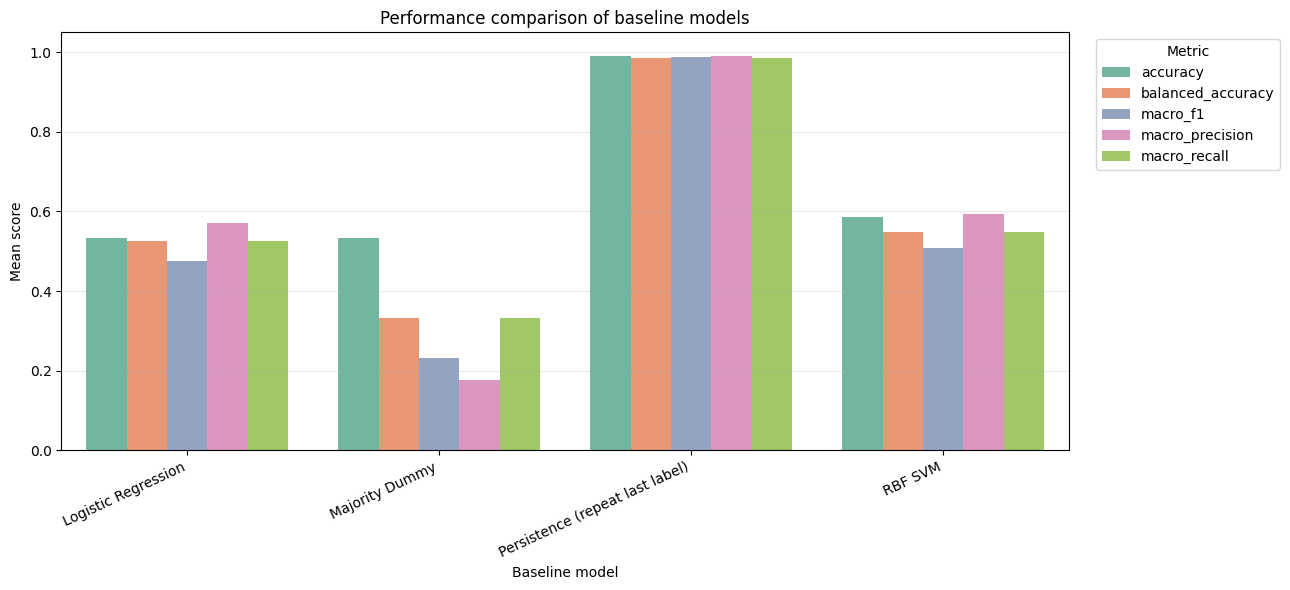

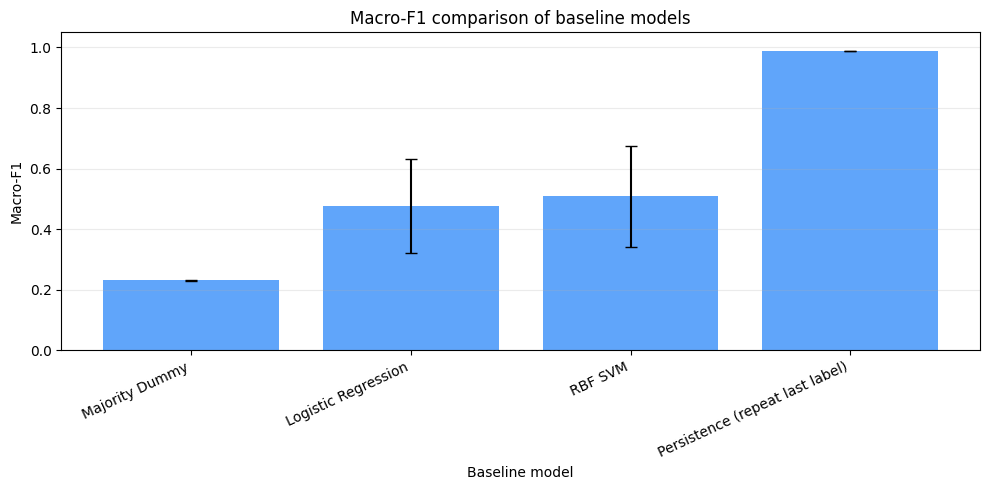

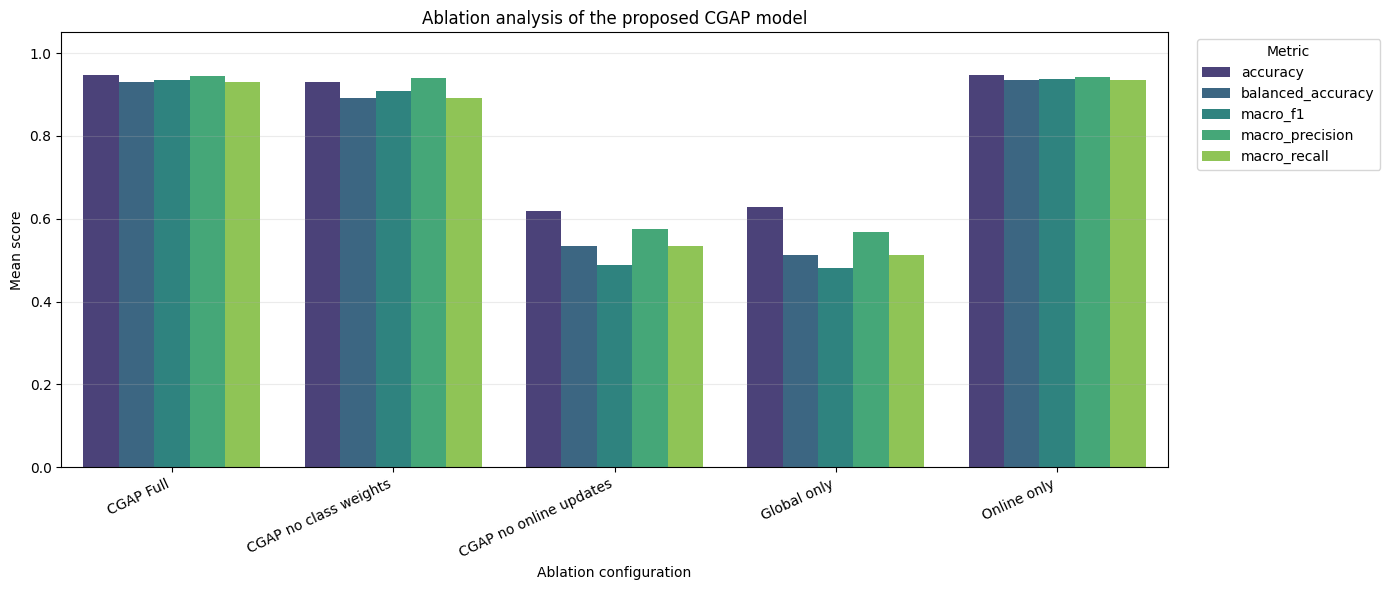

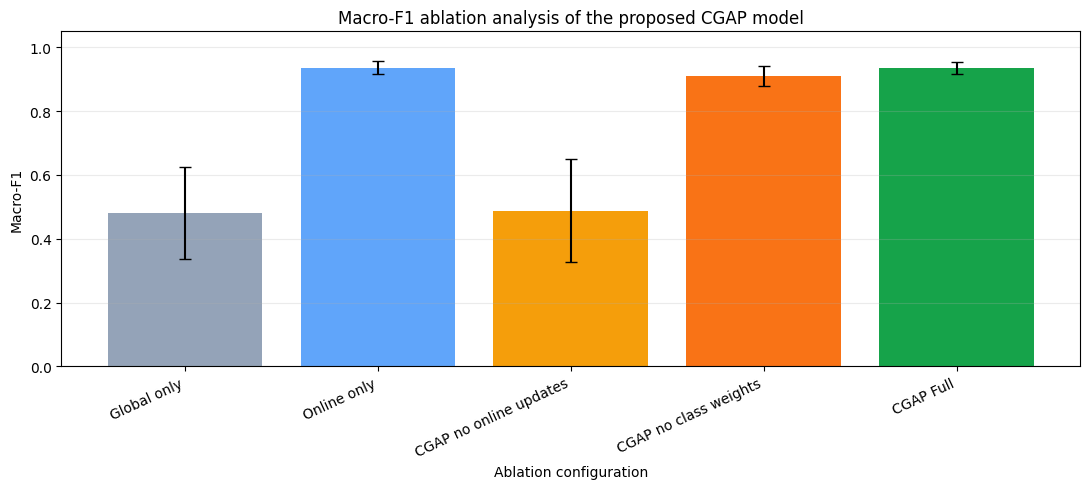

Prediction file not found; confusion matrices were skipped.

All files saved to: /kaggle/working/cgap_separate_figures
ZIP created: /kaggle/working/cgap_separate_baseline_ablation_figures.zip
ZIP size: 0.54 MB

Files inside ZIP:
baseline_macro_f1.png
ablation_macro_f1.png
ablation_summary.csv
baseline_metric_comparison.png
baseline_summary.csv
ablation_metric_comparison.png


/kaggle/working/cgap_separate_baseline_ablation_figures.zip

In [5]:
# ============================================================
# SEPARATE BASELINE AND ABLATION FIGURES
# ============================================================

from pathlib import Path
import zipfile
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from IPython.display import FileLink, display

# ------------------------------------------------------------
# 1. Locate cgap_loso_outputs in Kaggle input
# ------------------------------------------------------------

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")

existing_dirs = list(INPUT_ROOT.rglob("cgap_loso_outputs"))

if existing_dirs:
    BASE = existing_dirs[0]
    print("Using input folder:", BASE)

else:
    zip_files = list(INPUT_ROOT.rglob("cgap_loso_outputs.zip"))

    if not zip_files:
        raise FileNotFoundError(
            "Could not find cgap_loso_outputs or cgap_loso_outputs.zip "
            "under /kaggle/input."
        )

    zip_path = zip_files[0]
    extract_root = WORK_ROOT / "cgap_loso_extracted"

    if extract_root.exists():
        shutil.rmtree(extract_root)

    extract_root.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(extract_root)

    extracted_dirs = list(extract_root.rglob("cgap_loso_outputs"))

    if not extracted_dirs:
        raise FileNotFoundError(
            "The ZIP was extracted, but cgap_loso_outputs was not found."
        )

    BASE = extracted_dirs[0]
    print("Extracted folder:", BASE)

TABLE_DIR = BASE / "tables"
FIG_DIR = WORK_ROOT / "cgap_separate_figures"

FIG_DIR.mkdir(parents=True, exist_ok=True)

RAW_FILE = TABLE_DIR / "raw_fold_results.csv"
PRED_FILE = TABLE_DIR / "window_level_predictions.csv.gz"

if not RAW_FILE.exists():
    raise FileNotFoundError(f"Missing: {RAW_FILE}")

results = pd.read_csv(RAW_FILE)

print("Loaded:", RAW_FILE)
print("Rows:", len(results))
print("Models:", sorted(results["model"].unique()))


# ------------------------------------------------------------
# 2. Define model groups
# ------------------------------------------------------------

BASELINE_MODELS = [
    "Majority Dummy",
    "Logistic Regression",
    "RBF SVM",
    "Persistence (repeat last label)",
]

ABLATION_MODELS = [
    "Global only",
    "Online only",
    "CGAP no online updates",
    "CGAP no class weights",
    "CGAP Full",
]

METRICS = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "macro_precision",
    "macro_recall",
]


# Keep only models that actually exist
BASELINE_MODELS = [
    m for m in BASELINE_MODELS
    if m in results["model"].unique()
]

ABLATION_MODELS = [
    m for m in ABLATION_MODELS
    if m in results["model"].unique()
]

print("Baseline models:", BASELINE_MODELS)
print("Ablation models:", ABLATION_MODELS)


# ------------------------------------------------------------
# 3. Create summary tables
# ------------------------------------------------------------

baseline_summary = (
    results[results["model"].isin(BASELINE_MODELS)]
    .groupby("model")[METRICS]
    .agg(["mean", "std"])
    .round(4)
)

ablation_summary = (
    results[results["model"].isin(ABLATION_MODELS)]
    .groupby("model")[METRICS]
    .agg(["mean", "std"])
    .round(4)
)

baseline_summary.to_csv(
    FIG_DIR / "baseline_summary.csv"
)

ablation_summary.to_csv(
    FIG_DIR / "ablation_summary.csv"
)

print("\nBaseline summary:")
display(baseline_summary)

print("\nAblation summary:")
display(ablation_summary)


# ------------------------------------------------------------
# 4. Baseline metric comparison
# ------------------------------------------------------------

baseline_long = (
    results[results["model"].isin(BASELINE_MODELS)]
    .groupby("model")[METRICS]
    .mean()
    .reset_index()
    .melt(
        id_vars="model",
        value_vars=METRICS,
        var_name="metric",
        value_name="score"
    )
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=baseline_long,
    x="model",
    y="score",
    hue="metric",
    palette="Set2"
)

plt.ylim(0, 1.05)
plt.xlabel("Baseline model")
plt.ylabel("Mean score")
plt.title("Performance comparison of baseline models")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "baseline_metric_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 5. Baseline macro-F1 plot
# ------------------------------------------------------------

baseline_f1 = (
    results[results["model"].isin(BASELINE_MODELS)]
    .groupby("model")["macro_f1"]
    .agg(["mean", "std"])
    .reindex(BASELINE_MODELS)
)

plt.figure(figsize=(10, 5))

plt.bar(
    baseline_f1.index,
    baseline_f1["mean"],
    yerr=baseline_f1["std"].fillna(0),
    capsize=4,
    color="#60a5fa"
)

plt.ylim(0, 1.05)
plt.ylabel("Macro-F1")
plt.xlabel("Baseline model")
plt.title("Macro-F1 comparison of baseline models")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "baseline_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 6. Ablation metric comparison
# ------------------------------------------------------------

ablation_long = (
    results[results["model"].isin(ABLATION_MODELS)]
    .groupby("model")[METRICS]
    .mean()
    .reset_index()
    .melt(
        id_vars="model",
        value_vars=METRICS,
        var_name="metric",
        value_name="score"
    )
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=ablation_long,
    x="model",
    y="score",
    hue="metric",
    palette="viridis"
)

plt.ylim(0, 1.05)
plt.xlabel("Ablation configuration")
plt.ylabel("Mean score")
plt.title("Ablation analysis of the proposed CGAP model")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "ablation_metric_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 7. Ablation macro-F1 plot
# ------------------------------------------------------------

ablation_f1 = (
    results[results["model"].isin(ABLATION_MODELS)]
    .groupby("model")["macro_f1"]
    .agg(["mean", "std"])
    .reindex(ABLATION_MODELS)
)

plt.figure(figsize=(11, 5))

colors = [
    "#94a3b8",
    "#60a5fa",
    "#f59e0b",
    "#f97316",
    "#16a34a",
][:len(ablation_f1)]

plt.bar(
    ablation_f1.index,
    ablation_f1["mean"],
    yerr=ablation_f1["std"].fillna(0),
    capsize=4,
    color=colors
)

plt.ylim(0, 1.05)
plt.ylabel("Macro-F1")
plt.xlabel("Ablation configuration")
plt.title("Macro-F1 ablation analysis of the proposed CGAP model")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "ablation_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 8. Separate confusion matrices
# ------------------------------------------------------------

if PRED_FILE.exists():

    predictions = pd.read_csv(PRED_FILE)

    classes = [
        "baseline",
        "stress",
        "amusement"
    ]

    all_plot_models = BASELINE_MODELS + ABLATION_MODELS

    for model_name in all_plot_models:

        model_data = predictions[
            predictions["model"] == model_name
        ].copy()

        if model_data.empty:
            continue

        cm = confusion_matrix(
            model_data["y_true"],
            model_data["y_pred"],
            labels=classes,
            normalize="true"
        )

        plt.figure(figsize=(5.5, 5))

        sns.heatmap(
            cm,
            annot=True,
            fmt=".2f",
            cmap="Blues",
            vmin=0,
            vmax=1,
            xticklabels=classes,
            yticklabels=classes
        )

        plt.xlabel("Predicted class")
        plt.ylabel("True class")
        plt.title(f"Normalised confusion matrix: {model_name}")
        plt.tight_layout()

        safe_name = (
            model_name
            .lower()
            .replace(" ", "_")
            .replace("(", "")
            .replace(")", "")
        )

        plt.savefig(
            FIG_DIR / f"confusion_{safe_name}.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.close()

    print("Separate confusion matrices created.")

else:
    print("Prediction file not found; confusion matrices were skipped.")


# ------------------------------------------------------------
# 9. Create ZIP file
# ------------------------------------------------------------

ZIP_PATH = WORK_ROOT / "cgap_separate_baseline_ablation_figures.zip"

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file_path in FIG_DIR.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                arcname=file_path.relative_to(FIG_DIR)
            )

print("\nAll files saved to:", FIG_DIR)
print("ZIP created:", ZIP_PATH)
print("ZIP size:", round(ZIP_PATH.stat().st_size / 1024 / 1024, 2), "MB")

print("\nFiles inside ZIP:")
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for name in archive.namelist():
        print(name)

display(FileLink(str(ZIP_PATH)))

In [1]:
"""
CGAP on WESAD - POPULATION-LEVEL SHAP (all participants, leakage-free). Kaggle script.

What "population level" means here
  ONE CGAP model (global ExtraTrees branch + online SGD branch, fused) is fitted on ALL participants
  (S2..S17 present in the data, normally 15) and explained on a sample drawn EQUALLY from every
  participant. Importance is summarised with the PARTICIPANT as the unit: mean |SHAP| per participant,
  then mean, SD and bootstrap 95% CI across participants. No participant range such as S1-S11 is assumed:
  the script uses every S<n>_windows.csv it finds and prints exactly which participants it used.

Honest scope
  * This explains the DEPLOYED population model on windows it was trained on. It describes what the model
    uses; it is not an out-of-sample generalisation test (that is the leave-one-subject-out SHAP script).
  * SHAP shows model behaviour, not causal physiology.
  * Branches use different scales: global = probability, online = log-odds. Only the FUSED explanation
    (probability scale, additive by construction, checked) mixes both. Never add the two branch values.

Leakage guard: subject / window / label / label_id and any metadata or label-derived column are excluded and asserted.
Hyper-parameters: the most frequently selected CGAP settings from kaggle_cgap_full_loso_pipeline.py
(selected_checkpoint.csv) if found, else defaults (reported).

Outputs: /kaggle/working/cgap_shap_population/{figures,tables}
Env: CGAP_FAST=1 for a quick smoke test.
"""
import os, re, sys, json, warnings
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

try:
    import shap
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

from scipy.stats import spearmanr
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ============================================================================ CONFIG
FAST = os.environ.get("CGAP_FAST") == "1"
SEED = 42
N_TREES = 30 if FAST else 80
DEFAULT_LAMBDA, DEFAULT_SGD_ALPHA, DEFAULT_TREE = 0.50, 0.001, ("sqrt", 2)
BRANCH_PER_PARTICIPANT = 20 if FAST else 50      # windows explained per participant (Tree/Linear SHAP)
BRANCH_BACKGROUND_PER_PARTICIPANT = 5 if FAST else 8
FUSED_PER_PARTICIPANT = 15 if FAST else 30       # windows explained per participant (fused permutation SHAP)
FUSED_BACKGROUND_PER_PARTICIPANT = 3 if FAST else 4
FUSED_PERMUTATIONS = 2 if FAST else 4
N_BOOT = 1000 if FAST else 5000
TOP_N = 20
HEATMAP_TOP = 15
DEPENDENCE_TOP = 3
ADDITIVITY_TOL = 0.02

INPUT_ROOT = Path(os.environ.get("CGAP_INPUT", "/kaggle/input"))
_work = Path(os.environ.get("CGAP_WORK", "/kaggle/working"))
WORK_DIR = _work if _work.exists() else Path("./outputs")
OUT = WORK_DIR / "cgap_shap_population"
FIG, TAB = OUT / "figures", OUT / "tables"
for d in (OUT, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)
print("Input:", INPUT_ROOT, "| Output:", OUT, "| SHAP", shap.__version__, "| fast:", FAST, flush=True)

# ============================================================================ DATA + LEAKAGE GUARD
def find_subject_files(root=INPUT_ROOT):
    found = {}
    for p in sorted(Path(root).rglob("S*_windows.csv")):
        if re.fullmatch(r"S\d+_windows", p.stem) and p.name not in found:
            found[p.name] = p
    return sorted(found.values(), key=lambda p: int(re.findall(r"\d+", p.stem)[0]))

files = find_subject_files()
if not files:
    raise FileNotFoundError(f"No S<n>_windows.csv under {INPUT_ROOT}. Add the dataset as an input.")
parts = []
for p in files:
    t = pd.read_csv(p)
    if "subject" not in t.columns:
        t["subject"] = p.stem.split("_")[0]
    parts.append(t)
df = pd.concat(parts, ignore_index=True)
LABEL_COL = next(c for c in ["label", "state", "target", "class", "y"] if c in df.columns)
ORDER_COL = next((c for c in ["window", "window_idx", "window_index", "timestamp", "start_time"] if c in df.columns), None)

META_EXACT = {"subject", "participant", "participant_id", "user_id", "label", "label_id", "state", "target", "class",
              "y", "window", "window_idx", "window_index", "timestamp", "start_time", "end_time", "source_file",
              "fold", "seed", "index", "unnamed: 0"}
META_PATTERN = re.compile(r"(^|_)(label|labels|target|class|state|subject|participant|fold|seed)(_|$)|(^|_)id$", re.I)
is_meta = lambda c: c.lower() in META_EXACT or bool(META_PATTERN.search(c))

FEATURES = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and not is_meta(c)]
EXCLUDED = [c for c in df.columns if c not in FEATURES]
for bad in ("subject", "window", "label", "label_id"):
    assert bad not in FEATURES, f"LEAKAGE GUARD FAILED: {bad} in features"
assert FEATURES
NF = len(FEATURES)
print("EXCLUDED:", EXCLUDED, f"\nFEATURES ({NF}):", FEATURES, flush=True)
pd.DataFrame({"excluded_column": EXCLUDED}).to_csv(TAB / "excluded_columns.csv", index=False)
pd.DataFrame({"feature": FEATURES}).to_csv(TAB / "features_used.csv", index=False)

df["subject"] = df["subject"].astype(str)
df = df.sort_values(["subject"] + ([ORDER_COL] if ORDER_COL else [])).reset_index(drop=True)
nat = lambda s: int(re.findall(r"\d+", s)[0]) if re.findall(r"\d+", s) else 0
SUBJECTS = sorted(df["subject"].unique(), key=nat)
counts = df.groupby("subject").size().reindex(SUBJECTS)
print(f"\nPOPULATION = {len(SUBJECTS)} participants: {SUBJECTS}")
print("Windows per participant:", counts.to_dict(), flush=True)
if len(SUBJECTS) != 15:
    print(f"WARNING: expected 15 participants for the full population, found {len(SUBJECTS)}. "
          "Check that every S<n>_windows.csv is attached to the notebook before reporting population-level results.")
counts.rename("n_windows").rename_axis("participant").reset_index().to_csv(TAB / "participants_used.csv", index=False)

X_all = df[FEATURES].replace([np.inf, -np.inf], np.nan)
y_text = df[LABEL_COL].astype(str)
group_of = lambda f: f.split("_")[0]

# ============================================================================ POPULATION HYPER-PARAMETERS
def population_params():
    cands = []
    for root in (WORK_DIR, INPUT_ROOT):
        if Path(root).exists():
            cands += sorted(Path(root).rglob("selected_checkpoint.csv"))
    for path in cands:
        try:
            t = pd.read_csv(path)
            t = t[t["model"] == "CGAP"]
            if "held_out_subject" in t.columns and t["held_out_subject"].nunique() < 3:
                continue                       # a single-participant file is not a population summary
            sets = []
            for s in t["best_params"]:
                p = json.loads(s)
                sets.append((str(p["tree_max_features"]), int(p["tree_min_samples_leaf"]),
                             float(p["sgd_alpha"]), float(p["online_blend_weight"])))
            if not sets:
                continue
            (tmf, leaf, alpha, lam), n = Counter(sets).most_common(1)[0]
            tmf = float(tmf) if re.fullmatch(r"[0-9.]+", tmf) else tmf
            return {"tree": (tmf, leaf), "sgd_alpha": alpha, "lambda": lam,
                    "source": f"{path} (most frequent of {len(sets)} nested-tuning selections; chosen {n}x)"}
        except Exception as e:
            print("  could not parse", path, e)
    return None

cfg = population_params()
if cfg is None:
    cfg = {"tree": DEFAULT_TREE, "sgd_alpha": DEFAULT_SGD_ALPHA, "lambda": DEFAULT_LAMBDA, "source": "defaults"}
    print("NOTE: no nested-tuning output found; DEFAULT parameters used (lambda=0.5). "
          "Run kaggle_cgap_full_loso_pipeline.py first for tuned values.")
else:
    print("Parameters:", cfg)
lam = cfg["lambda"]

# ============================================================================ FIT THE POPULATION MODEL (all participants)
enc = LabelEncoder().fit(y_text)
CLASSES = list(enc.classes_)
K = len(CLASSES)
y_all = enc.transform(y_text)

gm = make_pipeline(SimpleImputer(strategy="median"),
                   ExtraTreesClassifier(n_estimators=N_TREES, max_features=cfg["tree"][0], min_samples_leaf=cfg["tree"][1],
                                        class_weight="balanced", n_jobs=-1, random_state=SEED)).fit(X_all, y_all)
prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
Z_all = prep.fit_transform(X_all)
cnt = np.bincount(y_all, minlength=K)
cw = {k: len(y_all) / (K * cnt[k]) for k in range(K)}
sgd = SGDClassifier(loss="log_loss", alpha=cfg["sgd_alpha"], max_iter=1000, tol=1e-3, random_state=SEED)
sgd.fit(Z_all, y_all, sample_weight=np.array([cw[k] for k in y_all]))

p_global = lambda A: gm.predict_proba(pd.DataFrame(A, columns=FEATURES))
p_online = lambda A: sgd.predict_proba(prep.transform(pd.DataFrame(A, columns=FEATURES)))
p_fused = lambda A: (1.0 - lam) * p_global(A) + lam * p_online(A)
fp = p_fused(X_all.to_numpy(float)).argmax(axis=1)
print(f"Population model (IN-SAMPLE, not a generalisation estimate): accuracy={accuracy_score(y_all, fp):.3f} "
      f"macro-F1={f1_score(y_all, fp, average='macro'):.3f}", flush=True)

# ============================================================================ EQUAL-PER-PARTICIPANT SAMPLES
rng = np.random.default_rng(SEED)
rows_by_subj = {s: np.flatnonzero((df["subject"] == s).to_numpy()) for s in SUBJECTS}

def sample_rows(per, replace_ok=False):
    idx = []
    for s in SUBJECTS:
        r = rows_by_subj[s]
        idx.append(np.sort(rng.choice(r, size=min(per, len(r)), replace=False)))
    return idx            # list aligned with SUBJECTS

br_idx = sample_rows(BRANCH_PER_PARTICIPANT)
fu_idx = sample_rows(FUSED_PER_PARTICIPANT)
bg_br = np.concatenate(sample_rows(BRANCH_BACKGROUND_PER_PARTICIPANT))
bg_fu = np.concatenate(sample_rows(FUSED_BACKGROUND_PER_PARTICIPANT))
br_rows = np.concatenate(br_idx); br_owner = np.concatenate([[s] * len(i) for s, i in zip(SUBJECTS, br_idx)])
fu_rows = np.concatenate(fu_idx); fu_owner = np.concatenate([[s] * len(i) for s, i in zip(SUBJECTS, fu_idx)])
pd.DataFrame({"participant": SUBJECTS, "branch_windows": [len(i) for i in br_idx],
              "fused_windows": [len(i) for i in fu_idx]}).to_csv(TAB / "explained_sample_sizes.csv", index=False)

Xn = X_all.to_numpy(float)
X_br, X_fu = Xn[br_rows], Xn[fu_rows]
X_br_imp = gm[0].transform(pd.DataFrame(X_br, columns=FEATURES))
Z_br = prep.transform(pd.DataFrame(X_br, columns=FEATURES))
Xbg_imp = gm[0].transform(pd.DataFrame(Xn[bg_br], columns=FEATURES))
Zbg = prep.transform(pd.DataFrame(Xn[bg_br], columns=FEATURES))

def cls_values(sv, k):
    if isinstance(sv, list):
        return np.asarray(sv[k])
    a = np.asarray(sv)
    if a.ndim == 3:
        return a[:, :, k] if a.shape[1] == NF else a[k]
    if a.ndim == 2:
        return a
    raise ValueError(f"Unrecognised SHAP shape {a.shape}")

print(f"\nGlobal branch: TreeExplainer on {len(br_rows)} windows (probability scale) ...", flush=True)
tex = shap.TreeExplainer(gm[-1], data=Xbg_imp, feature_perturbation="interventional", model_output="probability")
g_raw = tex.shap_values(X_br_imp)
G = np.stack([cls_values(g_raw, k) for k in range(K)])                 # (K, n, f)
g_base = np.asarray(tex.expected_value).reshape(-1)

print(f"Online branch: LinearExplainer on {len(br_rows)} windows (log-odds scale) ...", flush=True)
lin = shap.LinearExplainer(sgd, Zbg, feature_perturbation="interventional")
O = np.stack([cls_values(lin.shap_values(Z_br), k) for k in range(K)])
o_base = np.asarray(lin.expected_value).reshape(-1)

print(f"Fused CGAP: permutation explainer on {len(fu_rows)} windows ({FUSED_PERMUTATIONS} permutations) ...", flush=True)
masker = shap.maskers.Independent(Xn[bg_fu], max_samples=len(bg_fu))
expl = shap.Explainer(p_fused, masker, algorithm="permutation", seed=SEED)
sv = expl(X_fu, max_evals=FUSED_PERMUTATIONS * (2 * NF + 1))
FV = np.asarray(sv.values)                                              # (n, f, K)
f_base = np.asarray(sv.base_values)                                     # (n, K)
f_target = p_fused(X_fu)
recon = f_base + FV.sum(axis=1)
add_mae, add_max = float(np.mean(np.abs(f_target - recon))), float(np.max(np.abs(f_target - recon)))
print(f"Fused additivity: MAE={add_mae:.2e}, max={add_max:.2e} (tolerance {ADDITIVITY_TOL})", flush=True)
if add_mae > ADDITIVITY_TOL:
    print("WARNING: additivity above tolerance; raise FUSED_PERMUTATIONS before reporting fused SHAP.")
F = np.transpose(FV, (2, 0, 1))                                         # (K, n, f)
pd.DataFrame([{"class": c, "additivity_mae": float(np.mean(np.abs(f_target[:, k] - recon[:, k]))),
               "additivity_max_abs_error": float(np.max(np.abs(f_target[:, k] - recon[:, k])))}
              for k, c in enumerate(CLASSES)]).to_csv(TAB / "fused_additivity_check.csv", index=False)

# ============================================================================ PARTICIPANT-LEVEL IMPORTANCE (+ bootstrap CI)
def per_participant(arr, owner):
    """arr (K, n, f) -> DataFrame features x participants with mean |SHAP| (mean over classes)."""
    out = {}
    for s in SUBJECTS:
        m = owner == s
        out[s] = np.abs(arr[:, m, :]).mean(axis=(0, 1))
    return pd.DataFrame(out, index=FEATURES)

def per_participant_class(arr, owner, k):
    return pd.DataFrame({s: np.abs(arr[k, owner == s, :]).mean(axis=0) for s in SUBJECTS}, index=FEATURES)

def boot_ci(mat, n=N_BOOT, seed=1):
    r = np.random.default_rng(seed)
    P = mat.shape[1]
    means = np.stack([mat[:, r.integers(0, P, P)].mean(axis=1) for _ in range(n)], axis=1)
    return np.quantile(means, 0.025, axis=1), np.quantile(means, 0.975, axis=1)

IMP = {"global": per_participant(G, br_owner), "online": per_participant(O, br_owner), "fused": per_participant(F, fu_owner)}
AGG = {}
for b, t in IMP.items():
    lo, hi = boot_ci(t.to_numpy())
    a = pd.DataFrame({"mean_across_participants": t.mean(axis=1), "sd_across_participants": t.std(axis=1, ddof=1),
                      "ci95_boot_low": lo, "ci95_boot_high": hi, "sensor_group": [group_of(f) for f in FEATURES]}, index=FEATURES)
    a["rank"] = a["mean_across_participants"].rank(ascending=False).astype(int)
    AGG[b] = a.sort_values("mean_across_participants", ascending=False)
    AGG[b].rename_axis("feature").reset_index().to_csv(TAB / f"population_importance_{b}.csv", index=False)
    t.to_csv(TAB / f"per_participant_importance_{b}.csv")
IMPC = {c: per_participant_class(F, fu_owner, k) for k, c in enumerate(CLASSES)}
for c, t in IMPC.items():
    t.mean(axis=1).rename("mean_abs_shap_fused").rename_axis("feature").reset_index().sort_values(
        "mean_abs_shap_fused", ascending=False).to_csv(TAB / f"population_importance_fused_class_{c}.csv", index=False)

# direction of effect (fused): Spearman(feature value, SHAP value) per class, on the pooled sample
dirs = pd.DataFrame({c: [spearmanr(X_fu[:, j], F[k][:, j]).correlation for j in range(NF)] for k, c in enumerate(CLASSES)},
                    index=FEATURES).fillna(0.0)
dirs.rename_axis("feature").reset_index().to_csv(TAB / "direction_of_effect_fused_spearman.csv", index=False)

# stability: do participants agree with the population ranking?
mean_imp = IMP["fused"].mean(axis=1)
cons = pd.DataFrame({"participant": SUBJECTS, "spearman_vs_population_ranking":
                     [spearmanr(IMP["fused"][s], mean_imp).correlation for s in SUBJECTS]})
cons.to_csv(TAB / "participant_agreement_with_population_ranking.csv", index=False)

# agreement with the leave-one-subject-out SHAP (if that script was run)
for cand in list(WORK_DIR.rglob("aggregate_importance_fused.csv")) + list(INPUT_ROOT.rglob("aggregate_importance_fused.csv")):
    try:
        lo_t = pd.read_csv(cand).set_index("feature")["mean_across_participants"].reindex(FEATURES)
        rho = spearmanr(mean_imp, lo_t).correlation
        pd.DataFrame([{"loso_file": str(cand), "spearman_population_vs_loso_fused_importance": rho}]).to_csv(
            TAB / "agreement_population_vs_loso.csv", index=False)
        print(f"Agreement with LOSO SHAP ranking (Spearman): {rho:.3f}")
        break
    except Exception:
        continue

pd.DataFrame([{"n_participants": len(SUBJECTS), "participants": ",".join(SUBJECTS), "lambda": lam,
               "sgd_alpha": cfg["sgd_alpha"], "tree": str(cfg["tree"]), "param_source": cfg["source"],
               "fused_additivity_mae": add_mae, "fused_additivity_max_abs": add_max,
               "in_sample_accuracy": accuracy_score(y_all, fp),
               "in_sample_macro_f1": f1_score(y_all, fp, average="macro")}]).to_csv(TAB / "population_run_summary.csv", index=False)

# ============================================================================ FIGURES
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.close("all")
    print("  saved", name, flush=True)

tail = f"population of {len(SUBJECTS)} participants"

def bar(branch, colour, label, name):
    a = AGG[branch].head(TOP_N).iloc[::-1]
    err = np.vstack([(a["mean_across_participants"] - a["ci95_boot_low"]).clip(lower=0),
                     (a["ci95_boot_high"] - a["mean_across_participants"]).clip(lower=0)])
    plt.figure(figsize=(8.8, 7.2))
    plt.barh(a.index, a["mean_across_participants"], xerr=err, color=colour, capsize=2)
    plt.xlabel("Mean |SHAP| (mean over participants, 95% bootstrap CI across participants)")
    plt.title(f"{label}: {tail}")
    plt.grid(axis="x", alpha=.25)
    savefig(name)

bar("global", "#2b6cb0", "Global branch (ExtraTrees, probability scale)", "POP_bar_global_branch")
bar("online", "#c05621", "Online branch (SGD, log-odds scale)", "POP_bar_online_branch")
bar("fused", "#2f855a", "Fused CGAP (probability scale)", "POP_bar_fused_cgap")

# relative importance shares across branches
sh = pd.DataFrame({b: AGG[b]["mean_across_participants"] / AGG[b]["mean_across_participants"].sum() for b in ("global", "online", "fused")})
st = sh.loc[AGG["fused"].head(TOP_N).index].iloc[::-1]
yy = np.arange(len(st))
plt.figure(figsize=(9, 7.5))
for j, (b, col) in enumerate([("global", "#2b6cb0"), ("online", "#c05621"), ("fused", "#2f855a")]):
    plt.barh(yy + (j - 1) * .27, st[b], height=.26, label=b, color=col)
plt.yticks(yy, st.index); plt.legend(); plt.grid(axis="x", alpha=.25)
plt.xlabel("Share of total mean |SHAP| (branches have different scales; only shares are comparable)")
plt.title(f"Relative feature importance by branch ({tail})")
savefig("POP_branch_comparison_relative_importance")

# sensor groups with participant bootstrap CI
grp_t = IMP["fused"].groupby([group_of(f) for f in FEATURES]).sum()
glo, ghi = boot_ci(grp_t.to_numpy())
gmn = grp_t.mean(axis=1)
o_ = gmn.sort_values().index
plt.figure(figsize=(6.8, 4.2))
plt.barh(o_, gmn.loc[o_], xerr=np.vstack([(gmn - glo).loc[o_].clip(lower=0), (ghi - gmn).loc[o_].clip(lower=0)]),
         color="#2f855a", capsize=3)
plt.xlabel("Summed mean |SHAP| of the group's features (95% bootstrap CI across participants)")
plt.title(f"Fused CGAP: importance by sensor group ({tail})"); plt.grid(axis="x", alpha=.25)
savefig("POP_sensor_group_fused_cgap")
pd.DataFrame({"mean": gmn, "ci95_low": glo, "ci95_high": ghi}, index=grp_t.index).rename_axis("sensor_group").to_csv(
    TAB / "sensor_group_importance_fused.csv")

# class x feature heatmap
order_f = AGG["fused"].head(HEATMAP_TOP).index.tolist()
H = np.stack([IMPC[c].mean(axis=1).loc[order_f].to_numpy() for c in CLASSES], axis=1)
plt.figure(figsize=(1.3 * K + 4, .38 * len(order_f) + 2))
plt.imshow(H, aspect="auto", cmap="Blues"); plt.colorbar(label="Mean |SHAP| (participant mean)")
plt.xticks(range(K), CLASSES); plt.yticks(range(len(order_f)), order_f)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        plt.text(j, i, f"{H[i, j]:.3f}", ha="center", va="center", fontsize=7)
plt.title(f"Fused CGAP: class-wise importance ({tail})")
savefig("POP_heatmap_fused_cgap_class_by_feature")

# direction-of-effect heatmap
D = dirs.loc[order_f]
plt.figure(figsize=(1.3 * K + 4, .38 * len(order_f) + 2))
plt.imshow(D.values, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar(label="Spearman(feature value, SHAP)")
plt.xticks(range(K), CLASSES); plt.yticks(range(len(order_f)), order_f)
for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        plt.text(j, i, f"{D.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Direction of effect (fused CGAP): + = higher value raises the class probability")
savefig("POP_direction_of_effect_fused_cgap")

# participant x feature heatmap and agreement
M = IMP["fused"].loc[order_f].T.loc[SUBJECTS]
plt.figure(figsize=(.55 * len(order_f) + 3, .42 * len(SUBJECTS) + 2.5))
plt.imshow(M.values, aspect="auto", cmap="viridis"); plt.colorbar(label="Mean |SHAP|")
plt.xticks(range(len(order_f)), order_f, rotation=60, ha="right"); plt.yticks(range(len(SUBJECTS)), SUBJECTS)
plt.title("Fused CGAP: importance within each participant")
savefig("POP_participant_by_feature_heatmap_fused_cgap")
plt.figure(figsize=(8, 4.2))
plt.bar(cons["participant"], cons["spearman_vs_population_ranking"], color="#4a5568")
plt.ylim(min(0, cons["spearman_vs_population_ranking"].min()) - .05, 1.02); plt.xticks(rotation=45)
plt.ylabel("Spearman rho vs population ranking"); plt.grid(axis="y", alpha=.25)
plt.title("Does each participant agree with the population-level feature ranking?")
savefig("POP_participant_agreement_with_population_ranking")

# beeswarms (population = windows pooled across ALL participants, equal weight per participant)
def beeswarm(values, data, base, name, title):
    ex = shap.Explanation(values=values, base_values=np.full(len(values), base), data=data, feature_names=FEATURES)
    try:
        shap.plots.beeswarm(ex, max_display=TOP_N, show=False)
    except Exception:
        shap.summary_plot(values, data, feature_names=FEATURES, max_display=TOP_N, show=False)
    plt.title(title, fontsize=11)
    savefig(name)

for k, c in enumerate(CLASSES):
    beeswarm(G[k], X_br_imp, float(g_base[min(k, len(g_base) - 1)]), f"POP_beeswarm_global_branch_{c}",
             f"Global branch SHAP - class {c} ({tail})")
    beeswarm(O[k], X_br, float(o_base[min(k, len(o_base) - 1)]), f"POP_beeswarm_online_branch_{c}",
             f"Online branch SHAP (log-odds) - class {c} ({tail})")
    beeswarm(F[k], X_fu, float(f_base[:, k].mean()), f"POP_beeswarm_fused_cgap_{c}",
             f"Fused CGAP SHAP (probability) - class {c} ({tail})")

# dependence plots for the top fused features
for k, c in enumerate(CLASSES):
    for f in AGG["fused"].head(DEPENDENCE_TOP).index:
        j = FEATURES.index(f)
        plt.figure(figsize=(6.2, 4.6))
        sc = plt.scatter(X_fu[:, j], F[k][:, j], c=y_all[fu_rows], cmap="viridis", s=10, alpha=.7)
        plt.axhline(0, color="k", lw=.8)
        cb = plt.colorbar(sc, ticks=range(K)); cb.ax.set_yticklabels(CLASSES); cb.set_label("True class")
        plt.xlabel(f"{f} (raw value)"); plt.ylabel(f"SHAP value for class {c}")
        plt.title(f"Dependence: {f} -> {c} ({tail})", fontsize=10)
        savefig(f"POP_dependence_{f}_{c}")

# representative local explanations (median-confidence, correctly classified)
Tall = y_all[fu_rows]
rows_ex = []
for k, c in enumerate(CLASSES):
    hit = np.flatnonzero((Tall == k) & (f_target.argmax(axis=1) == k))
    if not len(hit):
        print(f"  no correct {c} window; waterfall skipped"); continue
    conf = f_target[hit, k]
    i = int(hit[np.argmin(np.abs(conf - np.median(conf)))])
    ex = shap.Explanation(values=FV[i, :, k], base_values=float(f_base[i, k]), data=X_fu[i], feature_names=FEATURES)
    shap.plots.waterfall(ex, max_display=15, show=False)
    plt.title(f"Fused CGAP local explanation - {c} (participant {fu_owner[i]}; median-confidence correct window)", fontsize=9)
    savefig(f"POP_waterfall_fused_cgap_{c}")
    rows_ex.append({"class": c, "participant": fu_owner[i], "predicted_probability": float(f_target[i, k])})
pd.DataFrame(rows_ex).to_csv(TAB / "waterfall_examples_selected.csv", index=False)

# ============================================================================ REPRODUCIBILITY
import sklearn, scipy
(OUT / "population_shap_metadata.json").write_text(json.dumps({
    "participants": SUBJECTS, "n_windows_total": int(len(df)), "classes": CLASSES, "features": FEATURES,
    "excluded_columns": EXCLUDED, "seed": SEED, "n_trees": N_TREES, "lambda": lam, "sgd_alpha": cfg["sgd_alpha"],
    "tree": [str(x) for x in cfg["tree"]], "param_source": cfg["source"],
    "branch_windows_per_participant": BRANCH_PER_PARTICIPANT, "fused_windows_per_participant": FUSED_PER_PARTICIPANT,
    "fused_permutations": FUSED_PERMUTATIONS, "bootstrap_resamples_of_participants": N_BOOT,
    "scales": {"global": "probability", "online": "log-odds (margin)", "fused": "probability"},
    "software": {"shap": shap.__version__, "sklearn": sklearn.__version__, "numpy": np.__version__,
                 "pandas": pd.__version__, "scipy": scipy.__version__},
    "caveats": ["Population model is fitted on all participants and explained on windows it was trained on: "
                "descriptive of the model, not an out-of-sample generalisation estimate.",
                "SHAP explains model behaviour, not causal physiology.",
                "Feature-value/SHAP direction (Spearman) is associational."],
}, indent=2, default=str))
try:
    import shutil
    shutil.copy(__file__, OUT / Path(__file__).name)
except Exception:
    pass
print("\nDONE. Outputs:", OUT)
for p in sorted(FIG.glob("*.png")):
    print("  ", p.name)

Input: /kaggle/input | Output: /kaggle/working/cgap_shap_population | SHAP 0.52.0 | fast: False
EXCLUDED: ['subject', 'window', 'label', 'label_id'] 
FEATURES (24): ['acc_1_mean', 'acc_1_std', 'acc_1_min', 'acc_1_max', 'acc_2_mean', 'acc_2_std', 'acc_2_min', 'acc_2_max', 'acc_3_mean', 'acc_3_std', 'acc_3_min', 'acc_3_max', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'temp_mean', 'temp_std', 'temp_min', 'temp_max']

POPULATION = 15 participants: ['S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17']
Windows per participant: {'S2': 210, 'S3': 213, 'S4': 214, 'S5': 218, 'S6': 219, 'S7': 218, 'S8': 218, 'S9': 217, 'S10': 224, 'S11': 220, 'S13': 220, 'S14': 221, 'S15': 222, 'S16': 222, 'S17': 225}
Parameters: {'tree': (0.8, 2), 'sgd_alpha': 0.0001, 'lambda': 0.75, 'source': '/kaggle/input/datasets/kabil08/loso-op/cgap_loso_outputs/selected_checkpoint.csv (most frequent of 45 nested-tuning selections; ch

Background dataset has 120 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=120 when initializing the masker.
 98%|===================| 2203/2250 [00:39<00:00]        

Online branch: LinearExplainer on 750 windows (log-odds scale) ...


Background dataset has 120 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=120 when initializing the masker.


Fused CGAP: permutation explainer on 450 windows (4 permutations) ...


PermutationExplainer explainer: 451it [01:47,  4.04it/s]                         

Fused additivity: MAE=2.60e-16, max=1.78e-15 (tolerance 0.02)


  saved POP_bar_global_branch
  saved POP_bar_online_branch
  saved POP_bar_fused_cgap
  saved POP_branch_comparison_relative_importance
  saved POP_sensor_group_fused_cgap
  saved POP_heatmap_fused_cgap_class_by_feature
  saved POP_direction_of_effect_fused_cgap
  saved POP_participant_by_feature_heatmap_fused_cgap
  saved POP_participant_agreement_with_population_ranking
  saved POP_beeswarm_global_branch_amusement
  saved POP_beeswarm_online_branch_amusement
  saved POP_beeswarm_fused_cgap_amusement
  saved POP_beeswarm_global_branch_baseline
  saved POP_beeswarm_online_branch_baseline
  saved POP_beeswarm_fused_cgap_baseline
  saved POP_beeswarm_global_branch_stress
  saved POP_beeswarm_online_branch_stress
  saved POP_beeswarm_fused_cgap_stress
  saved POP_dependence_acc_3_min_amusement
  saved POP_dependence_acc_1_min_amusement
  saved POP_dependence_acc_1_mean_amusement
  saved POP_dependence_acc_3_min_baseline
  saved POP_dependence_acc_1_min_baseline
  saved POP_dependence_acc

In [3]:
import os
import shutil
from pathlib import Path

# Source folder
source_dir = Path("/kaggle/working/cgap_shap_population")

# Output ZIP file
zip_path = "/kaggle/working/cgap_shap_population.zip"

# Verify source exists
if not source_dir.exists():
    raise FileNotFoundError(f"Folder not found: {source_dir}")

# Create ZIP archive
shutil.make_archive(
    base_name=zip_path.replace(".zip", ""),
    format="zip",
    root_dir=source_dir.parent,
    base_dir=source_dir.name
)

# Display results
size_mb = os.path.getsize(zip_path) / (1024 * 1024)

print("ZIP created successfully!")
print(f"File: {zip_path}")
print(f"Size: {size_mb:.2f} MB")
print("\nZIP contents:")

import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    for name in z.namelist():
        print(name)

print("\nDownload using the Kaggle Output panel:")
print(zip_path)

SystemExit: Nothing to zip under /kaggle/working. Run the analysis scripts first.